# 03 · Baseline models and error diagnostics

# Part A · Rossmann daily store sales

In [1]:
import json, hashlib, warnings, platform, sys, os, gc, gzip, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from scipy import stats
from IPython.display import Image


from importlib.metadata import version as package_version

PACKAGE_VERSIONS = {
    name: package_version(name)
    for name in [
        "numpy",
        "pandas",
        "scipy",
        "scikit-learn",
        "lightgbm",
        "xgboost",
        "catboost",
        "torch",
        "matplotlib",
        "cloudpickle",
    ]
}

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option(
    "display.max_rows",
    None,
    "display.max_columns",
    None,
    "display.max_colwidth",
    None,
    "display.width",
    220,
    "display.float_format",
    lambda v: f"{0.0 if abs(v)<0.00005 else v:,.4f}",
)

ROOT = Path("..").resolve()
RAW = ROOT / "dataset" / "raw"
INTERIM, PROCESSED, SPLITS = (
    ROOT / "outputs" / "data" / "interim",
    ROOT / "outputs" / "data" / "processed",
    ROOT / "outputs" / "data" / "splits",
)
TABLES, FIGURES, MANIFESTS, CONFIGS = (
    ROOT / "outputs" / "tables",
    ROOT / "outputs" / "figures",
    ROOT / "outputs" / "manifests",
    ROOT / "outputs" / "configs",
)
for d in (INTERIM, PROCESSED, SPLITS, TABLES, FIGURES, MANIFESTS, CONFIGS):
    d.mkdir(parents=True, exist_ok=True)

_serif = "Times New Roman"
assert any(
    f.name == _serif for f in font_manager.fontManager.ttflist
), "Times New Roman is required"
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [_serif, "Liberation Serif", "DejaVu Serif"],
        "font.size": 18,
        "axes.labelsize": 18,
        "axes.titlesize": 20,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.tt": "Times New Roman",
        "mathtext.cal": "Times New Roman",
        "mathtext.default": "regular",
        "mathtext.fallback": None,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
PALETTE = [
    "#0072B2",
    "#E69F00",
    "#009E73",
    "#D55E00",
    "#CC79A7",
    "#56B4E9",
    "#000000",
]  # Okabe–Ito, colour-blind safe

RUN_ID = "NB03_" + pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
TABLES = ROOT / "outputs" / "tables" / RUN_ID
FIGURES = ROOT / "outputs" / "figures" / "png" / RUN_ID
PDF_FIGURES = ROOT / "outputs" / "figures" / "pdf" / RUN_ID
for folder in (TABLES, FIGURES, PDF_FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

FIGURE_PARTS = {}


def save_fig(fig, name):
    """18–20 pt masters; wide multi-panel masters are exported as separate panels, without shrinking text."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    text_items = [
        t
        for t in fig.findobj(match=matplotlib.text.Text)
        if t.get_visible() and t.get_text().strip()
    ]
    actual_fonts = {
        font_manager.FontProperties(
            fname=font_manager.findfont(
                t.get_fontproperties(), fallback_to_default=False
            )
        ).get_name()
        for t in text_items
    }
    assert actual_fonts == {_serif}, f"Unexpected figure font: {actual_fonts}"
    assert all(
        18 <= t.get_fontsize() <= 20 for t in text_items
    ), "Every visible master label must be 18–20 pt"
    master_bbox = fig.get_tightbbox(renderer).padded(0.08)
    axes = fig.axes
    has_colorbar = any(ax.get_label() == "<colorbar>" for ax in axes)
    separate = (
        not has_colorbar
        and master_bbox.width > 13.0
        and len(axes) > 1
        and all(
            abs(a.get_position().x0 - b.get_position().x0) > 0.01
            or abs(a.get_position().y0 - b.get_position().y0) > 0.01
            for i, a in enumerate(axes)
            for b in axes[i + 1 :]
        )
    )
    panels = (
        [
            (
                name + chr(97 + i),
                ax.get_tightbbox(renderer)
                .transformed(fig.dpi_scale_trans.inverted())
                .padded(0.08),
            )
            for i, ax in enumerate(axes)
        ]
        if separate
        else [(name, master_bbox)]
    )
    FIGURE_PARTS[name] = [key for key, _ in panels]
    for key, bbox in panels:
        fig.savefig(FIGURES / f"{key}.png", dpi=350, bbox_inches=bbox)
        fig.savefig(FIGURES / f"{key}_600dpi.png", dpi=600, bbox_inches=bbox)
        fig.savefig(PDF_FIGURES / f"{key}.pdf", bbox_inches=bbox)
    fig.clear()
    fig.set_size_inches(1, 1)
    fig.canvas.draw()
    plt.close(fig)
    gc.collect()


def show_fig(name, width=1000):
    from IPython.display import display

    for key in FIGURE_PARTS[name]:
        display(Image(filename=str(FIGURES / f"{key}.png"), width=1000))


def tidy(df, note="n/a"):
    """Display copy of a table: missing cells are marked explicitly (not applicable / not available) instead of NaN; underflowed p-values are shown as bounds."""
    out = df.copy()
    for c in out.columns:
        if "p-value" in str(c) or str(c).startswith("p ") or str(c) == "p":
            out[c] = [
                (
                    "< 1e-300"
                    if (isinstance(v, float) and v == 0.0)
                    else (f"{v:.3g}" if isinstance(v, (float, np.floating)) else v)
                )
                for v in out[c]
            ]
    return out.astype(object).where(out.notna(), note)


def label_panels(axes, labels="abcdefghij"):
    """Letter each panel of a multi-panel canvas below its x-axis label: (a), (b), ... so that panels can be cited in the text."""
    for ax, l in zip(np.ravel(axes), labels):
        ax.set_xlabel((ax.get_xlabel() + "\n" if ax.get_xlabel() else "") + f"({l})")


def save_table(df, name, caption, index=True, float_format="%.4f"):
    clean = tidy(df)
    clean.to_csv(TABLES / f"{name}.csv", index=index)
    (TABLES / f"{name}.tex").write_text(
        clean.to_latex(
            index=index,
            caption=caption,
            label=f"tab:{name}",
            float_format=lambda v: (
                (float_format % (0.0 if float(float_format % v) == 0 else v))
                if isinstance(float_format, str)
                else float_format(v)
            ),
            escape=True,
        )
    )
    return tidy(df)


# ---- study design, features, preprocessing parameters (all fitted on train in NB02) ----
design = json.loads((CONFIGS / "study_design.json").read_text())
prep = json.loads((CONFIGS / "preprocessing.json").read_text())
FEATURES, CATEGORICAL, NUMERIC, GROUPS = (
    prep["features"],
    prep["categorical"],
    prep["numeric"],
    prep["groups"],
)
data = pd.read_parquet(
    PROCESSED / "rossmann_features.parquet",
    filters=[("partition", "in", ["train", "valid"])],
)
PART = {
    p: data[data["partition"] == p].reset_index(drop=True) for p in ("train", "valid")
}  # locked / external partitions are not loaded before NB06

PART["train"] = PART["train"][
    PART["train"]["Date"] <= design["fit_label_cutoff"]
].reset_index(drop=True)
PART["valid"] = PART["valid"][
    PART["valid"]["Date"] <= design["selection_label_cutoff"]
].reset_index(drop=True)


def fold_stats(fit_df):
    """Imputation and scaling parameters estimated on a fold's fit rows only (used for inner-fold out-of-fold predictions)."""
    return {
        "median": fit_df[NUMERIC].median().fillna(0).to_dict(),
        "mean": fit_df[NUMERIC].mean().fillna(0).to_dict(),
        "std": fit_df[NUMERIC].std().replace(0, 1).fillna(1).to_dict(),
        "categorical_levels": {
            c: sorted(fit_df[c].dropna().unique().tolist()) for c in CATEGORICAL
        },
    }


def design_matrix(df, kind, stats=None):
    """kind = 'tree': raw features, NaN kept, categoricals as integer codes.
    kind = 'dense': median imputation + missing indicators + standardisation + one-hot categoricals (for linear / kNN / neural models);
    the parameters come from preprocessing.json (fitted on train in notebook 02) unless fold-specific `stats` are given.
    """
    X = df[FEATURES].copy()
    if kind == "tree":
        return X
    st = stats or prep
    for c in prep["missing_indicator_for"]:
        X[f"{c}__na"] = X[c].isna().astype(np.float32)
    for c in NUMERIC:
        X[c] = ((X[c].fillna(st["median"][c]) - st["mean"][c]) / st["std"][c]).astype(
            np.float32
        )
    for c in CATEGORICAL:
        for lvl in prep["categorical_levels"][c]:
            X[f"{c}__{lvl}"] = (
                (X[c] == lvl)
                & (lvl in st.get("categorical_levels", prep["categorical_levels"])[c])
            ).astype(np.float32)
        X = X.drop(columns=c)
    return X


# ---- metrics ------------------------------------------------------------------
def rmspe(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    m = y != 0
    return float(np.sqrt(np.mean(((y[m] - p[m]) / y[m]) ** 2)))


def point_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {
        "RMSPE": rmspe(y, p),
        "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
        "MAE": float(np.mean(np.abs(y - p))),
        "sMAPE": float(np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p)))),
        "R2": float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)),
    }


def interval_metrics(y, lo, hi):
    y, lo, hi = (np.asarray(a, float) for a in (y, lo, hi))
    return {
        "PICP90": float(np.mean((y >= lo) & (y <= hi))),
        "MPIW90": float(np.mean(hi - lo)),
        "MPIW90_rel": float(np.mean((hi - lo) / y)),
    }


def bootstrap_ci(y, p, clusters, B=2000, seed=SEED, metric="RMSPE"):
    """Store-cluster bootstrap: resample stores, retaining each complete observed history."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    d = pd.factorize(pd.Series(clusters))[0]
    nd = d.max() + 1
    if metric == "RMSPE":
        v = ((y - p) / y) ** 2
    elif metric == "RMSE":
        v = (y - p) ** 2
    else:
        v = np.abs(y - p)
    s = np.bincount(d, weights=v, minlength=nd)
    n = np.bincount(d, minlength=nd).astype(float)
    g = np.random.default_rng(seed)
    idx = g.integers(0, nd, size=(B, nd))
    stat = s[idx].sum(1) / n[idx].sum(1)
    if metric in ("RMSPE", "RMSE"):
        stat = np.sqrt(stat)
    return float(np.percentile(stat, 2.5)), float(np.percentile(stat, 97.5))


# ---- run registry ---------------------------------------------------------------
experiment = json.loads((CONFIGS / "current_experiment.json").read_text())
EXPERIMENT_ID = experiment["experiment_id"]


assert PART["train"].Date.max() <= pd.Timestamp(design["fit_label_cutoff"])
assert PART["valid"].Date.max() <= pd.Timestamp(design["selection_label_cutoff"])

RUNS = ROOT / "outputs" / "artifacts" / "runs" / EXPERIMENT_ID
RUNS.mkdir(parents=True, exist_ok=True)
EXPERIMENT_MANIFEST = MANIFESTS / "Runs" / EXPERIMENT_ID
EXPERIMENT_MANIFEST.mkdir(parents=True, exist_ok=True)
REGISTRY = EXPERIMENT_MANIFEST / "result_registry.csv"


def save_run(
    model_name,
    notebook,
    stage,
    df_eval,
    pred,
    config,
    fit_seconds,
    lo=None,
    hi=None,
    extra=None,
    model_obj=None,
):
    pred = np.asarray(pred, float)
    assert (
        len(pred) == len(df_eval) and df_eval["row_id"].is_unique
    ), "Prediction rows must align uniquely"
    assert np.isfinite(pred).all() and (pred > 0).all(), "Invalid point forecast"
    assert (
        np.isfinite(df_eval["Sales"]).all() and (df_eval["Sales"] > 0).all()
    ), "Invalid positive-target evaluation rows"
    if lo is not None or hi is not None:
        assert lo is not None and hi is not None
        lo, hi = np.asarray(lo, float), np.asarray(hi, float)
        assert lo.shape == pred.shape and hi.shape == pred.shape
        assert (
            np.isfinite(lo).all()
            and np.isfinite(hi).all()
            and (lo >= 0).all()
            and (lo <= hi).all()
        ), "Invalid predictive interval"
    run_id = f"{notebook}_{model_name}_{stage}".replace(" ", "_").replace("/", "-")
    rd = RUNS / run_id
    rd.mkdir(parents=True, exist_ok=True)
    out = pd.DataFrame(
        {
            "row_id": df_eval["row_id"].values,
            "Store": df_eval["Store"].values,
            "Date": df_eval["Date"].values,
            "y": df_eval["Sales"].values,
            "pred": pred,
        }
    )
    if lo is not None:
        out["lo90"], out["hi90"] = lo, hi
    prediction_dir = rd / ("OOF_Predictions" if stage == "inner_oof" else "Predictions")
    prediction_dir.mkdir(exist_ok=True)
    out.to_csv(prediction_dir / "predictions.csv", index=False)
    alias = rd / "predictions.csv"
    if not alias.exists():
        alias.symlink_to(prediction_dir.relative_to(rd) / "predictions.csv")
    json.dump(
        {
            "model": model_name,
            "notebook": notebook,
            "stage": stage,
            "seed": config.get("seed", SEED),
            "config": config,
            "features": FEATURES,
            "fit_seconds": fit_seconds,
            "experiment_id": EXPERIMENT_ID,
            "fit_label_cutoff": design["fit_label_cutoff"],
            "selection_label_cutoff": design["selection_label_cutoff"],
            "cpu_threads": N_JOBS,
            "python": sys.version.split()[0],
            "package_versions": PACKAGE_VERSIONS,
            "notebook_run_id": RUN_ID,
            "timestamp": pd.Timestamp.utcnow().isoformat(),
        },
        open(rd / "config.json", "w"),
        indent=2,
        default=lambda v: (
            v.tolist()
            if isinstance(v, np.ndarray)
            else v.item() if isinstance(v, np.generic) else str(v)
        ),
    )
    if model_obj is not None:
        import cloudpickle

        (rd / "Models").mkdir(exist_ok=True)
        with gzip.open(rd / "Models" / "model.pkl.gz", "wb", compresslevel=1) as f:
            cloudpickle.dump(model_obj, f)
        if not (rd / "model.pkl").exists():
            (rd / "model.pkl").symlink_to("Models/model.pkl.gz")
    m = point_metrics(out["y"], out["pred"])
    m["RMSPE_lo"], m["RMSPE_hi"] = bootstrap_ci(out["y"], out["pred"], out["Store"])
    if lo is not None:
        m.update(interval_metrics(out["y"], lo, hi))
    row = {
        "run_id": run_id,
        "notebook": notebook,
        "model": model_name,
        "stage": stage,
        **m,
        "fit_seconds": fit_seconds,
        **(extra or {}),
        "timestamp": pd.Timestamp.utcnow().isoformat(),
    }
    reg = pd.read_csv(REGISTRY) if REGISTRY.exists() else pd.DataFrame()
    if len(reg):
        reg = reg[reg["run_id"] != run_id]
    pd.concat([reg, pd.DataFrame([row])], ignore_index=True).to_csv(
        REGISTRY, index=False
    )
    return row


def load_registry(stage=None, notebook=None):
    reg = pd.read_csv(REGISTRY)
    if stage:
        reg = reg[reg["stage"] == stage]
    if notebook:
        reg = reg[
            reg["notebook"].isin(
                notebook if isinstance(notebook, (list, tuple)) else [notebook]
            )
        ]
    return reg.reset_index(drop=True)


N_TRIALS = (
    8  # identical random-search budget for every tunable model (NB03, NB04, NB05)
)
N_JOBS = 4  # CPU threads for model fitting
INNER_FOLDS = prep[
    "inner_folds"
]  # expanding-window folds inside train (NB02, Table 2.12)

## 1. Naive and statistical references

In [3]:
NB = "NB03"
tr, va = PART["train"], PART["valid"]
fallback_tr = (
    tr["rmean_28"].fillna(tr["expanding_mean"]).fillna(tr["log_sales"].median())
)
fallback = va["rmean_28"].fillna(va["expanding_mean"]).fillna(tr["log_sales"].median())
naive = {
    "Naive: lag 7": np.exp(va["lag_7"].fillna(fallback)),
    "Naive: 28-day mean": np.exp(fallback),
    "Naive: same weekday mean (8 w)": np.exp(va["same_dow_mean_8w"].fillna(fallback)),
}
# seasonal-ratio forecast: 28-day store level x weekday/promo ratio estimated on train (a classical decomposition baseline)
ratio = (tr["log_sales"] - fallback_tr).groupby([tr["dow"], tr["promo"]]).mean()
adj = (
    pd.MultiIndex.from_arrays([va["dow"], va["promo"]])
    .map(ratio.to_dict())
    .fillna(0)
    .values
)
naive["Naive: level x weekday/promo ratio"] = np.exp(fallback + adj)
rows = []
for name, p in naive.items():
    rows.append(save_run(name, NB, "valid", va, p.values, {"type": "naive"}, 0.0))
naive_tab = pd.DataFrame(rows).set_index("model")[
    ["RMSPE", "RMSPE_lo", "RMSPE_hi", "RMSE", "MAE", "sMAPE", "R2"]
]
save_table(
    naive_tab,
    "tab3_1_naive_references",
    "Validation accuracy of the non-learned references (Jan–Apr 2015, 1,003 stores); 95 % cluster-bootstrap interval for RMSPE.",
)


,RMSPE,RMSPE_lo,RMSPE_hi,RMSE,MAE,sMAPE,R2
model,,,,,,,
Naive: lag 7,0.3872,0.3748,0.4013,"2,532.5728","1,931.0360",0.2761,0.2768
Naive: 28-day mean,0.3504,0.3116,0.4133,"1,885.5714","1,410.7966",0.2076,0.5991
Naive: same weekday mean (8 w),0.2862,0.2727,0.3036,"1,756.4665","1,270.8714",0.1827,0.6521
Naive: level x weekday/promo ratio,0.2787,0.2452,0.3319,"1,536.8871","1,057.8136",0.1514,0.7337


## 2. Common tuning protocol and out-of-fold utilities

In [4]:
def random_search(space, fit_eval, n_trials=N_TRIALS, seed=SEED):
    """space: dict name -> list or (low, high, 'log'|'int'|'float'); fit_eval(cfg) -> (rmspe, info)."""
    g = np.random.default_rng(seed)
    trials = []
    for t in range(n_trials):
        cfg = {}
        for k, v in space.items():
            if isinstance(v, list):
                cfg[k] = v[g.integers(len(v))]
            else:
                lo, hi, kind = v
                if kind == "log":
                    cfg[k] = float(np.exp(g.uniform(np.log(lo), np.log(hi))))
                elif kind == "int":
                    cfg[k] = int(g.integers(lo, hi + 1))
                else:
                    cfg[k] = float(g.uniform(lo, hi))
        print(f"Configuration {t + 1}/{n_trials}: fitting", flush=True)
        t0 = time.time()
        score, info = fit_eval(cfg)
        trials.append(
            {
                "trial": t,
                **cfg,
                **info,
                "valid_RMSPE": score,
                "seconds": time.time() - t0,
            }
        )
        trial_dir = RUNS / "Trials" / fit_eval.__name__
        trial_dir.mkdir(parents=True, exist_ok=True)
        pd.DataFrame(trials).to_csv(trial_dir / "completed_trials.csv", index=False)
        gc.collect()
        # Every finished candidate remains visible while later candidates train.
        print(
            f"Configuration {t + 1}/{n_trials}: validation RMSPE={score:.6f}; elapsed={time.time()-t0:.1f} s",
            flush=True,
        )
    return pd.DataFrame(trials).sort_values("valid_RMSPE").reset_index(drop=True)


def show_trials(df, name):
    cols = [c for c in df.columns if c not in ("trial",)]
    return save_table(
        df[cols],
        f"tab3_trials_{name}",
        f"Random-search trials for {name} ({N_TRIALS} configurations, validation RMSPE).",
    )


def register(row):
    """Append a registry row that is not a validation run (e.g. inner-fold OOF)."""
    reg = pd.read_csv(REGISTRY) if REGISTRY.exists() else pd.DataFrame()
    if len(reg):
        reg = reg[reg["run_id"] != row["run_id"]]
    pd.concat([reg, pd.DataFrame([row])], ignore_index=True).to_csv(
        REGISTRY, index=False
    )


fold_sets = {
    f: (
        tr[tr["Date"] <= b["fit_end"]],
        tr[(tr["Date"] >= b["eval_start"]) & (tr["Date"] <= b["eval_end"])],
    )
    for f, b in INNER_FOLDS.items()
}
oof_store = {}


def inner_oof(name, fit_predict):
    """fit_predict(fit_df, eval_df) -> forecasts on the original scale for eval_df. Stores OOF predictions with row_id and registers pooled metrics."""
    parts, secs = [], []
    for f, (fit, ev) in fold_sets.items():
        print(
            f"{name}: forward fold {f}, fit {len(fit):,}, evaluate {len(ev):,}",
            flush=True,
        )
        t0 = time.time()
        p = fit_predict(fit, ev)
        secs.append(time.time() - t0)
        parts.append(
            pd.DataFrame(
                {
                    "fold": f,
                    "row_id": ev["row_id"].values,
                    "Store": ev["Store"].values,
                    "Date": ev["Date"].values,
                    "y": ev["Sales"].values,
                    "pred": p,
                }
            )
        )
    oof = pd.concat(parts, ignore_index=True)
    run_id = f"{NB}_{name}_inner_oof".replace(" ", "_").replace("/", "-")
    rd = RUNS / run_id
    rd.mkdir(parents=True, exist_ok=True)
    (rd / "OOF_Predictions").mkdir(exist_ok=True)
    oof.to_csv(rd / "OOF_Predictions/predictions.csv", index=False)
    if not (rd / "predictions.csv").exists():
        (rd / "predictions.csv").symlink_to("OOF_Predictions/predictions.csv")
    m = point_metrics(oof["y"], oof["pred"])
    m["RMSPE_lo"], m["RMSPE_hi"] = bootstrap_ci(oof["y"], oof["pred"], oof["Store"])
    register(
        {
            "run_id": run_id,
            "notebook": NB,
            "model": name,
            "stage": "inner_oof",
            **m,
            "fit_seconds": float(np.sum(secs)),
            "timestamp": pd.Timestamp.utcnow().isoformat(),
        }
    )
    oof_store[name] = oof
    return oof.groupby("fold").apply(
        lambda g: rmspe(g["y"], g["pred"]), include_groups=False
    )


X_tr_tree, X_va_tree = design_matrix(tr, "tree"), design_matrix(va, "tree")
X_tr_dense, X_va_dense = design_matrix(tr, "dense"), design_matrix(va, "dense")
y_tr, y_va = tr["log_sales"].values, va["log_sales"].values
timing, complexity, train_pred = {}, {}, {}
print(
    f"tree matrix {X_tr_tree.shape} | dense matrix {X_tr_dense.shape} | inner folds "
    + ", ".join(
        f"{f}: fit {len(a):,} / eval {len(b):,}" for f, (a, b) in fold_sets.items()
    )
)


tree matrix (579463, 43) | dense matrix (579463, 87) | inner folds F1: fit 374,869 / eval 72,971, F2: fit 447,836 / eval 66,408, F3: fit 515,047 / eval 60,193


## 3. Regularised linear model (Ridge)

In [5]:
from sklearn.linear_model import Ridge


def ridge_eval(cfg):
    m = Ridge(alpha=cfg["alpha"], random_state=SEED).fit(X_tr_dense, y_tr)
    return rmspe(va["Sales"], np.exp(m.predict(X_va_dense))), {}


ridge_trials = random_search({"alpha": (1e-3, 1e3, "log")}, ridge_eval)
t0 = time.time()
ridge = Ridge(alpha=ridge_trials.loc[0, "alpha"], random_state=SEED).fit(
    X_tr_dense, y_tr
)
fit_s = time.time() - t0
t0 = time.time()
p_ridge = np.exp(ridge.predict(X_va_dense))
timing["Ridge regression"] = (fit_s, time.time() - t0)
train_pred["Ridge regression"] = np.exp(ridge.predict(X_tr_dense))
complexity["Ridge regression"] = f"{ridge.coef_.size} coefficients"
r = save_run(
    "Ridge regression",
    NB,
    "valid",
    va,
    p_ridge,
    {"alpha": ridge_trials.loc[0, "alpha"]},
    fit_s,
    extra={"n_trials": N_TRIALS},
    model_obj=ridge,
)
oof_ridge = inner_oof(
    "Ridge regression",
    lambda fit, ev: np.exp(
        Ridge(alpha=ridge_trials.loc[0, "alpha"], random_state=SEED)
        .fit(design_matrix(fit, "dense", fold_stats(fit)), fit["log_sales"])
        .predict(design_matrix(ev, "dense", fold_stats(fit)))
    ),
)
show_trials(ridge_trials, "ridge")


Configuration 1/8: fitting
Configuration 1/8: validation RMSPE=0.197328; elapsed=2.9 s
Configuration 2/8: fitting
Configuration 2/8: validation RMSPE=0.196844; elapsed=0.2 s
Configuration 3/8: fitting
Configuration 3/8: validation RMSPE=0.197291; elapsed=2.6 s
Configuration 4/8: fitting
Configuration 4/8: validation RMSPE=0.197318; elapsed=2.4 s
Configuration 5/8: fitting
Configuration 5/8: validation RMSPE=0.197321; elapsed=2.6 s
Configuration 6/8: fitting
Configuration 6/8: validation RMSPE=0.195022; elapsed=0.2 s
Configuration 7/8: fitting
Configuration 7/8: validation RMSPE=0.194251; elapsed=0.2 s
Configuration 8/8: fitting
Configuration 8/8: validation RMSPE=0.197328; elapsed=2.4 s
Ridge regression: forward fold F1, fit 374,869, evaluate 72,971
Ridge regression: forward fold F2, fit 447,836, evaluate 66,408
Ridge regression: forward fold F3, fit 515,047, evaluate 60,193


,alpha,valid_RMSPE,seconds
0,269.6889,0.1943,0.1168
1,55.3490,0.1950,0.1216
2,6.9100,0.1968,0.1240
3,0.6362,0.1973,2.5056
4,0.1671,0.1973,2.3762
5,0.1347,0.1973,2.5147
6,0.0118,0.1973,2.7984
7,0.0116,0.1973,2.4035


## 4. Random forest

In [6]:
from sklearn.ensemble import RandomForestRegressor

X_tr_rf, X_va_rf = X_tr_tree.fillna(-999), X_va_tree.fillna(-999)


def rf_eval(cfg):
    m = RandomForestRegressor(
        n_estimators=100,
        max_features=cfg["max_features"],
        min_samples_leaf=cfg["min_samples_leaf"],
        max_samples=0.3,
        n_jobs=N_JOBS,
        random_state=SEED,
    ).fit(X_tr_rf, y_tr)
    return rmspe(va["Sales"], np.exp(m.predict(X_va_rf))), {}


rf_trials = random_search(
    {"max_features": (0.2, 0.8, "float"), "min_samples_leaf": [1, 3, 5, 10, 20]},
    rf_eval,
)
best = rf_trials.loc[0]
rf_cfg = {
    "n_estimators": 300,
    "max_features": float(best["max_features"]),
    "min_samples_leaf": int(best["min_samples_leaf"]),
    "max_samples": 0.3,
}
t0 = time.time()
rf = RandomForestRegressor(**rf_cfg, n_jobs=N_JOBS, random_state=SEED).fit(
    X_tr_rf, y_tr
)
fit_s = time.time() - t0
t0 = time.time()
p_rf = np.exp(rf.predict(X_va_rf))
timing["Random forest"] = (fit_s, time.time() - t0)
train_pred["Random forest"] = np.exp(rf.predict(X_tr_rf))
complexity["Random forest"] = (
    f"300 trees, {sum(t.tree_.node_count for t in rf.estimators_):,} nodes"
)
r = save_run(
    "Random forest",
    NB,
    "valid",
    va,
    p_rf,
    rf_cfg,
    fit_s,
    extra={"n_trials": N_TRIALS},
    model_obj=rf,
)
del rf
gc.collect()
oof_rf = inner_oof(
    "Random forest",
    lambda fit, ev: np.exp(
        RandomForestRegressor(**rf_cfg, n_jobs=N_JOBS, random_state=SEED)
        .fit(design_matrix(fit, "tree").fillna(-999), fit["log_sales"])
        .predict(design_matrix(ev, "tree").fillna(-999))
    ),
)
del X_tr_rf, X_va_rf
gc.collect()
show_trials(rf_trials, "random_forest")


Configuration 1/8: fitting
Configuration 1/8: validation RMSPE=0.165041; elapsed=55.6 s
Configuration 2/8: fitting
Configuration 2/8: validation RMSPE=0.172394; elapsed=62.6 s
Configuration 3/8: fitting
Configuration 3/8: validation RMSPE=0.173245; elapsed=56.5 s
Configuration 4/8: fitting
Configuration 4/8: validation RMSPE=0.170523; elapsed=100.6 s
Configuration 5/8: fitting
Configuration 5/8: validation RMSPE=0.173885; elapsed=98.0 s
Configuration 6/8: fitting
Configuration 6/8: validation RMSPE=0.167475; elapsed=105.2 s
Configuration 7/8: fitting
Configuration 7/8: validation RMSPE=0.164545; elapsed=68.5 s
Configuration 8/8: fitting
Configuration 8/8: validation RMSPE=0.177136; elapsed=92.7 s
Random forest: forward fold F1, fit 374,869, evaluate 72,971
Random forest: forward fold F2, fit 447,836, evaluate 66,408
Random forest: forward fold F3, fit 515,047, evaluate 60,193


,max_features,min_samples_leaf,valid_RMSPE,seconds
0,0.3790,1,0.1645,68.3945
1,0.3074,1,0.1650,55.5726
2,0.5917,1,0.1675,105.0894
3,0.6743,3,0.1705,100.5004
4,0.4804,10,0.1724,62.5695
5,0.4223,10,0.1732,56.4889
6,0.7431,10,0.1739,97.9072
7,0.7519,20,0.1771,92.6329


## 5. Gradient boosting: LightGBM, XGBoost, CatBoost

In [7]:
import lightgbm as lgb


def lgb_eval(cfg):
    m = lgb.LGBMRegressor(
        n_estimators=3000,
        learning_rate=cfg["learning_rate"],
        num_leaves=cfg["num_leaves"],
        min_child_samples=cfg["min_child_samples"],
        subsample=cfg["subsample"],
        subsample_freq=1,
        colsample_bytree=cfg["colsample_bytree"],
        reg_lambda=cfg["reg_lambda"],
        random_state=SEED,
        n_jobs=N_JOBS,
        verbose=-1,
    )
    m.fit(
        X_tr_tree,
        y_tr,
        eval_X=X_va_tree,
        eval_y=y_va,
        categorical_feature=CATEGORICAL,
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return rmspe(va["Sales"], np.exp(m.predict(X_va_tree))), {
        "best_iteration": int(m.best_iteration_)
    }


lgb_space = {
    "learning_rate": (0.02, 0.2, "log"),
    "num_leaves": [31, 63, 127, 255],
    "min_child_samples": [20, 50, 100, 200],
    "subsample": (0.6, 1.0, "float"),
    "colsample_bytree": (0.5, 1.0, "float"),
    "reg_lambda": (1e-3, 10, "log"),
}
lgb_trials = random_search(lgb_space, lgb_eval)
best = lgb_trials.loc[0].to_dict()
lgb_cfg = {k: best[k] for k in lgb_space}
lgb_cfg["num_leaves"], lgb_cfg["min_child_samples"] = int(lgb_cfg["num_leaves"]), int(
    lgb_cfg["min_child_samples"]
)
lgb_iter = int(best["best_iteration"])
t0 = time.time()
lgbm = lgb.LGBMRegressor(
    n_estimators=lgb_iter,
    **lgb_cfg,
    subsample_freq=1,
    random_state=SEED,
    n_jobs=N_JOBS,
    verbose=-1,
).fit(X_tr_tree, y_tr, categorical_feature=CATEGORICAL)
fit_s = time.time() - t0
t0 = time.time()
p_lgb = np.exp(lgbm.predict(X_va_tree))
timing["LightGBM"] = (fit_s, time.time() - t0)
train_pred["LightGBM"] = np.exp(lgbm.predict(X_tr_tree))
complexity["LightGBM"] = f"{lgb_iter} trees x {lgb_cfg['num_leaves']} leaves"
r = save_run(
    "LightGBM",
    NB,
    "valid",
    va,
    p_lgb,
    {**lgb_cfg, "n_estimators": lgb_iter},
    fit_s,
    extra={"n_trials": N_TRIALS},
    model_obj=lgbm,
)
oof_lgb = inner_oof(
    "LightGBM",
    lambda fit, ev: np.exp(
        lgb.LGBMRegressor(
            n_estimators=lgb_iter,
            **lgb_cfg,
            subsample_freq=1,
            random_state=SEED,
            n_jobs=N_JOBS,
            verbose=-1,
        )
        .fit(
            design_matrix(fit, "tree"),
            fit["log_sales"],
            categorical_feature=CATEGORICAL,
        )
        .predict(design_matrix(ev, "tree"))
    ),
)
show_trials(lgb_trials, "lightgbm")


Configuration 1/8: fitting
Configuration 1/8: validation RMSPE=0.139575; elapsed=34.2 s
Configuration 2/8: fitting
Configuration 2/8: validation RMSPE=0.142295; elapsed=19.6 s
Configuration 3/8: fitting
Configuration 3/8: validation RMSPE=0.144545; elapsed=13.9 s
Configuration 4/8: fitting
Configuration 4/8: validation RMSPE=0.142900; elapsed=11.6 s
Configuration 5/8: fitting
Configuration 5/8: validation RMSPE=0.139806; elapsed=16.3 s
Configuration 6/8: fitting
Configuration 6/8: validation RMSPE=0.140091; elapsed=17.2 s
Configuration 7/8: fitting
Configuration 7/8: validation RMSPE=0.138315; elapsed=117.0 s
Configuration 8/8: fitting
Configuration 8/8: validation RMSPE=0.144175; elapsed=12.8 s
LightGBM: forward fold F1, fit 374,869, evaluate 72,971
LightGBM: forward fold F2, fit 447,836, evaluate 66,408
LightGBM: forward fold F3, fit 515,047, evaluate 60,193


,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,best_iteration,valid_RMSPE,seconds
0,0.0324,255,200,0.9190,0.8034,0.0240,2073,0.1383,116.9862
1,0.0302,31,100,0.7869,0.6853,0.0263,2325,0.1396,34.1214
2,0.0671,31,50,0.8653,0.5064,0.0618,978,0.1398,16.2046
3,0.0464,31,20,0.8379,0.7177,0.0158,1092,0.1401,17.1566
4,0.1235,127,200,0.6709,0.8264,0.0156,487,0.1423,19.5166
5,0.1339,127,50,0.7355,0.6389,0.0080,265,0.1429,11.5357
6,0.1769,255,100,0.7731,0.9502,0.0189,135,0.1442,12.7095
7,0.1853,127,200,0.8543,0.8764,0.1150,336,0.1445,13.8974


In [8]:
import xgboost as xgb


def xgb_eval(cfg):
    m = xgb.XGBRegressor(
        n_estimators=3000,
        learning_rate=cfg["learning_rate"],
        max_depth=cfg["max_depth"],
        min_child_weight=cfg["min_child_weight"],
        subsample=cfg["subsample"],
        colsample_bytree=cfg["colsample_bytree"],
        reg_lambda=cfg["reg_lambda"],
        tree_method="hist",
        early_stopping_rounds=100,
        random_state=SEED,
        n_jobs=N_JOBS,
    )
    m.fit(X_tr_tree, y_tr, eval_set=[(X_va_tree, y_va)], verbose=False)
    return rmspe(va["Sales"], np.exp(m.predict(X_va_tree))), {
        "best_iteration": int(m.best_iteration + 1)
    }


xgb_space = {
    "learning_rate": (0.02, 0.2, "log"),
    "max_depth": [6, 8, 10, 12],
    "min_child_weight": [1, 5, 20, 50],
    "subsample": (0.6, 1.0, "float"),
    "colsample_bytree": (0.5, 1.0, "float"),
    "reg_lambda": (1e-3, 10, "log"),
}
xgb_trials = random_search(xgb_space, xgb_eval)
best = xgb_trials.loc[0].to_dict()
xgb_cfg = {k: best[k] for k in xgb_space}
xgb_cfg["max_depth"], xgb_cfg["min_child_weight"] = int(xgb_cfg["max_depth"]), int(
    xgb_cfg["min_child_weight"]
)
xgb_iter = int(best["best_iteration"])
t0 = time.time()
xgbm = xgb.XGBRegressor(
    n_estimators=xgb_iter,
    **xgb_cfg,
    tree_method="hist",
    random_state=SEED,
    n_jobs=N_JOBS,
).fit(X_tr_tree, y_tr)
fit_s = time.time() - t0
t0 = time.time()
p_xgb = np.exp(xgbm.predict(X_va_tree))
timing["XGBoost"] = (fit_s, time.time() - t0)
train_pred["XGBoost"] = np.exp(xgbm.predict(X_tr_tree))
complexity["XGBoost"] = f"{xgb_iter} trees, depth {xgb_cfg['max_depth']}"
r = save_run(
    "XGBoost",
    NB,
    "valid",
    va,
    p_xgb,
    {**xgb_cfg, "n_estimators": xgb_iter},
    fit_s,
    extra={"n_trials": N_TRIALS},
    model_obj=xgbm,
)
oof_xgb = inner_oof(
    "XGBoost",
    lambda fit, ev: np.exp(
        xgb.XGBRegressor(
            n_estimators=xgb_iter,
            **xgb_cfg,
            tree_method="hist",
            random_state=SEED,
            n_jobs=N_JOBS,
        )
        .fit(design_matrix(fit, "tree"), fit["log_sales"])
        .predict(design_matrix(ev, "tree"))
    ),
)
show_trials(xgb_trials, "xgboost")


Configuration 1/8: fitting
Configuration 1/8: validation RMSPE=0.141388; elapsed=36.5 s
Configuration 2/8: fitting
Configuration 2/8: validation RMSPE=0.140835; elapsed=13.2 s
Configuration 3/8: fitting
Configuration 3/8: validation RMSPE=0.143767; elapsed=10.3 s
Configuration 4/8: fitting
Configuration 4/8: validation RMSPE=0.146324; elapsed=12.0 s
Configuration 5/8: fitting
Configuration 5/8: validation RMSPE=0.144084; elapsed=22.6 s
Configuration 6/8: fitting
Configuration 6/8: validation RMSPE=0.142331; elapsed=22.5 s
Configuration 7/8: fitting
Configuration 7/8: validation RMSPE=0.138545; elapsed=56.2 s
Configuration 8/8: fitting
Configuration 8/8: validation RMSPE=0.147755; elapsed=12.1 s
XGBoost: forward fold F1, fit 374,869, evaluate 72,971
XGBoost: forward fold F2, fit 447,836, evaluate 66,408
XGBoost: forward fold F3, fit 515,047, evaluate 60,193


,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,best_iteration,valid_RMSPE,seconds
0,0.0324,12,50,0.9190,0.8034,0.0240,1168,0.1385,56.1230
1,0.1235,10,50,0.6709,0.8264,0.0156,269,0.1408,13.1619
2,0.0302,6,20,0.7869,0.6853,0.0263,1488,0.1414,36.4646
3,0.0464,6,1,0.8379,0.7177,0.0158,851,0.1423,22.4547
4,0.1853,10,50,0.8543,0.8764,0.1150,171,0.1438,10.2220
5,0.0671,6,5,0.8653,0.5064,0.0618,880,0.1441,22.5206
6,0.1339,10,5,0.7355,0.6389,0.0080,171,0.1463,11.9716
7,0.1769,12,20,0.7731,0.9502,0.0189,124,0.1478,12.0451


In [9]:
import catboost as cb

cat_idx = [FEATURES.index(c) for c in CATEGORICAL]


def cb_matrix(df):
    X = design_matrix(df, "tree")
    for c in CATEGORICAL:
        X[c] = X[c].astype(int)
    return X


X_tr_cb, X_va_cb = cb_matrix(tr), cb_matrix(va)


def cb_eval(cfg):
    m = cb.CatBoostRegressor(
        iterations=3000,
        learning_rate=cfg["learning_rate"],
        depth=cfg["depth"],
        l2_leaf_reg=cfg["l2_leaf_reg"],
        bagging_temperature=cfg["bagging_temperature"],
        random_strength=cfg["random_strength"],
        od_type="Iter",
        od_wait=100,
        random_seed=SEED,
        thread_count=N_JOBS,
        verbose=0,
        allow_writing_files=False,
    )
    m.fit(
        X_tr_cb,
        y_tr,
        cat_features=cat_idx,
        eval_set=(X_va_cb, y_va),
        use_best_model=True,
    )
    return rmspe(va["Sales"], np.exp(m.predict(X_va_cb))), {
        "best_iteration": int(m.get_best_iteration() + 1)
    }


cb_space = {
    "learning_rate": (0.03, 0.3, "log"),
    "depth": [6, 8, 10],
    "l2_leaf_reg": (1, 30, "log"),
    "bagging_temperature": (0, 1, "float"),
    "random_strength": (0.1, 5, "log"),
}
cb_trials = random_search(cb_space, cb_eval)
best = cb_trials.loc[0].to_dict()
cb_cfg = {k: best[k] for k in cb_space}
cb_cfg["depth"] = int(cb_cfg["depth"])
cb_iter = int(best["best_iteration"])
t0 = time.time()
cbm = cb.CatBoostRegressor(
    iterations=cb_iter,
    **cb_cfg,
    random_seed=SEED,
    thread_count=N_JOBS,
    verbose=0,
    allow_writing_files=False,
).fit(X_tr_cb, y_tr, cat_features=cat_idx)
fit_s = time.time() - t0
t0 = time.time()
p_cb = np.exp(cbm.predict(X_va_cb))
timing["CatBoost"] = (fit_s, time.time() - t0)
train_pred["CatBoost"] = np.exp(cbm.predict(X_tr_cb))
complexity["CatBoost"] = f"{cb_iter} symmetric trees, depth {cb_cfg['depth']}"
r = save_run(
    "CatBoost",
    NB,
    "valid",
    va,
    p_cb,
    {**cb_cfg, "iterations": cb_iter},
    fit_s,
    extra={"n_trials": N_TRIALS},
    model_obj=cbm,
)
oof_cb = inner_oof(
    "CatBoost",
    lambda fit, ev: np.exp(
        cb.CatBoostRegressor(
            iterations=cb_iter,
            **cb_cfg,
            random_seed=SEED,
            thread_count=N_JOBS,
            verbose=0,
            allow_writing_files=False,
        )
        .fit(cb_matrix(fit), fit["log_sales"], cat_features=cat_idx)
        .predict(cb_matrix(ev))
    ),
)
show_trials(cb_trials, "catboost")


Configuration 1/8: fitting
Configuration 1/8: validation RMSPE=0.141203; elapsed=433.8 s
Configuration 2/8: fitting
Configuration 2/8: validation RMSPE=0.141332; elapsed=252.3 s
Configuration 3/8: fitting
Configuration 3/8: validation RMSPE=0.140163; elapsed=406.7 s
Configuration 4/8: fitting
Configuration 4/8: validation RMSPE=0.139583; elapsed=979.3 s
Configuration 5/8: fitting
Configuration 5/8: validation RMSPE=0.141341; elapsed=321.6 s
Configuration 6/8: fitting
Configuration 6/8: validation RMSPE=0.142692; elapsed=502.0 s
Configuration 7/8: fitting
Configuration 7/8: validation RMSPE=0.143112; elapsed=140.3 s
Configuration 8/8: fitting
Configuration 8/8: validation RMSPE=0.138067; elapsed=244.2 s
CatBoost: forward fold F1, fit 374,869, evaluate 72,971
CatBoost: forward fold F2, fit 447,836, evaluate 66,408
CatBoost: forward fold F3, fit 515,047, evaluate 60,193


,learning_rate,depth,l2_leaf_reg,bagging_temperature,random_strength,best_iteration,valid_RMSPE,seconds
0,0.1882,8,7.8738,0.3451,4.0609,877,0.1381,244.1053
1,0.0982,10,16.5939,0.4484,0.3764,2491,0.1396,979.2606
2,0.0596,6,22.8418,0.6359,1.9005,2223,0.1402,406.6604
3,0.0453,6,4.9002,0.3705,0.4009,2286,0.1412,433.7070
4,0.1852,8,21.7274,0.1774,1.2855,927,0.1413,252.2832
5,0.0569,6,5.9799,0.4309,1.3388,1663,0.1413,321.5541
6,0.0309,6,4.5847,0.3652,0.2148,2647,0.1427,501.9006
7,0.1180,6,2.7741,0.2094,3.0617,660,0.1431,140.2340


## 6. Prediction intervals for the strongest booster

Quantile LightGBM (τ = 0.05 and 0.95) with the selected point-forecast configuration gives the 90 % prediction interval.

In [10]:
t0 = time.time()
q_models = {}
for tau in (0.05, 0.95):
    q_models[tau] = lgb.LGBMRegressor(
        objective="quantile",
        alpha=tau,
        n_estimators=lgb_iter,
        **lgb_cfg,
        subsample_freq=1,
        random_state=SEED,
        n_jobs=N_JOBS,
        verbose=-1
    ).fit(X_tr_tree, y_tr, categorical_feature=CATEGORICAL)
lo, hi = np.exp(q_models[0.05].predict(X_va_tree)), np.exp(
    q_models[0.95].predict(X_va_tree)
)
fit_s = time.time() - t0
r = save_run(
    "LightGBM (quantile 90% PI)",
    NB,
    "valid",
    va,
    p_lgb,
    {"point": "LightGBM", "quantiles": [0.05, 0.95]},
    fit_s,
    lo=np.minimum(lo, hi),
    hi=np.maximum(lo, hi),
    extra={"n_trials": N_TRIALS},
    model_obj=q_models,
)
pi_tab = pd.Series(
    {k: r[k] for k in ("PICP90", "MPIW90", "MPIW90_rel")},
    name="LightGBM quantile interval",
).to_frame()
save_table(
    pi_tab,
    "tab3_2_quantile_interval",
    "Coverage (PICP) and mean width (MPIW, absolute and relative to the observed sales) of the 90 % quantile-LightGBM interval on the validation period.",
)


,LightGBM quantile interval
PICP90,0.7421
MPIW90,"1,742.3989"
MPIW90_rel,0.2633


## 7. Stability across inner folds and seeds

In [11]:
LEARNED = ["Ridge regression", "Random forest", "LightGBM", "XGBoost", "CatBoost"]
fold_rmspe = pd.DataFrame(
    {
        "Ridge regression": oof_ridge,
        "Random forest": oof_rf,
        "LightGBM": oof_lgb,
        "XGBoost": oof_xgb,
        "CatBoost": oof_cb,
    }
).T
fold_rmspe.columns = [
    f"{f} ({INNER_FOLDS[f]['eval_start'][:7]} .. {INNER_FOLDS[f]['eval_end'][:7]})"
    for f in fold_rmspe.columns
]
fold_rmspe["mean of folds"] = fold_rmspe.mean(axis=1)
fold_rmspe["sd of folds"] = fold_rmspe.iloc[:, :3].std(axis=1)
fold_rmspe["pooled OOF (2014)"] = [
    point_metrics(oof_store[m]["y"], oof_store[m]["pred"])["RMSPE"]
    for m in fold_rmspe.index
]
fold_rmspe["valid (2015)"] = (
    load_registry("valid", NB).set_index("model").loc[fold_rmspe.index, "RMSPE"]
)
fold_rmspe["rank by folds"] = fold_rmspe["mean of folds"].rank().astype(int)
fold_rmspe["rank on valid"] = fold_rmspe["valid (2015)"].rank().astype(int)
save_table(
    fold_rmspe,
    "tab3_3_inner_fold_stability",
    "RMSPE of the selected configurations on the three inner folds of 2014 (out-of-fold), pooled, and on the validation period; ranks compare the two protocols.",
)


,F1 (2014-04 .. 2014-06),F2 (2014-07 .. 2014-09),F3 (2014-10 .. 2014-12),mean of folds,sd of folds,pooled OOF (2014),valid (2015),rank by folds,rank on valid
Ridge regression,0.1641,0.1621,0.1861,0.1708,0.0133,0.1704,0.1943,5,5
Random forest,0.1261,0.1264,0.1366,0.1297,0.0060,0.1295,0.1652,4,4
LightGBM,0.1211,0.1200,0.1259,0.1223,0.0031,0.1222,0.1383,1,2
XGBoost,0.1237,0.1232,0.1245,0.1238,0.0006,0.1238,0.1385,2,3
CatBoost,0.1179,0.1275,0.1296,0.1250,0.0062,0.1247,0.1381,3,1


In [12]:
seed_rows = []
for s in range(5):
    t0 = time.time()
    m = lgb.LGBMRegressor(
        n_estimators=lgb_iter,
        **lgb_cfg,
        subsample_freq=1,
        random_state=SEED + s,
        n_jobs=N_JOBS,
        verbose=-1,
    ).fit(X_tr_tree, y_tr, categorical_feature=CATEGORICAL)
    p_seed = np.exp(m.predict(X_va_tree))
    fit_seed_s = time.time() - t0
    seed_rows.append(
        {
            "seed": SEED + s,
            **point_metrics(va["Sales"], p_seed),
            "fit_seconds": fit_seed_s,
        }
    )
    save_run(
        f"LightGBM seed {SEED+s}",
        NB,
        "seed_valid",
        va,
        p_seed,
        {**lgb_cfg, "n_estimators": lgb_iter, "seed": SEED + s},
        fit_seed_s,
        model_obj=m,
    )
    print(
        "LightGBM seed", SEED + s, "RMSPE", round(seed_rows[-1]["RMSPE"], 6), flush=True
    )
seed_tab = pd.DataFrame(seed_rows).set_index("seed")
seed_tab.loc["mean"] = seed_tab.mean()
seed_tab.loc["sd"] = seed_tab.iloc[:5].std()
save_table(
    seed_tab,
    "tab3_4_seed_stability",
    "LightGBM with the selected configuration refitted with five seeds on the training partition: validation metrics.",
)


LightGBM seed 2026 RMSPE 0.138315
LightGBM seed 2027 RMSPE 0.138619
LightGBM seed 2028 RMSPE 0.137878
LightGBM seed 2029 RMSPE 0.13859
LightGBM seed 2030 RMSPE 0.137798


,RMSPE,RMSE,MAE,sMAPE,R2,fit_seconds
seed,,,,,,
2026,0.1383,879.9008,602.0649,0.0876,0.9127,107.8533
2027,0.1386,877.5733,600.8617,0.0875,0.9132,107.5117
2028,0.1379,873.6776,600.4397,0.0876,0.9139,107.4701
2029,0.1386,880.5337,602.7155,0.0877,0.9126,107.5684
2030,0.1378,874.4291,597.3907,0.0871,0.9138,107.1609
mean,0.1382,877.2229,600.6945,0.0875,0.9132,107.5129
sd,0.0004,3.1076,2.0598,0.0002,0.0006,0.2473


## 8. Learning dynamics and over-fitting

In [13]:
overfit = pd.DataFrame(
    {
        m: {
            "train RMSPE": rmspe(tr["Sales"], train_pred[m]),
            "valid RMSPE": rmspe(
                va["Sales"],
                {
                    "Ridge regression": p_ridge,
                    "Random forest": p_rf,
                    "LightGBM": p_lgb,
                    "XGBoost": p_xgb,
                    "CatBoost": p_cb,
                }[m],
            ),
        }
        for m in LEARNED
    }
).T
overfit["valid / train ratio"] = overfit["valid RMSPE"] / overfit["train RMSPE"]
overfit["train R2"] = [point_metrics(tr["Sales"], train_pred[m])["R2"] for m in LEARNED]
overfit["valid R2"] = load_registry("valid", NB).set_index("model").loc[LEARNED, "R2"]
save_table(
    overfit,
    "tab3_5_train_vs_valid",
    "Training versus validation error of the selected configurations: a large ratio indicates over-fitting or temporal drift between the periods.",
)


,train RMSPE,valid RMSPE,valid / train ratio,train R2,valid R2
Ridge regression,0.2056,0.1943,0.9448,0.8408,0.8213
Random forest,0.0944,0.1652,1.7509,0.9621,0.8908
LightGBM,0.1002,0.1383,1.3804,0.9683,0.9127
XGBoost,0.0883,0.1385,1.5685,0.9705,0.9155
CatBoost,0.1115,0.1381,1.2382,0.9527,0.9102


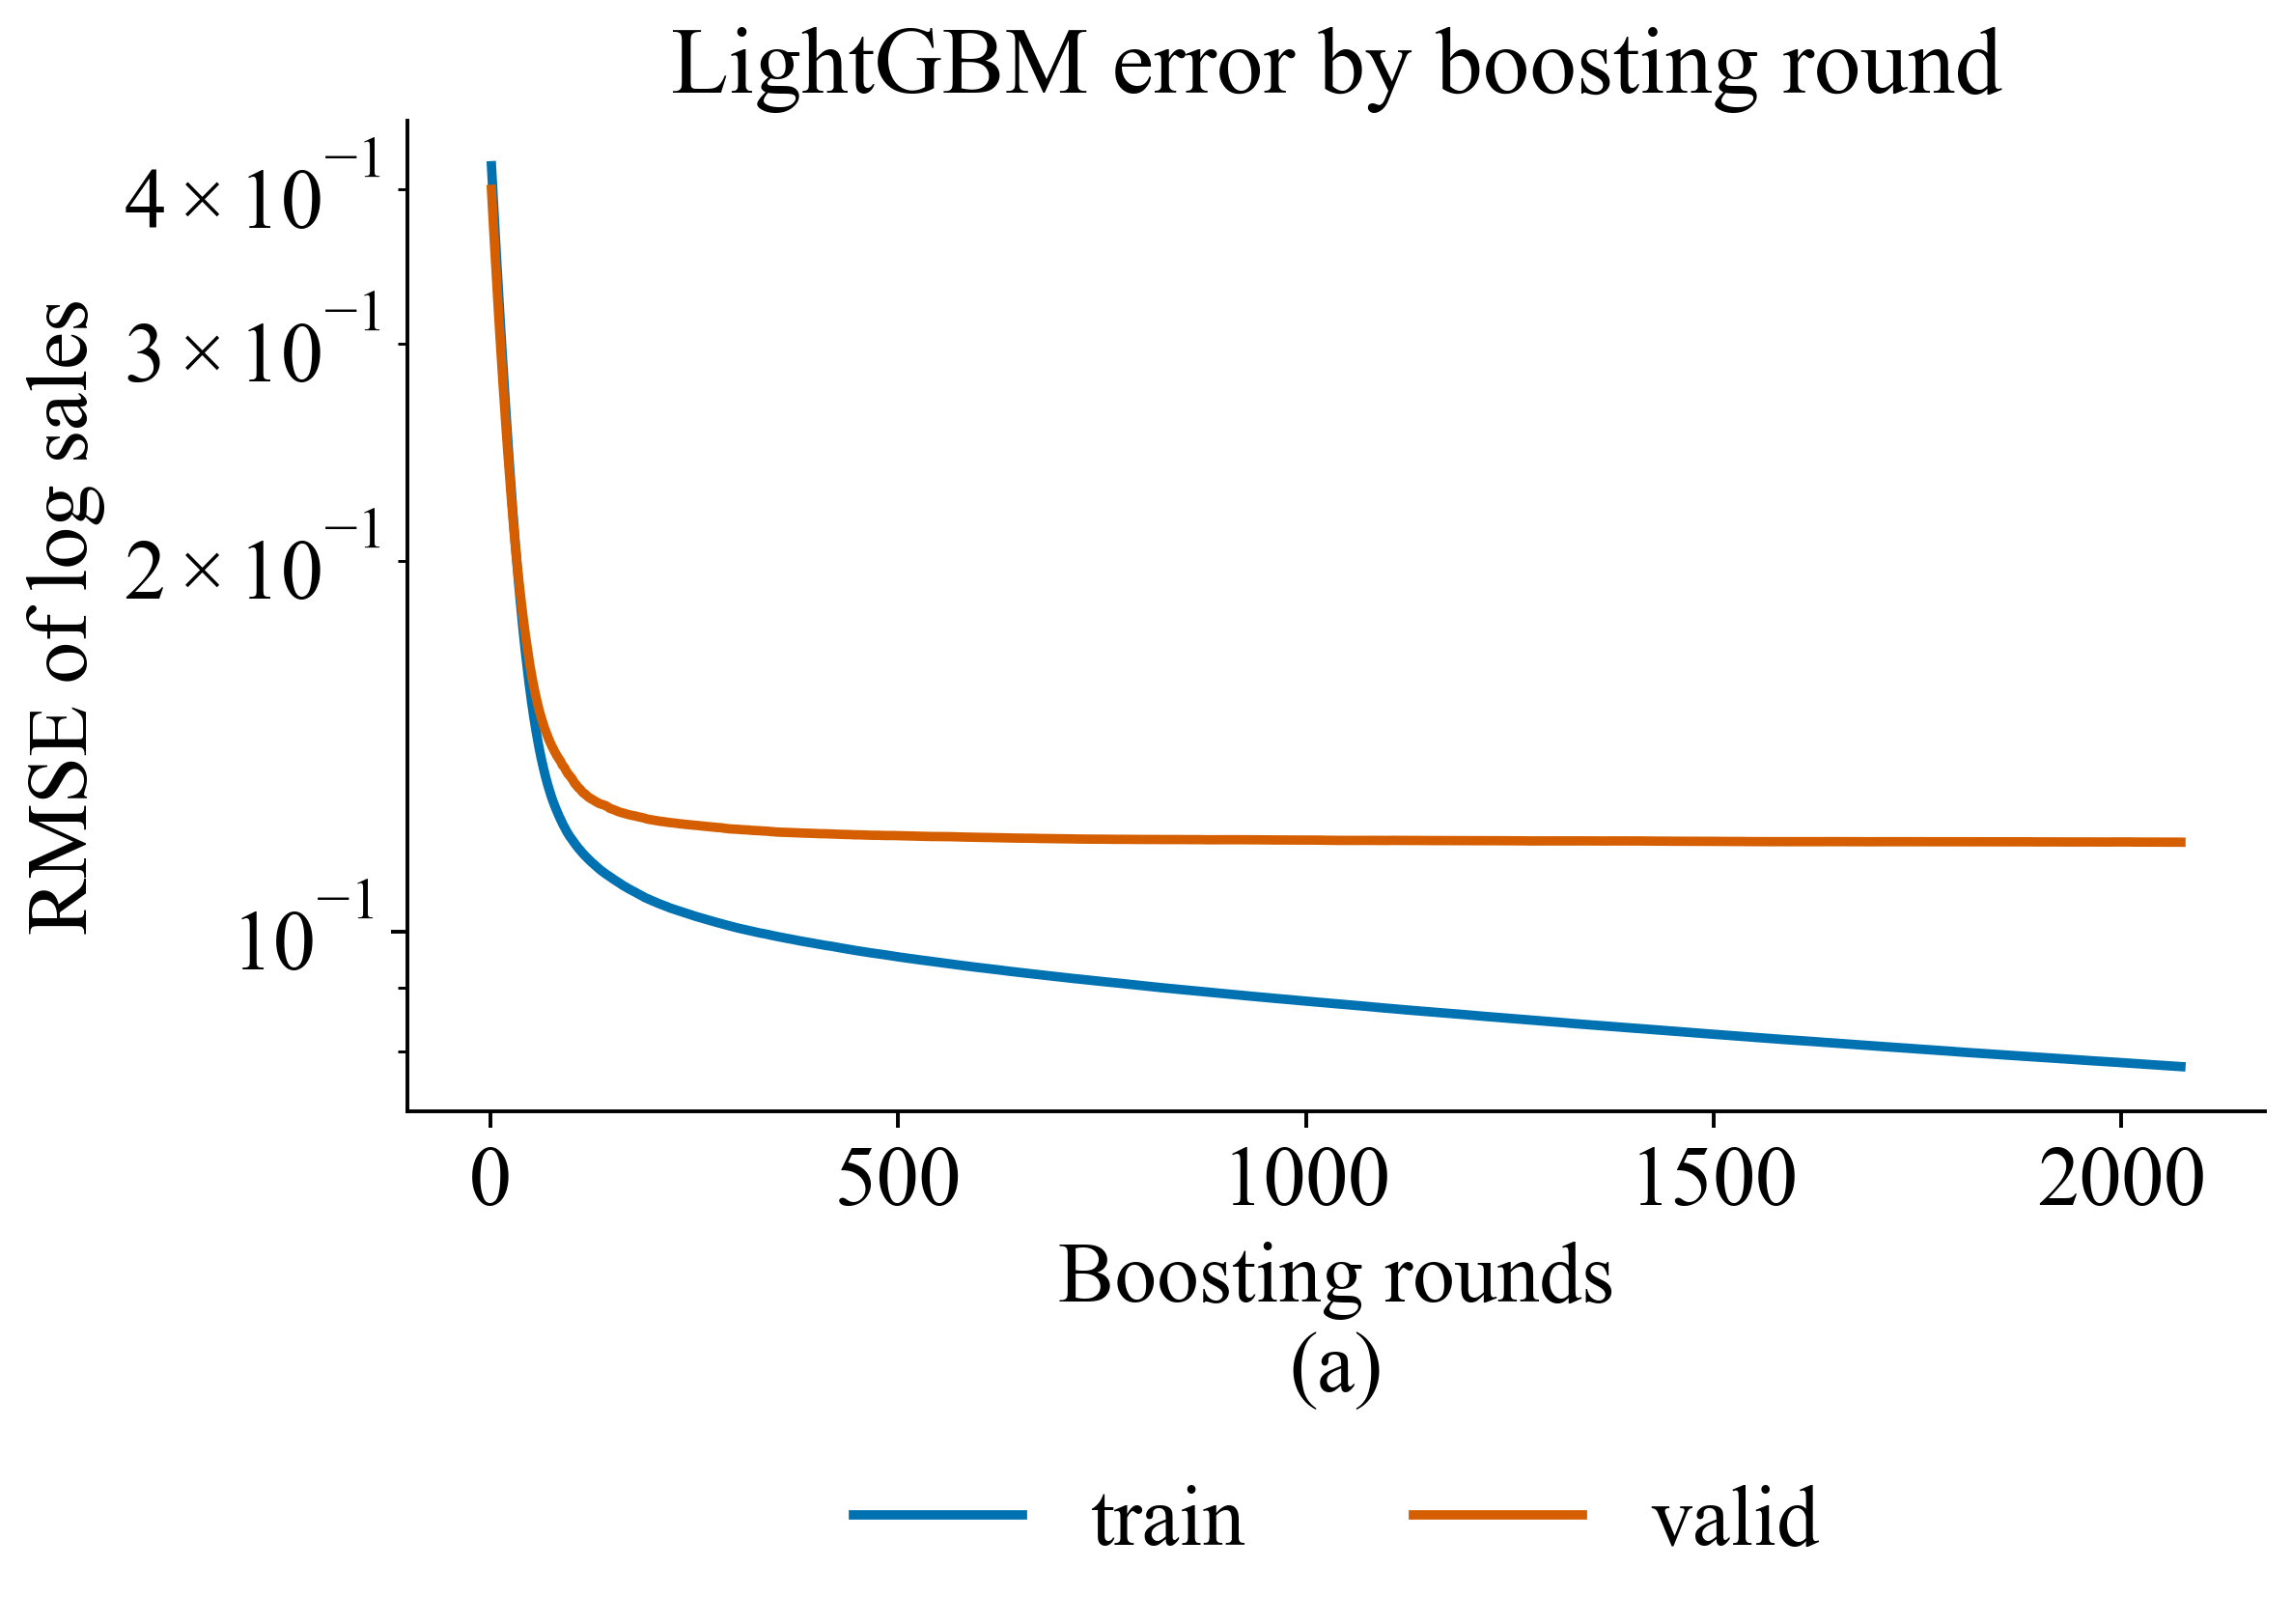

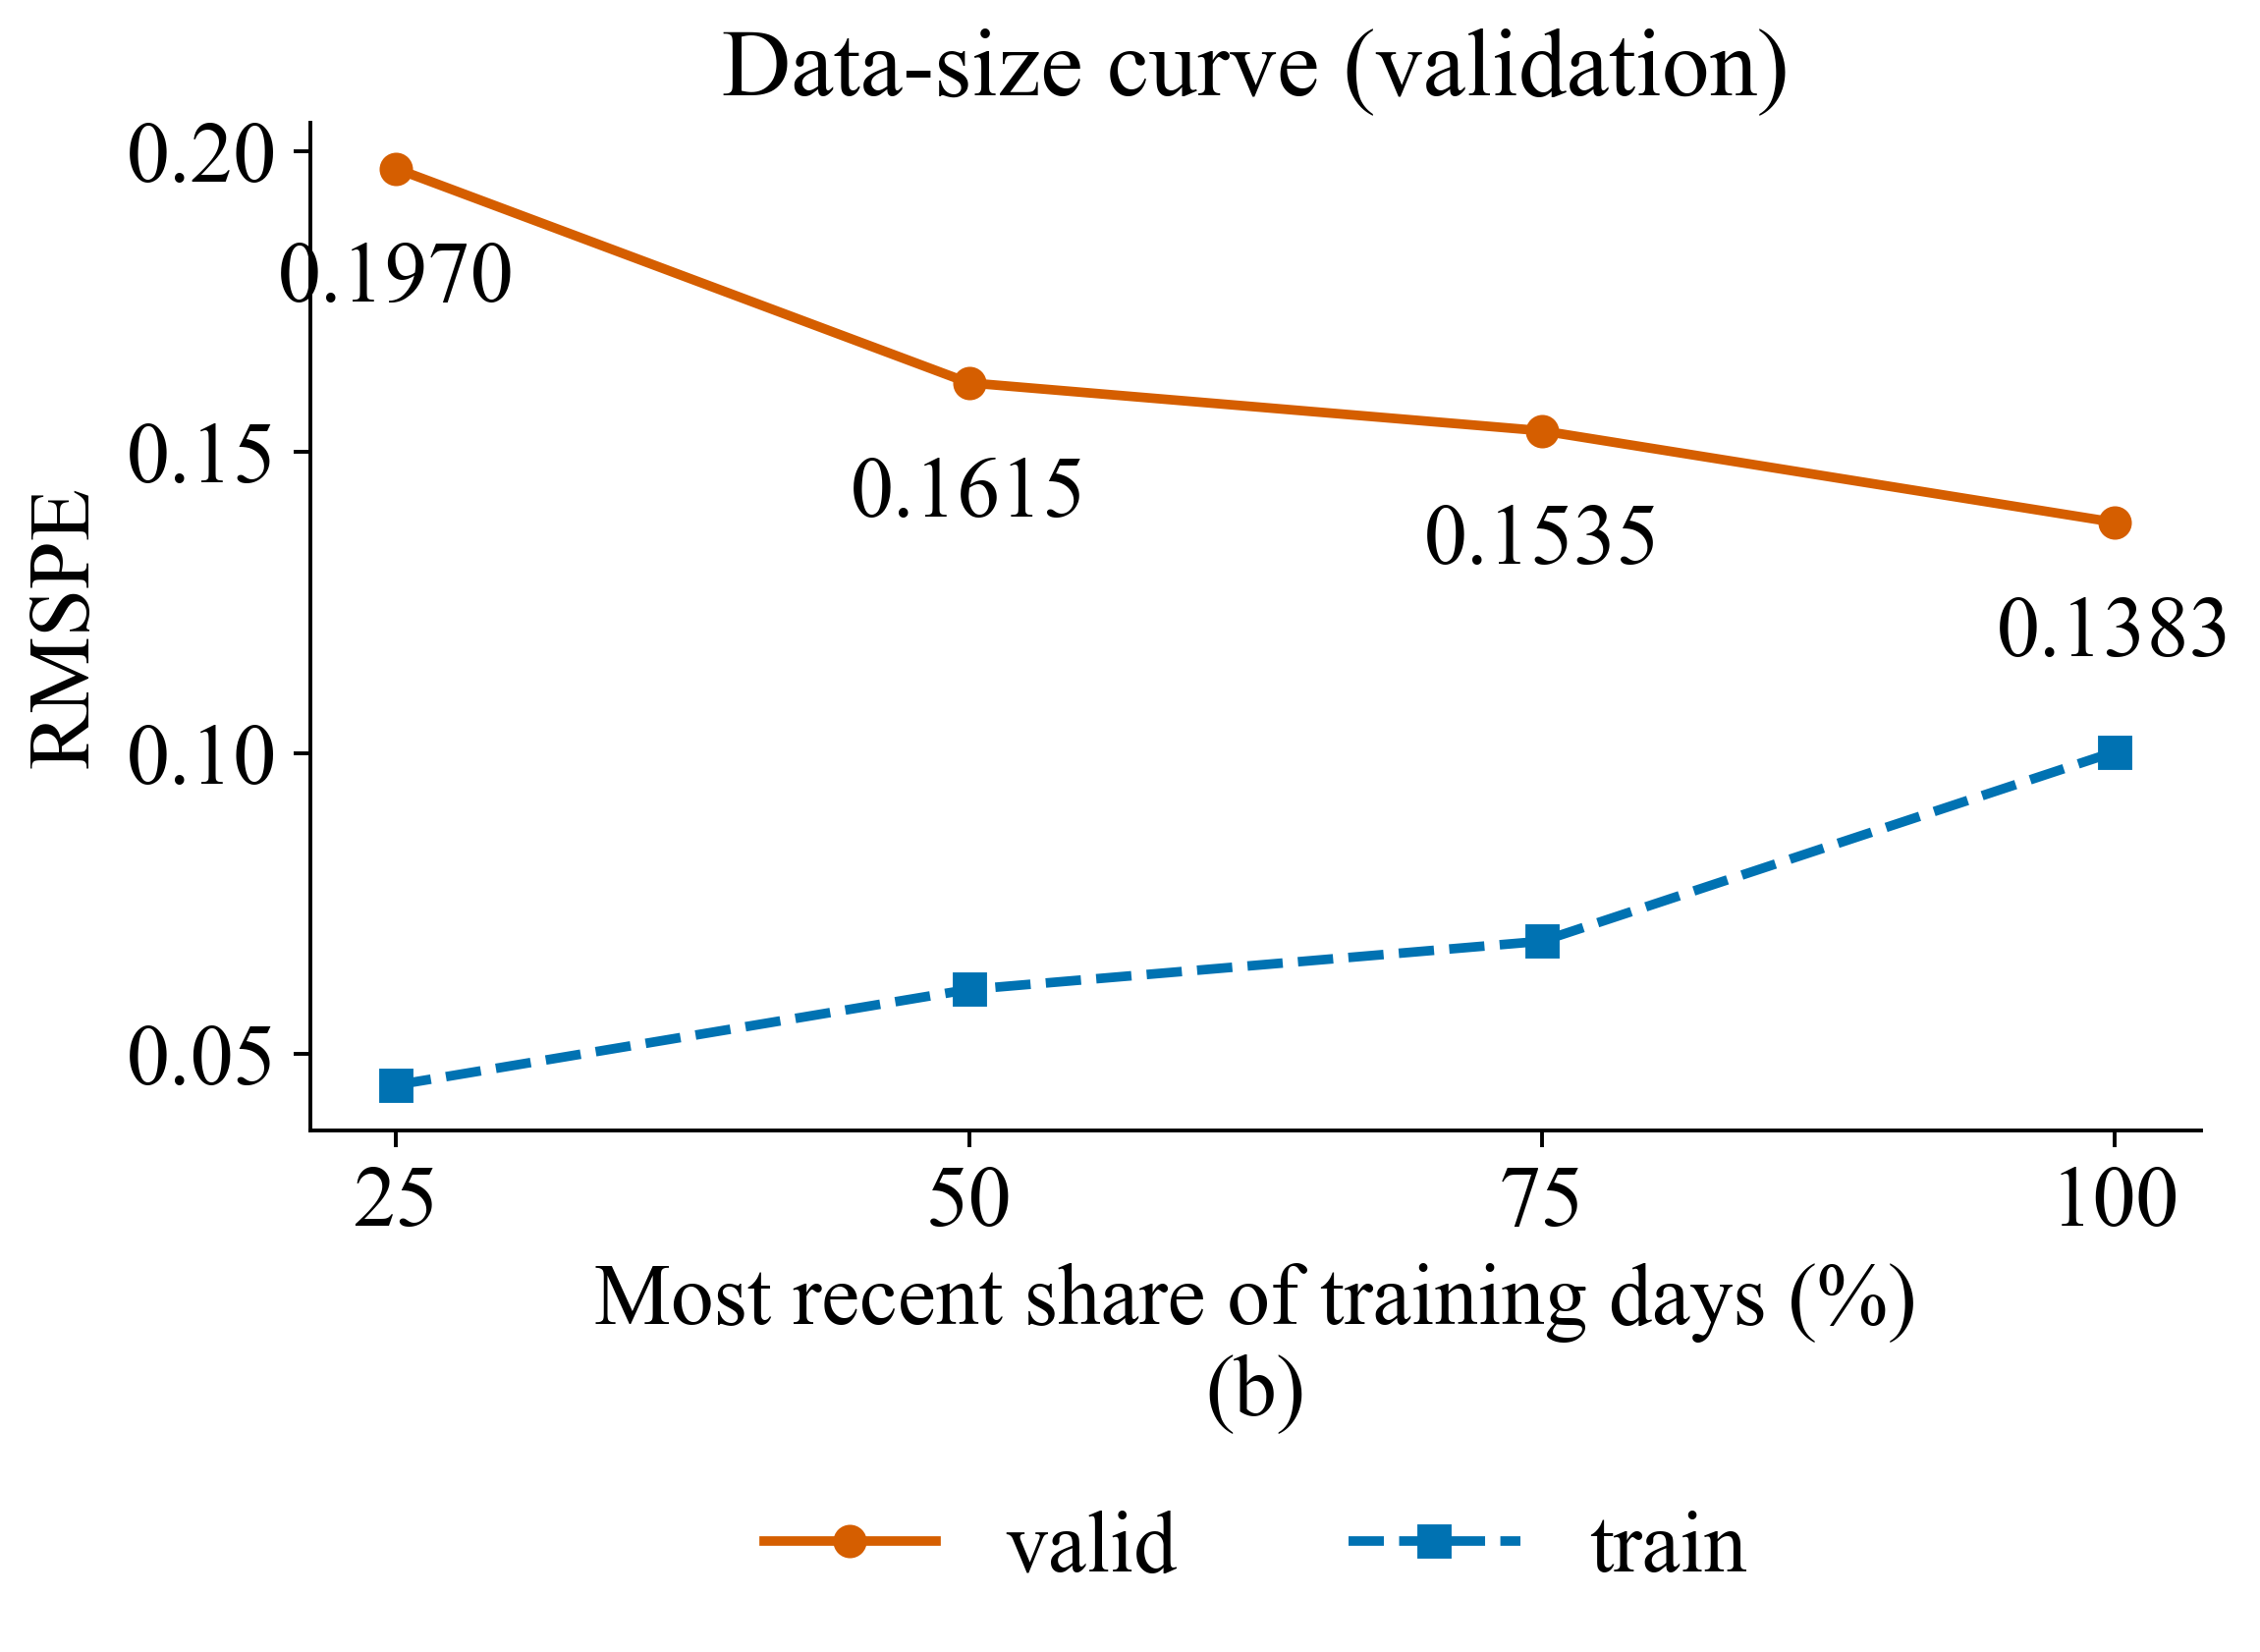

In [14]:
# (a) boosting-round curve on train and valid; (b) data-size curve: most recent 25/50/75/100 % of the training days
curve = lgb.LGBMRegressor(
    n_estimators=lgb_iter,
    **lgb_cfg,
    subsample_freq=1,
    random_state=SEED,
    n_jobs=N_JOBS,
    verbose=-1,
)
curve.fit(
    X_tr_tree,
    y_tr,
    eval_X=(X_tr_tree, X_va_tree),
    eval_y=(y_tr, y_va),
    eval_names=["train", "valid"],
    eval_metric="rmse",
    categorical_feature=CATEGORICAL,
)
ev = curve.evals_result_
size_rows = []
days = np.sort(tr["Date"].unique())
for frac in (0.25, 0.5, 0.75, 1.0):
    start = days[int(round((1 - frac) * len(days)))]
    sub = tr[tr["Date"] >= start]
    m = lgb.LGBMRegressor(
        n_estimators=lgb_iter,
        **lgb_cfg,
        subsample_freq=1,
        random_state=SEED,
        n_jobs=N_JOBS,
        verbose=-1,
    ).fit(design_matrix(sub, "tree"), sub["log_sales"], categorical_feature=CATEGORICAL)
    size_rows.append(
        {
            "share of training days": frac,
            "first training day": str(pd.Timestamp(start).date()),
            "rows": len(sub),
            "valid RMSPE": rmspe(va["Sales"], np.exp(m.predict(X_va_tree))),
            "train RMSPE": rmspe(
                sub["Sales"], np.exp(m.predict(design_matrix(sub, "tree")))
            ),
        }
    )
size_tab = pd.DataFrame(size_rows).set_index("share of training days")
_ = save_table(
    size_tab,
    "tab3_6_data_size_curve",
    "LightGBM (selected configuration) fitted on the most recent 25–100 % of the training days: validation and training RMSPE.",
    float_format="%.4f",
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
it = np.arange(1, len(ev["train"]["rmse"]) + 1)
axes[0].plot(it, ev["train"]["rmse"], color=PALETTE[0], lw=2, label="train")
axes[0].plot(it, ev["valid"]["rmse"], color=PALETTE[3], lw=2, label="valid")
axes[0].set_xlabel("Boosting rounds")
axes[0].set_ylabel("RMSE of log sales")
axes[0].set_title("LightGBM error by boosting round")
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)
axes[0].set_yscale("log")
axes[1].plot(
    size_tab.index * 100,
    size_tab["valid RMSPE"],
    "o-",
    color=PALETTE[3],
    lw=2,
    label="valid",
)
axes[1].plot(
    size_tab.index * 100,
    size_tab["train RMSPE"],
    "s--",
    color=PALETTE[0],
    lw=2,
    label="train",
)
for x, v in zip(size_tab.index * 100, size_tab["valid RMSPE"]):
    axes[1].text(x, v - 0.012, f"{v:.4f}", ha="center", va="top", fontsize=18)
axes[1].set_xlabel("Most recent share of training days (%)")
axes[1].set_ylabel("RMSPE")
axes[1].set_title("Data-size curve (validation)")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2)
axes[1].set_xticks([25, 50, 75, 100])
label_panels(axes)
fig.tight_layout()
save_fig(fig, "fig3_1_learning_curves")
show_fig("fig3_1_learning_curves")


## 9. Error diagnostics by regime, sales range and validation horizon

In [15]:
preds = {
    m: pd.read_csv(
        RUNS / f"{NB}_{m.replace(' ', '_').replace('/', '-')}_valid" / "predictions.csv"
    )["pred"].values
    for m in LEARNED + ["Naive: level x weekday/promo ratio"]
}
assert all(
    (
        pd.read_csv(
            RUNS
            / f"{NB}_{m.replace(' ', '_').replace('/', '-')}_valid"
            / "predictions.csv"
        )["row_id"].values
        == va["row_id"].values
    ).all()
    for m in preds
)
ctx = va.assign(
    weekday=va["dow"].map(
        {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
    ),
    promotion=va["promo"].map({0: "no promo", 1: "promo"}),
    store_type=va["store_type"].map({0: "a", 1: "b", 2: "c", 3: "d"}),
    holiday_window=np.where(
        (va["days_to_holiday"] <= 3) | (va["days_since_holiday"] <= 3),
        "within 3 d of a holiday",
        "other days",
    ),
    sales_quintile=pd.qcut(
        va["Sales"], 5, labels=[f"Q{i}" for i in range(1, 6)]
    ).astype(str),
    valid_week=((va["Date"] - va["Date"].min()).dt.days // 7 + 1),
)


def regime_table(col):
    out = {}
    for m, p in preds.items():
        pe2 = ((ctx["Sales"] - p) / ctx["Sales"]) ** 2
        out[m] = pe2.groupby(ctx[col]).mean().pow(0.5)
    out = pd.DataFrame(out)
    out.insert(0, "store-days", ctx.groupby(col).size())
    return out


by_regime = pd.concat(
    {
        "weekday": regime_table("weekday"),
        "promotion": regime_table("promotion"),
        "store type": regime_table("store_type"),
        "holiday window": regime_table("holiday_window"),
    }
)
save_table(
    by_regime,
    "tab3_7_error_by_regime",
    "Validation RMSPE of the learned baselines and the best naive reference by weekday, promotion status, store type and holiday proximity.",
)


store-days Ridge regression Random forest LightGBM XGBoost CatBoost Naive: level x weekday/promo ratio
weekday        Fri                          16052           0.1576        0.1151   0.1174  0.1107   0.1043                             0.1711
               Mon                          15031           0.2227        0.2032   0.1382  0.1439   0.1371                             0.2828
               Sat                          16037           0.2529        0.2086   0.1900  0.1895   0.1939                             0.4588
               Sun                            338           0.7597        0.2788   0.2538  0.2266   0.2207                             1.0955
               Thu                          16046           0.1517        0.1573   0.1210  0.1231   0.1184                             0.2118
               Tue                          15760           0.1890        0.1593   0.1288  0.1298   0.1374                             0.2127
               Wed                          16030           0.1364        0.1242   0.1164  0.1170   0.1166                             0.1791
promotion      no promo                     51490           0.2121        0.1683   0.1468  0.1485   0.1487                             0.3093
               promo                        43804           0.1708        0.1615   0.1276  0.1258   0.1244                             0.2376
store type     a                            50882           0.1945        0.1735   0.1426  0.1423   0.1440                             0.3119
               b                             1824           0.1884        0.1359   0.1233  0.1161   0.1205                             0.2560
               c                            12756           0.2288        0.1802   0.1530  0.1550   0.1478                             0.2589
               d                            29832           0.1774        0.1444   0.1244  0.1253   0.1237                             0.2224
holiday window other days                   81416           0.1831        0.1608   0.1306  0.1325   0.1315                             0.2695
               within 3 d of a holiday      13878           0.2497        0.1892   0.1769  0.1696   0.1716                             0.3271

In [16]:
by_range = regime_table("sales_quintile")
by_range.insert(
    1,
    "sales range (EUR)",
    [
        f"{int(g['Sales'].min()):,} – {int(g['Sales'].max()):,}"
        for _, g in ctx.groupby("sales_quintile")
    ],
)
_ = save_table(
    by_range,
    "tab3_8_error_by_sales_range",
    "Validation RMSPE by quintile of the observed daily sales.",
)


In [17]:
by_week = regime_table("valid_week")
by_week.insert(
    1,
    "week starting",
    [str(g["Date"].min().date()) for _, g in ctx.groupby("valid_week")],
)
_ = save_table(
    by_week,
    "tab3_9_error_by_validation_week",
    "Validation RMSPE by week of the validation period (week 1 starts on 2015-01-01): drift of the error with the distance from the training data.",
)


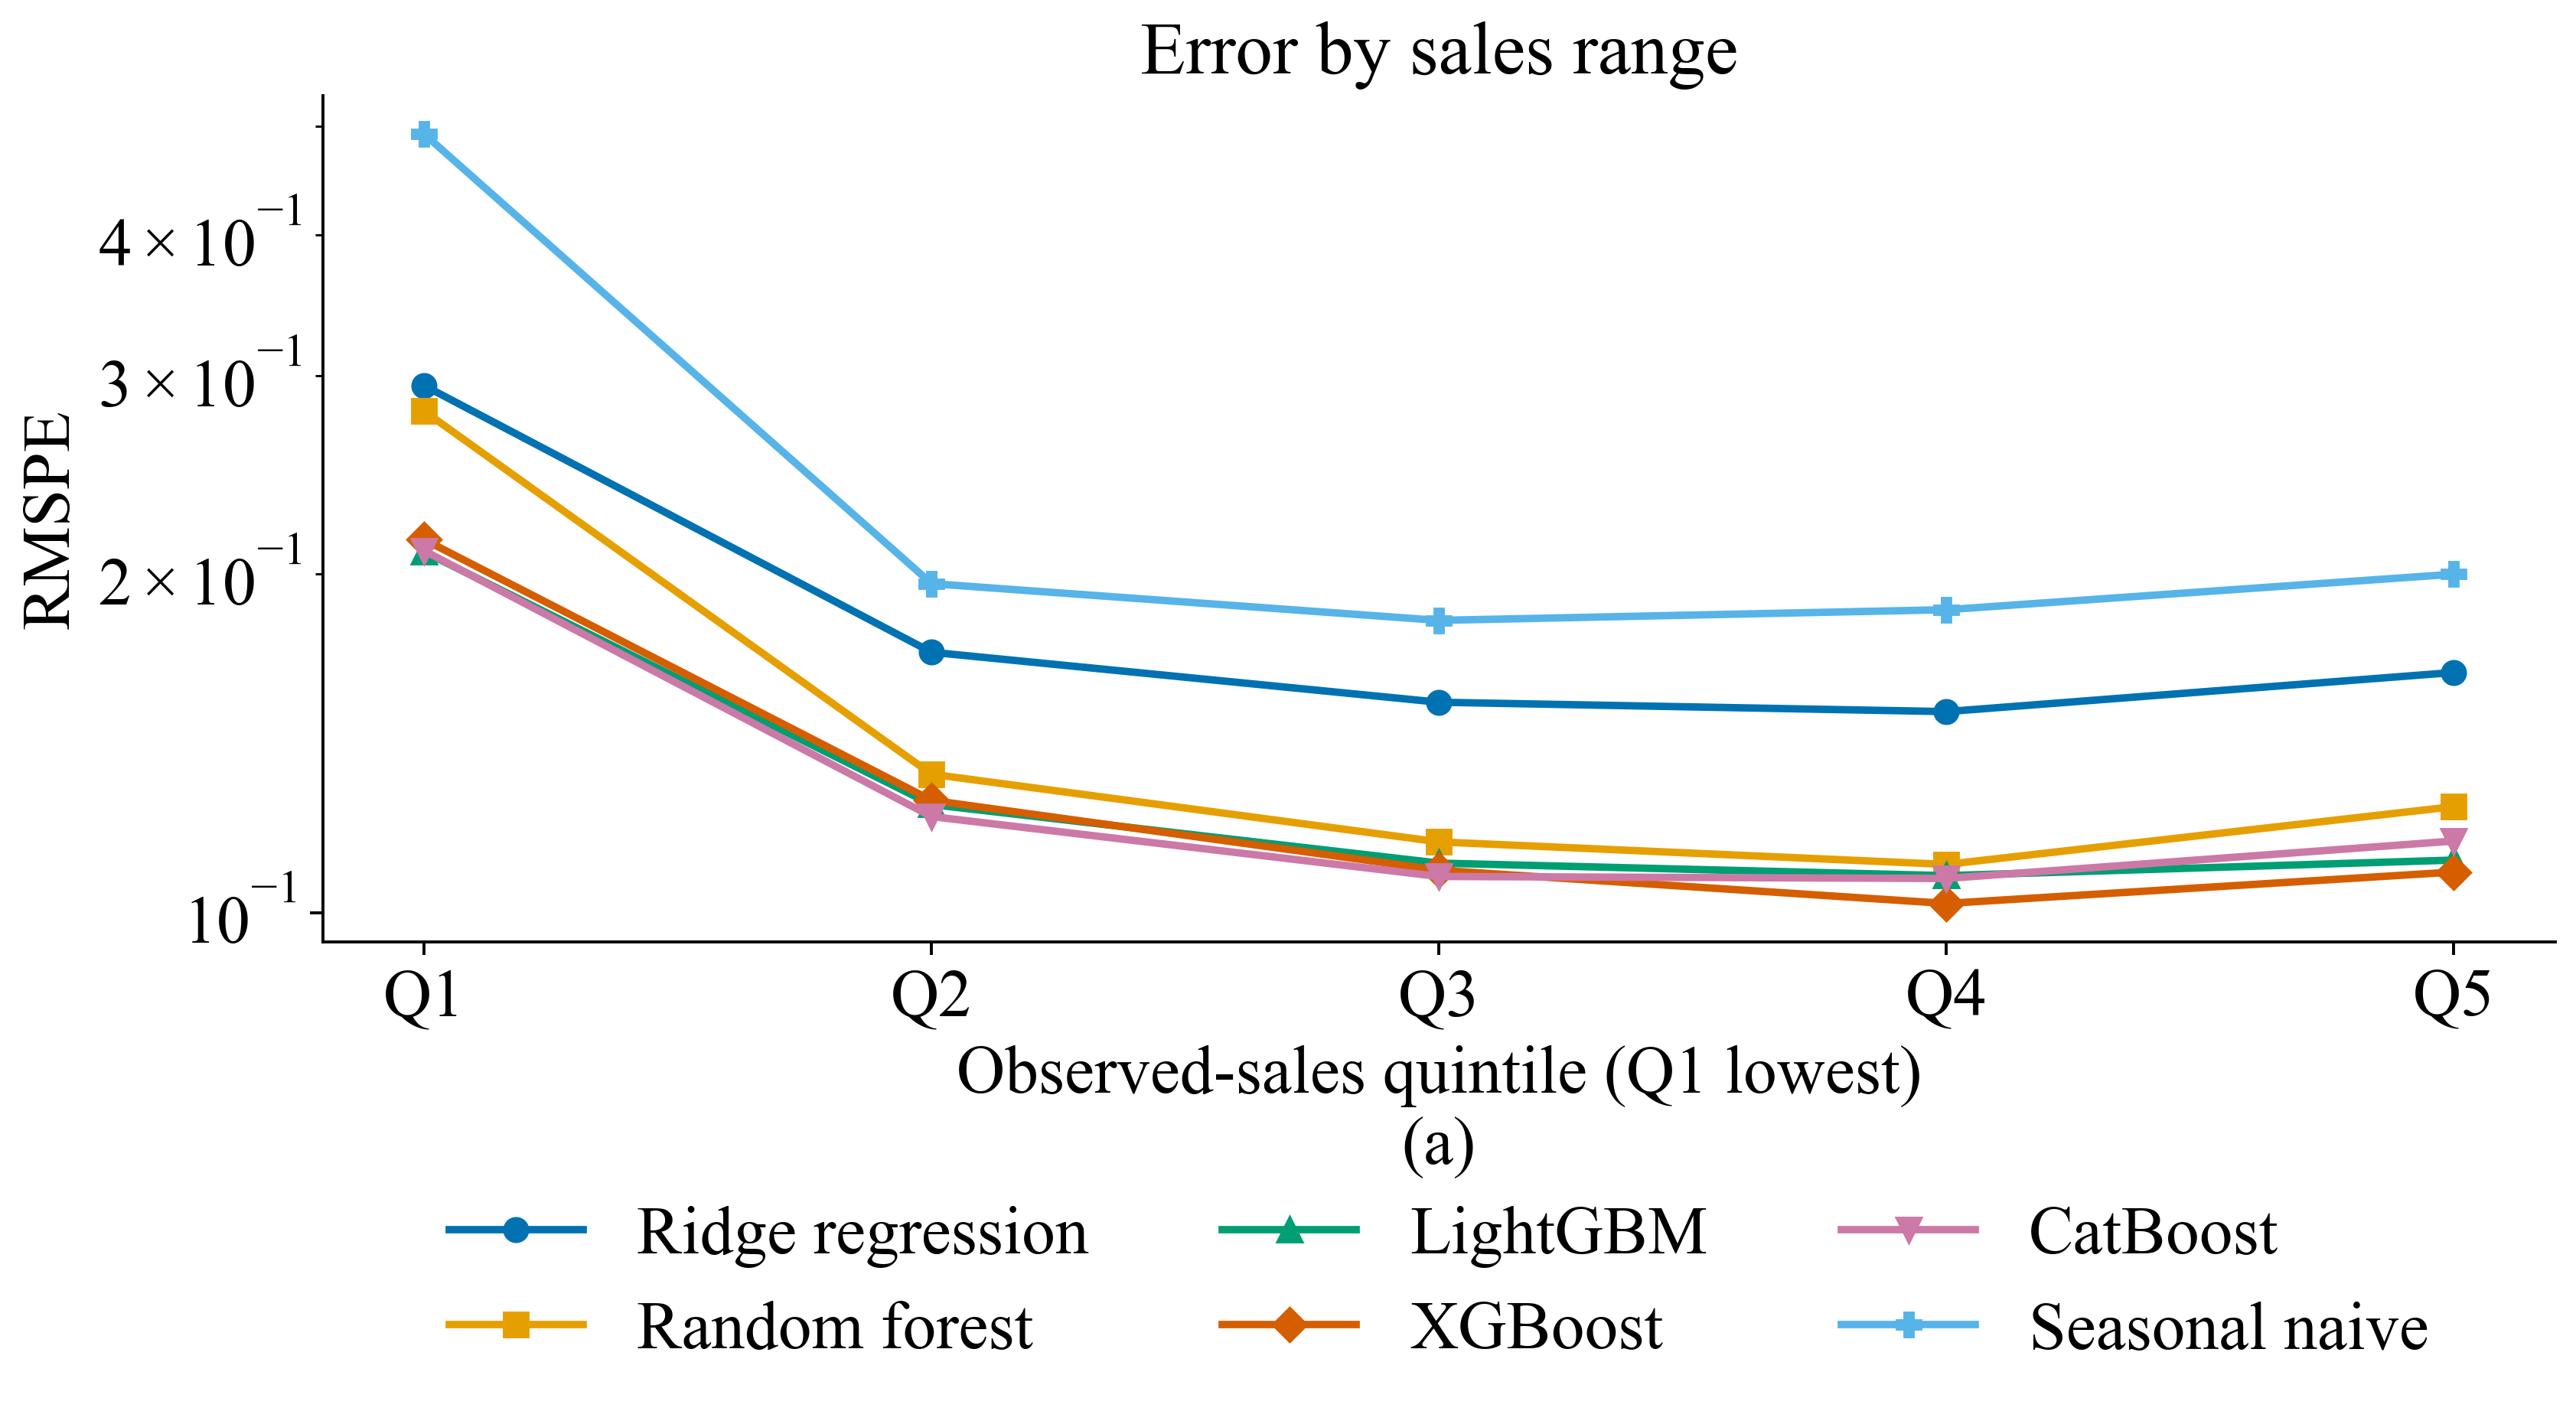

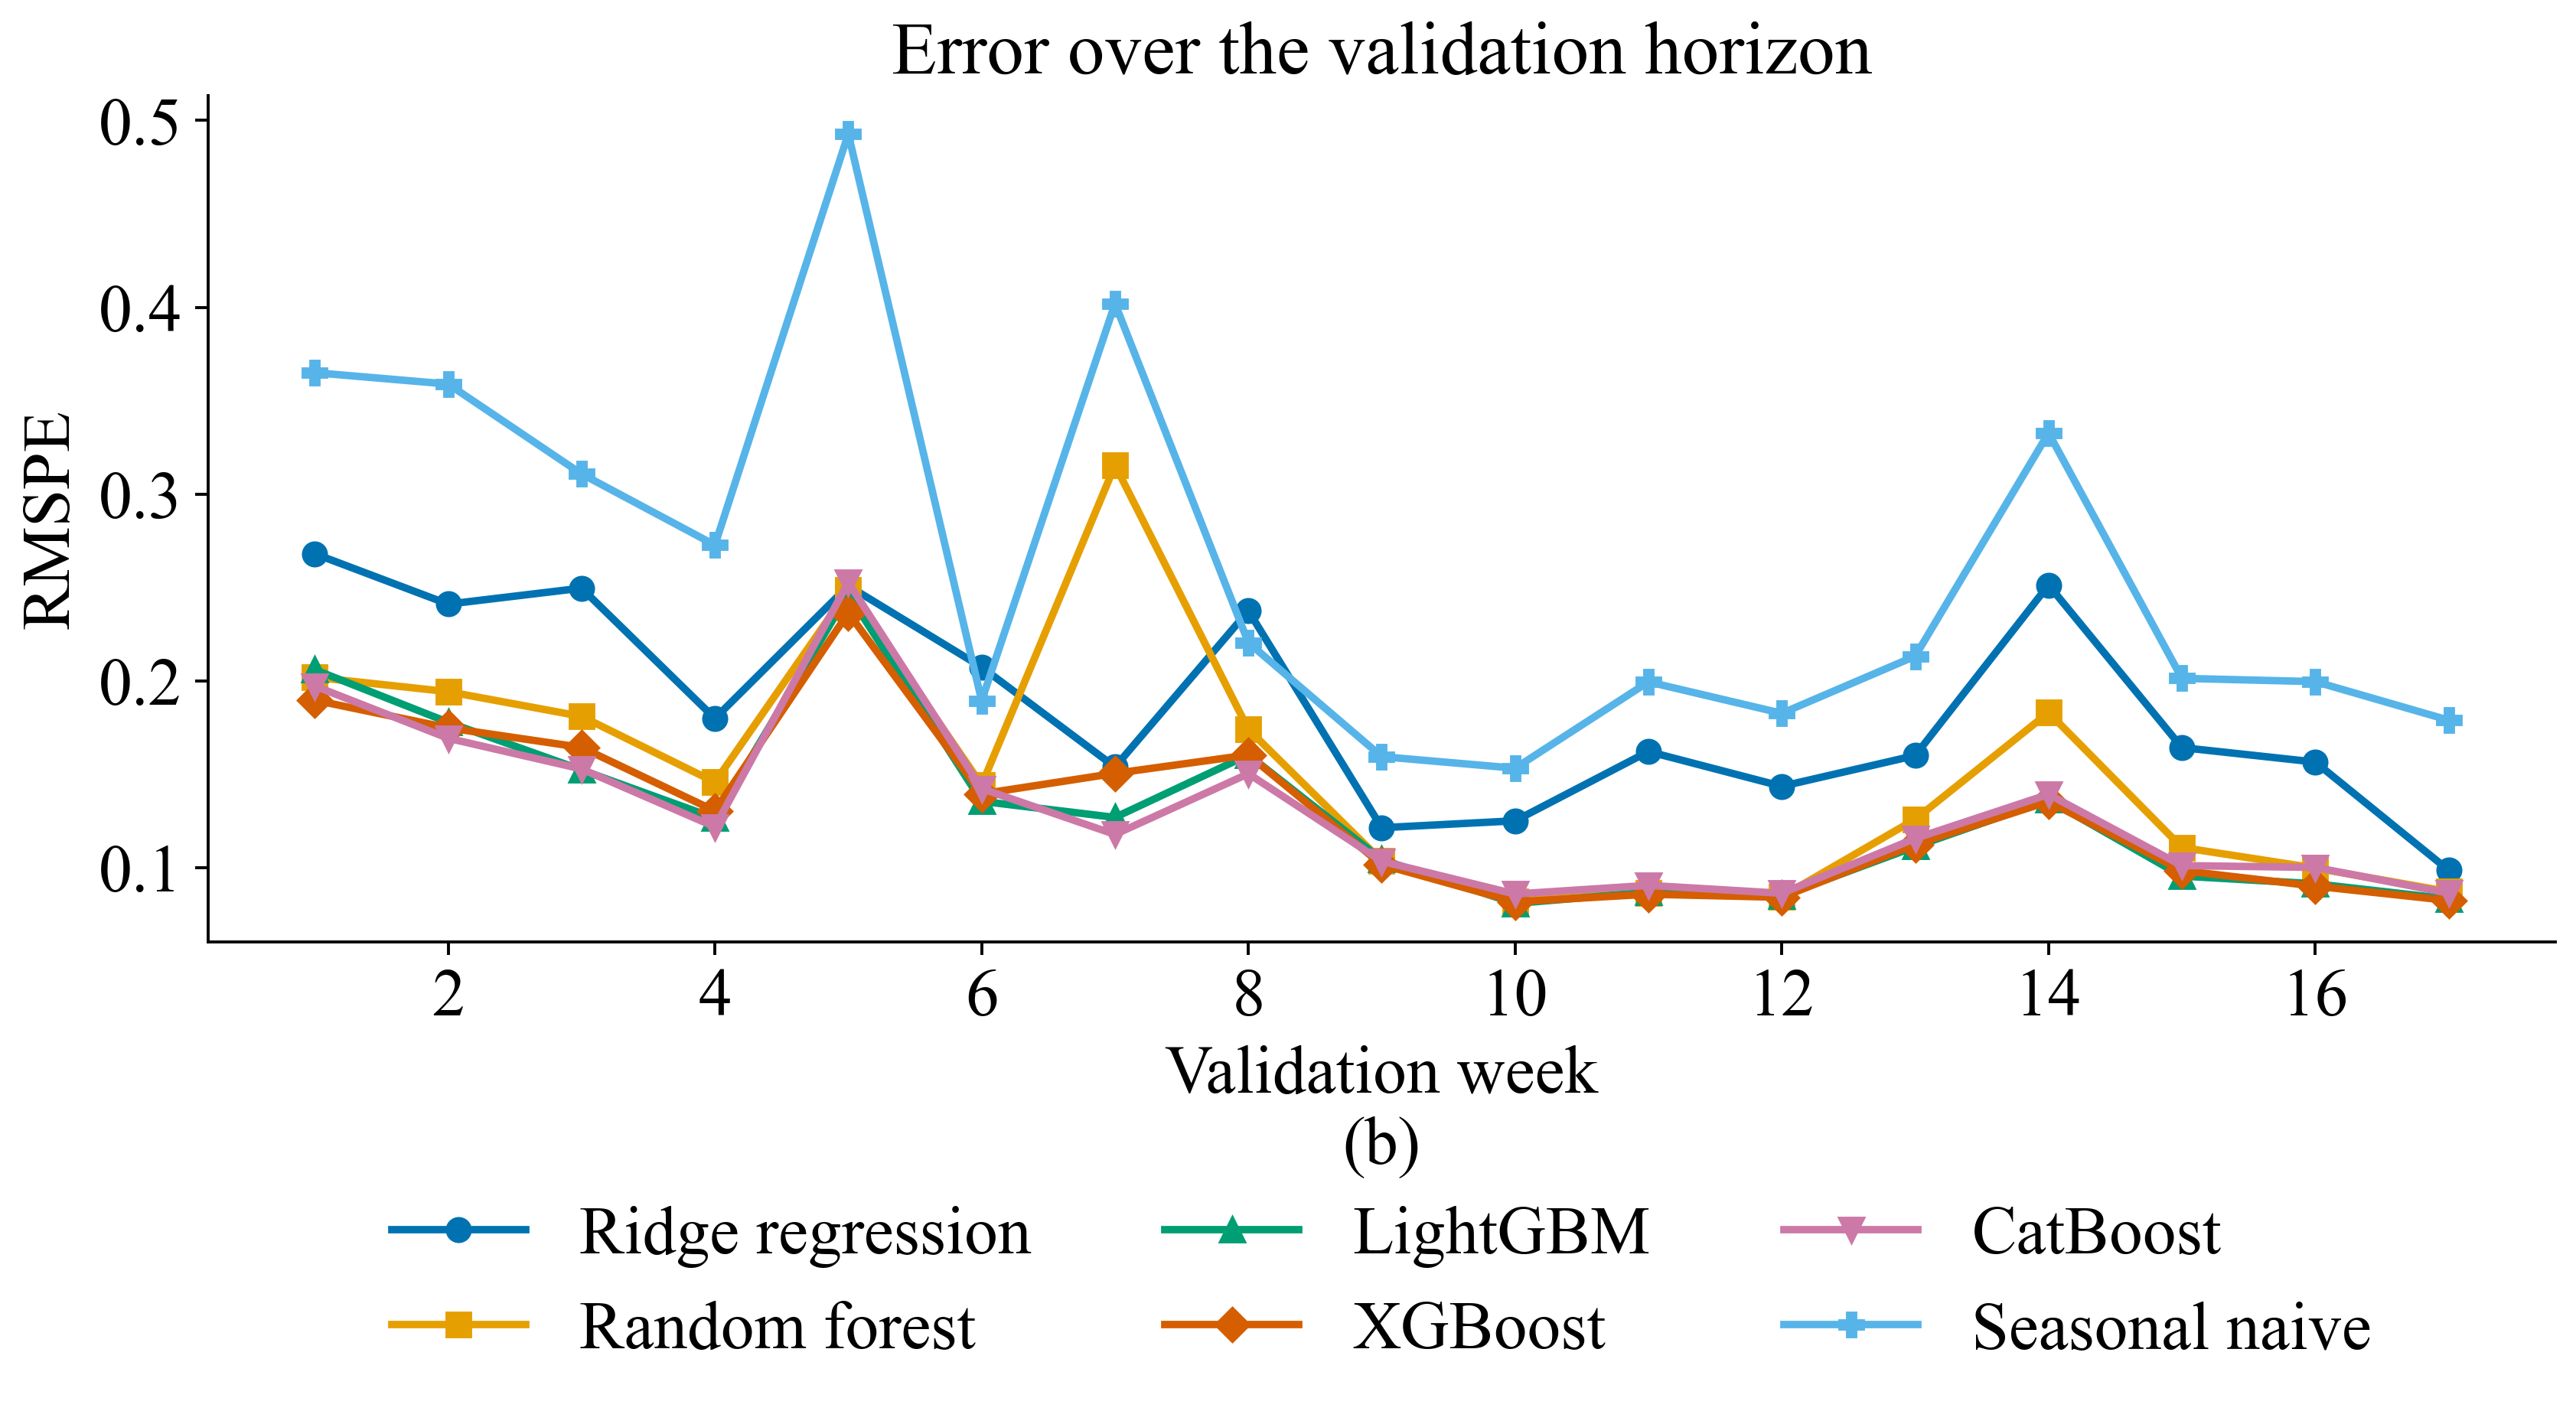

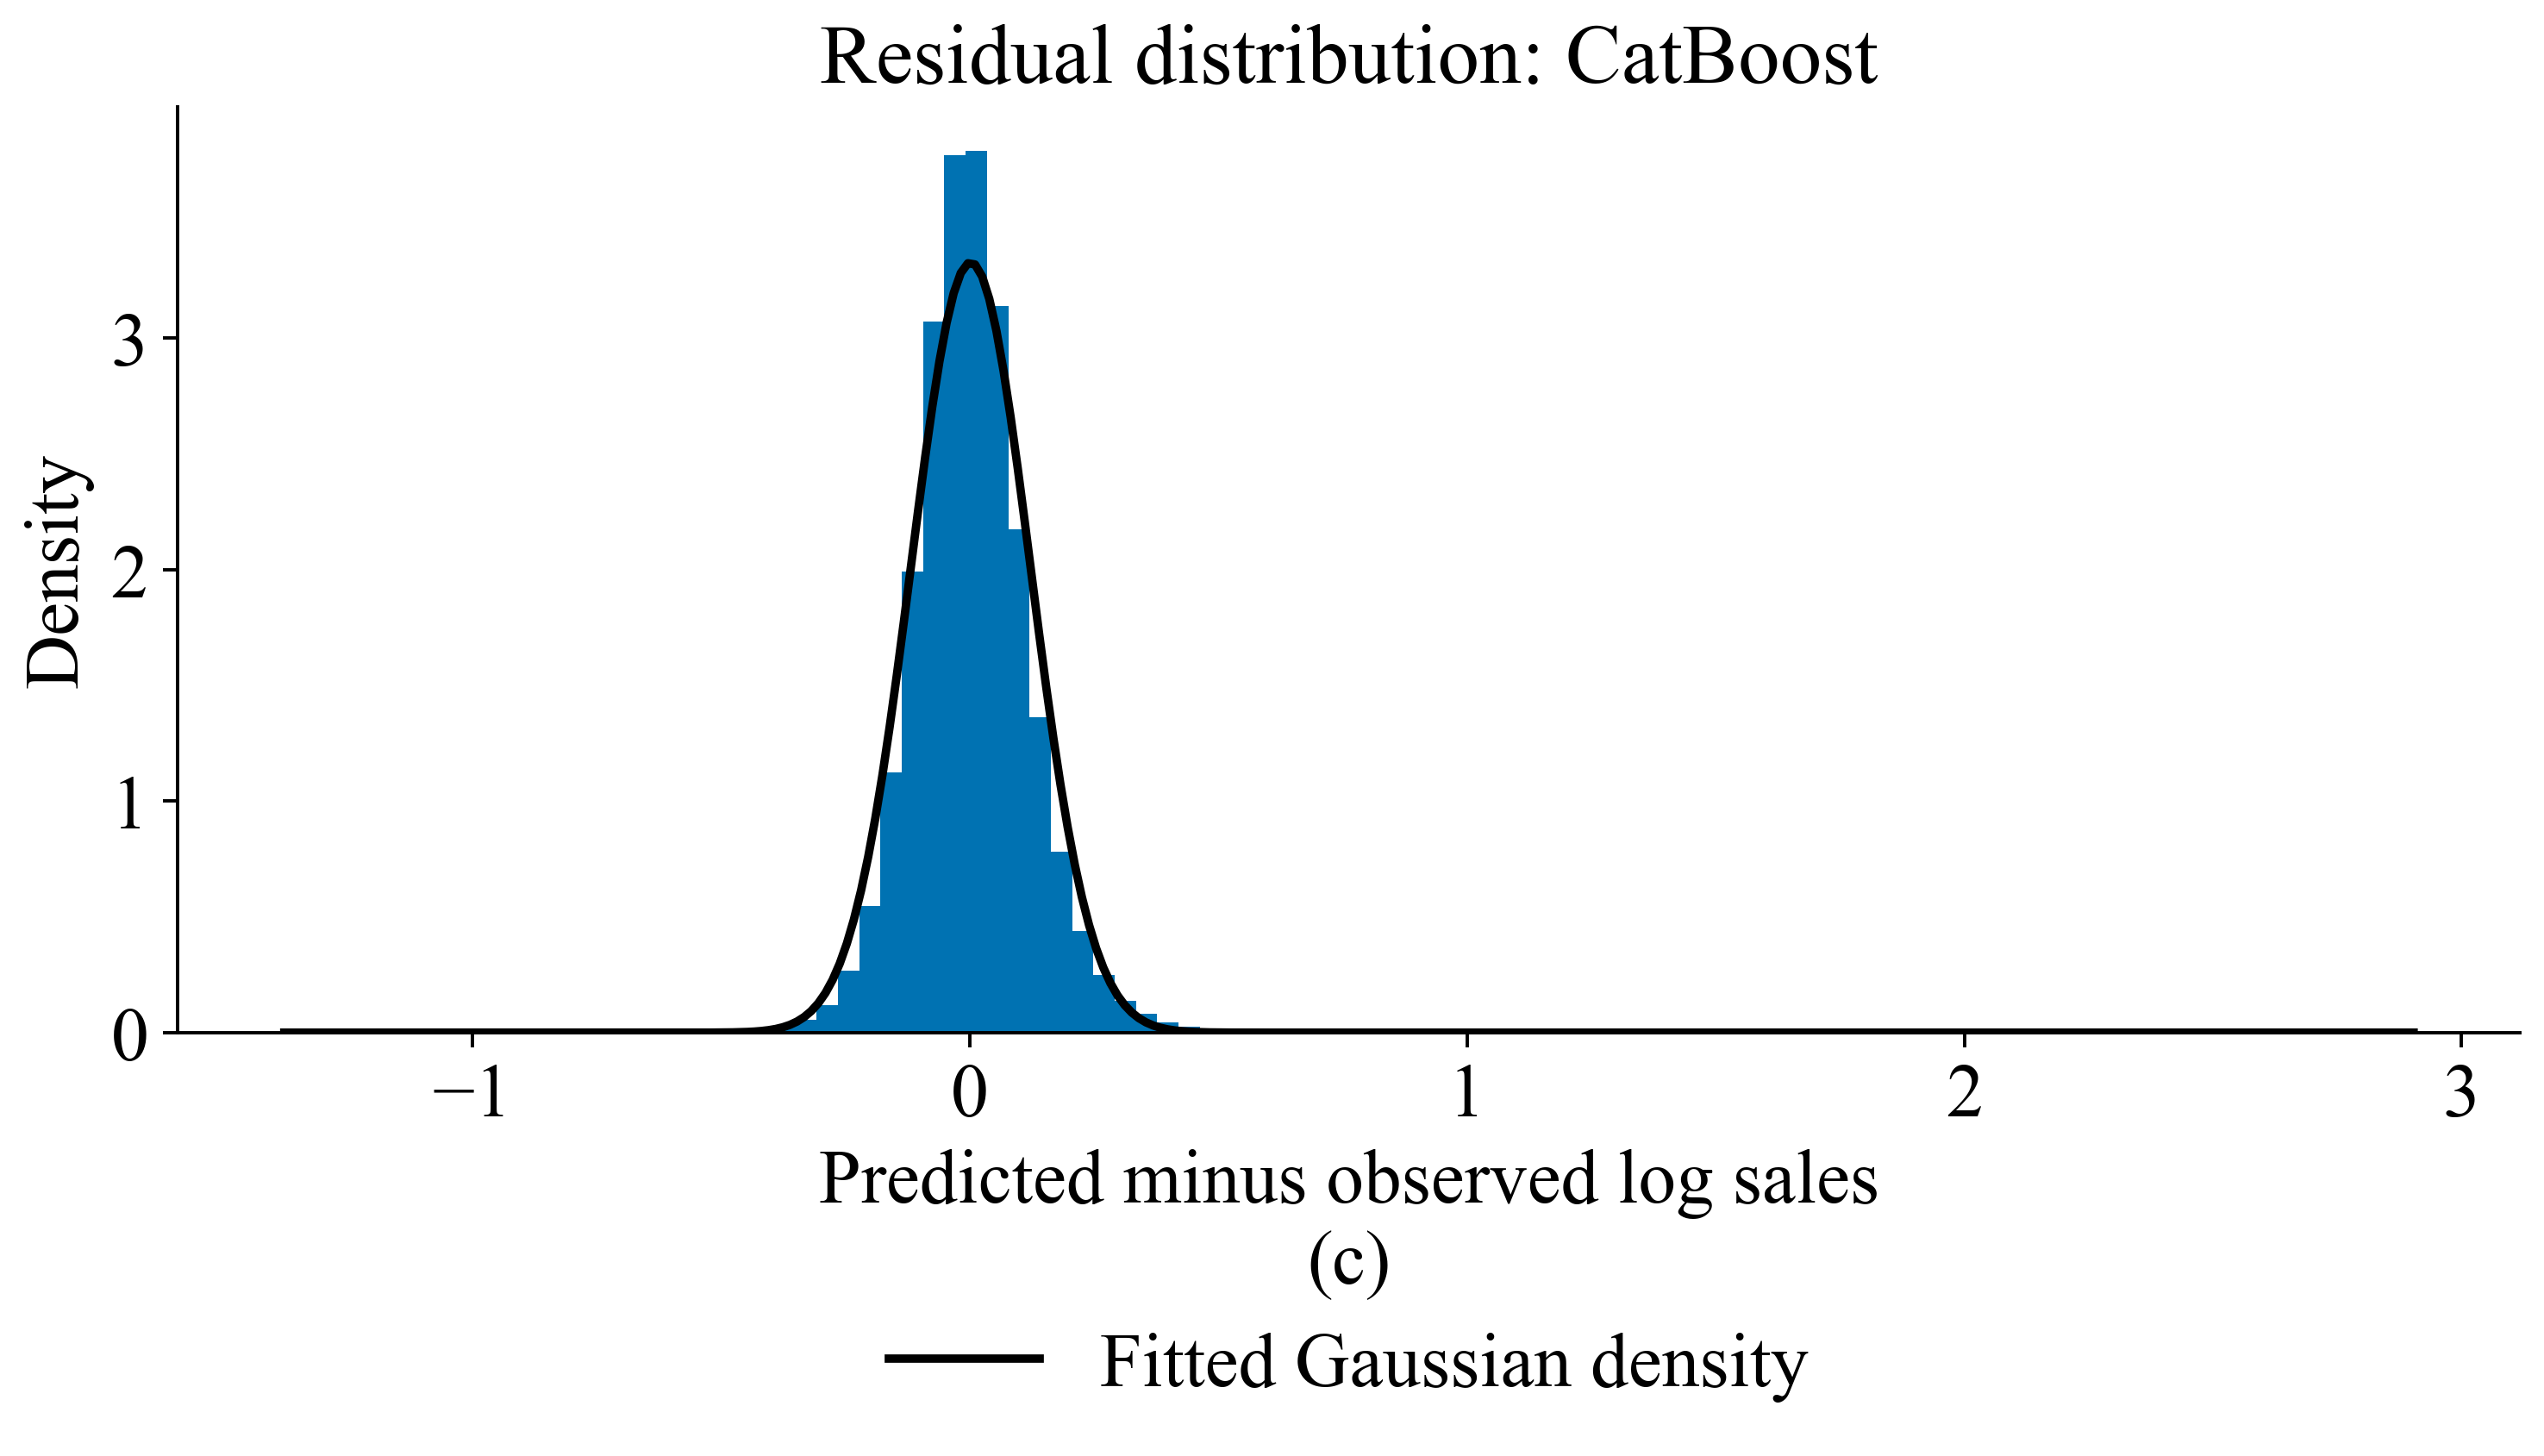

In [18]:
best_name = load_registry("valid", NB).set_index("model").loc[LEARNED, "RMSPE"].idxmin()
resid = np.log(preds[best_name]) - np.log(ctx["Sales"].values)
short = {m: ("Seasonal naive" if m.startswith("Naive") else m) for m in preds}
cols = {m: PALETTE[i] for i, m in enumerate(preds)}
markers = dict(zip(preds, ["o", "s", "^", "D", "v", "P"]))
for suffix, values, xlabel, title in [
    ("a", by_range, "Observed-sales quintile (Q1 lowest)", "Error by sales range"),
    ("b", by_week, "Validation week", "Error over the validation horizon"),
]:
    fig, ax = plt.subplots(figsize=(10, 6))
    x = np.arange(1, len(values) + 1)
    for m in preds:
        ax.plot(x, values[m], marker=markers[m], lw=2, color=cols[m], label=short[m])
    ax.set_xlabel(xlabel + "\n(" + suffix + ")")
    ax.set_ylabel("RMSPE")
    ax.set_title(title)
    if suffix == "a":
        ax.set_xticks(x)
        ax.set_xticklabels(values.index)
        ax.set_yscale("log")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=3)
    fig.tight_layout()
    save_fig(fig, "fig3_2_error_structure" + suffix)
    show_fig("fig3_2_error_structure" + suffix)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hist(resid, bins=100, color=PALETTE[0], density=True)
xs = np.linspace(resid.min(), resid.max(), 300)
ax.plot(
    xs,
    stats.norm.pdf(xs, resid.mean(), resid.std()),
    color="black",
    lw=2,
    label="Fitted Gaussian density",
)
ax.set_xlabel("Predicted minus observed log sales\n(c)")
ax.set_ylabel("Density")
ax.set_title("Residual distribution: " + best_name)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25))
fig.tight_layout()
save_fig(fig, "fig3_2_error_structurec")
show_fig("fig3_2_error_structurec")


## 10. Computational cost

In [19]:
cost = pd.DataFrame(
    {
        m: {
            "search seconds": {
                "Ridge regression": ridge_trials,
                "Random forest": rf_trials,
                "LightGBM": lgb_trials,
                "XGBoost": xgb_trials,
                "CatBoost": cb_trials,
            }[m]["seconds"].sum(),
            "final fit seconds": timing[m][0],
            "predict seconds (valid)": timing[m][1],
            "stored model (MiB)": os.path.getsize(
                RUNS / f"{NB}_{m.replace(' ', '_')}_valid" / "model.pkl"
            )
            / 2**20,
            "complexity": complexity[m],
        }
        for m in LEARNED
    }
).T
save_table(
    cost,
    "tab3_10_computational_cost",
    f"Observed computational cost on Apple M1 Pro ({N_JOBS} CPU threads): search time, final fit, prediction on {len(va):,} selection rows, and gzip-compressed model size in MiB. Shared-machine wall-clock times are descriptive, not controlled speed comparisons.",
    float_format="%.2f",
)


,search seconds,final fit seconds,predict seconds (valid),stored model (MiB),complexity
Ridge regression,12.9607,0.1024,0.0070,0.0013,87 coefficients
Random forest,639.1554,201.0913,3.2309,"1,639.9709","300 trees, 89,944,674 nodes"
LightGBM,242.1279,92.2878,14.5803,20.2123,2073 trees x 255 leaves
XGBoost,184.9636,41.7530,1.0152,19.5071,"1168 trees, depth 12"
CatBoost,"3,279.7051",210.4220,0.1151,1.2704,"877 symmetric trees, depth 8"


## 11. Complementarity of the errors

In [20]:
from IPython.display import display

E = pd.DataFrame({m: np.log(p) - np.log(ctx["Sales"].values) for m, p in preds.items()})
corr = E.corr()
display(
    save_table(
        corr,
        "tab3_11_residual_correlation",
        "Pearson correlation of the log-scale residuals of the baselines on the validation period.",
        float_format="%.3f",
    )
)
pairs = []
names = list(preds)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        avg = np.exp((np.log(preds[a]) + np.log(preds[b])) / 2)
        oracle = np.where(
            np.abs(preds[a] / ctx["Sales"].values - 1)
            <= np.abs(preds[b] / ctx["Sales"].values - 1),
            preds[a],
            preds[b],
        )
        best_single = min(rmspe(ctx["Sales"], preds[a]), rmspe(ctx["Sales"], preds[b]))
        pairs.append(
            {
                "pair": f"{a} + {b}",
                "residual correlation": corr.loc[a, b],
                "best single RMSPE": best_single,
                "geometric mean RMSPE": rmspe(ctx["Sales"], avg),
                "gain of geometric mean %": 100
                * (1 - rmspe(ctx["Sales"], avg) / best_single),
                "oracle RMSPE": rmspe(ctx["Sales"], oracle),
                "oracle gain %": 100 * (1 - rmspe(ctx["Sales"], oracle) / best_single),
            }
        )
pairs = (
    pd.DataFrame(pairs)
    .set_index("pair")
    .sort_values("gain of geometric mean %", ascending=False)
)
save_table(
    pairs,
    "tab3_12_pairwise_complementarity",
    "Pairwise complementarity on the validation period: residual correlation, RMSPE of the equal-weight geometric mean and of the row-wise oracle, and their gains over the better member.",
)


,Ridge regression,Random forest,LightGBM,XGBoost,CatBoost,Naive: level x weekday/promo ratio
Ridge regression,1.0000,0.7830,0.7249,0.7343,0.7439,0.6781
Random forest,0.7830,1.0000,0.8385,0.8761,0.8002,0.7109
LightGBM,0.7249,0.8385,1.0000,0.9532,0.8977,0.5735
XGBoost,0.7343,0.8761,0.9532,1.0000,0.8893,0.5952
CatBoost,0.7439,0.8002,0.8977,0.8893,1.0000,0.5161
Naive: level x weekday/promo ratio,0.6781,0.7109,0.5735,0.5952,0.5161,1.0000


,residual correlation,best single RMSPE,geometric mean RMSPE,gain of geometric mean %,oracle RMSPE,oracle gain %
pair,,,,,,
XGBoost + CatBoost,0.8893,0.1381,0.1349,2.2785,0.1206,12.6393
LightGBM + CatBoost,0.8977,0.1381,0.1352,2.0673,0.1210,12.3265
LightGBM + XGBoost,0.9532,0.1383,0.1369,0.9874,0.1273,7.9998
Ridge regression + Random forest,0.7830,0.1652,0.1655,-0.1357,0.1355,17.9812
Random forest + CatBoost,0.8002,0.1381,0.1412,-2.2536,0.1219,11.7255
Random forest + LightGBM,0.8385,0.1383,0.1437,-3.8701,0.1249,9.6921
Random forest + XGBoost,0.8761,0.1385,0.1459,-5.3038,0.1273,8.1368
Ridge regression + Naive: level x weekday/promo ratio,0.6781,0.1943,0.2112,-8.7480,0.1594,17.9170
Ridge regression + XGBoost,0.7343,0.1385,0.1543,-11.3937,0.1226,11.4966


## 12. Baseline leaderboard on the validation period

In [21]:
reg = load_registry("valid", NB).set_index("model")
board = reg[
    ["RMSPE", "RMSPE_lo", "RMSPE_hi", "RMSE", "MAE", "sMAPE", "R2", "fit_seconds"]
].sort_values("RMSPE")
save_table(
    board,
    "tab3_13_baseline_leaderboard",
    "Validation accuracy of the baselines (Jan–Apr 2015, 1,003 stores); 95 % cluster-bootstrap interval for RMSPE.",
)


,RMSPE,RMSPE_lo,RMSPE_hi,RMSE,MAE,sMAPE,R2,fit_seconds
model,,,,,,,,
CatBoost,0.1381,0.1217,0.1645,892.3209,605.6798,0.0885,0.9102,210.4220
LightGBM,0.1383,0.1225,0.1617,879.9008,602.0649,0.0876,0.9127,92.2878
LightGBM (quantile 90% PI),0.1383,0.1225,0.1617,879.9008,602.0649,0.0876,0.9127,223.6849
XGBoost,0.1385,0.1231,0.1615,865.7796,592.9647,0.0868,0.9155,41.7530
Random forest,0.1652,0.1497,0.1870,984.1154,649.4110,0.0951,0.8908,201.0913
Ridge regression,0.1943,0.1774,0.2154,"1,259.0622",861.6063,0.1220,0.8213,0.1024
Naive: level x weekday/promo ratio,0.2787,0.2452,0.3319,"1,536.8871","1,057.8136",0.1514,0.7337,0.0000
Naive: same weekday mean (8 w),0.2862,0.2727,0.3036,"1,756.4665","1,270.8714",0.1827,0.6521,0.0000
Naive: 28-day mean,0.3504,0.3116,0.4133,"1,885.5714","1,410.7966",0.2076,0.5991,0.0000


In [23]:
latest_path = MANIFESTS / "latest_runs.json"
latest = json.loads(latest_path.read_text()) if latest_path.exists() else {}
latest["NB03"] = RUN_ID
latest_path.write_text(json.dumps(latest, indent=2));

# Part B · UCI Sales Transactions Weekly

## Baseline models and error diagnostics

In [1]:
# NB03_SETUP: packages, paths, search plan and helpers
import os
os.environ['OMP_NUM_THREADS']='4'
os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,platform,sys,resource,gzip,importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from sklearn.linear_model import Ridge,PoissonRegressor
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
THREAD_LIMIT=threadpool_limits(limits=4)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'uci'
for sub in ['Artifacts','Configs','Manifests']:(BASE/sub).mkdir(parents=True,exist_ok=True)
RUN_ID='NB03_UCI_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False))
# Fixed search plan: eight configurations per tunable family, five seeds for the stochastic families
PLAN={'grid':{'Lag 2':[{}],
              'Historical mean':[{'window':w,'market_adjust':a} for w in (4,8,13,None) for a in (False,True)],
              'Positive-history action':[{'window':w,'strength':s} for w in (4,8,13,None) for s in (0.0,5.0)],
              'Croston-SBA':[{'alpha':a} for a in (0.02,0.05,0.1,0.15,0.2,0.3,0.5,0.7)],
              'Ridge':[{'alpha':a,'target':t} for a in (0.1,1.0,10.0,100.0) for t in ('identity','log1p')],
              'Poisson GLM':[{'alpha':a} for a in (0.001,0.01,0.1,0.3,1.0,3.0,10.0,30.0)],
              'Random forest':[{'depth':d,'leaf':l,'target':t} for d in (8,None) for l in (5,20) for t in ('identity','log1p')],
              'LightGBM':[{'leaves':v,'min_child':m,'loss':l} for v in (15,31) for m in (30,100) for l in ('poisson','relative_l2')],
              'XGBoost':[{'depth':d,'min_child':m,'loss':l} for d in (3,6) for m in (5,20) for l in ('poisson','relative_l2')],
              'CatBoost':[{'depth':d,'l2':l2,'loss':l} for d in (4,6) for l2 in (3.0,10.0) for l in ('poisson','relative_l2')]},
      'seeds':[2026,2027,2028,2029,2030],'search_seed':2026,'stochastic':['Random forest','LightGBM','XGBoost','CatBoost'],
      'threads':4,'boosting_trees':400,'forest_trees':200,'learning_rate':0.04,'early_stopping':False,
      'F0':{'fit_latest_week':14,'evaluation_weeks':[16,18]},'nested_calibration_weeks':[20,26],'development_weeks':[28,38],'initial_fit_latest_week':26}
dump(BASE/'Configs/baseline_search.json',PLAN)
FM=json.loads((BASE/'Manifests/feature_manifest.json').read_text())
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_rows',100,'display.max_columns',12,'display.max_colwidth',None,'display.float_format',lambda v:f'{v:.5f}')
def table(df,name,best=None):
    df.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(df.to_latex(index=False,float_format='%.5f',escape=True))
    if best:display(df.style.format({k:'{:.5f}' for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(df)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))

### Model budgets and nested chronology

In [2]:
# NB03_DATA: exact common rows and fitted-fold numerical transformations
rows=pd.read_parquet(BASE/'Data/causal_features_core.parquet').sort_values(['week','Product_Code']).reset_index(drop=True)
panel=pd.read_parquet(BASE/'Data/core_permitted_long.parquet')
wide=panel.pivot(index='Product_Code',columns='week',values='quantity').sort_index()
assert rows.Product_Code.nunique()==729 and rows.week.between(6,38).all() and rows.row_id.is_unique
FEATURES=FM['features'];COUNT=FM['count_features'];MISSING=FM['missing_indicator_features'];NAMES=FEATURES+[f'{x}_missing' for x in MISSING]
class FoldPreprocessor:
    def fixed(self,frame):
        a=frame[FEATURES].astype(float).copy();assert (a[COUNT].ge(0)|a[COUNT].isna()).all().all();a[COUNT]=np.log1p(a[COUNT]);return a
    def fit(self,frame):
        a=self.fixed(frame);self.median=a.median();assert self.median.notna().all()
        b=a.fillna(self.median);self.scale=(b.quantile(.75)-b.quantile(.25));self.scale=self.scale.where(self.scale>0,1.);self.fit_row_ids=frame.row_id.tolist();return self
    def transform(self,frame):
        a=self.fixed(frame);z=(a.fillna(self.median)-self.median)/self.scale
        for k in MISSING:z[k+'_missing']=a[k].isna().astype(float)
        assert np.isfinite(z.to_numpy()).all();return z[NAMES]
    def parameters(self):return {'features':FEATURES,'median':self.median.to_dict(),'scale':self.scale.to_dict(),'fit_row_ids':self.fit_row_ids}
STAGES={'F0':(14,(16,18)),'F1':(18,(20,23)),'F2':(22,(24,27)),'Initial':(26,(28,38))}
DATA={};PREP={}
for stage,(last,bounds) in STAGES.items():
    tr=rows[rows.week.between(6,last)].copy();ev=rows[rows.week.between(*bounds)].copy();p=FoldPreprocessor().fit(tr)
    assert tr.week.max()<=ev.week.min()-2 and set(tr.row_id).isdisjoint(ev.row_id)
    PREP[stage]=p;DATA[stage]={'train':tr,'eval':ev,'X':p.transform(tr),'Xe':p.transform(ev),'y':tr.quantity.to_numpy(dtype=float)}
    dump(OUT/f'preprocessor_{stage}.json',p.parameters())
DEV=DATA['Initial']['eval'];CAL=rows[rows.week.between(20,26)].copy()
family_budget=pd.DataFrame([{'Model':m,'Configurations':len(g),'Search seed':2026,'Final fits':5 if m in PLAN['stochastic'] else (1 if m in ['Ridge','Poisson GLM'] else 0)} for m,g in PLAN['grid'].items()])
table(family_budget,'fixed_model_budget')
table(pd.DataFrame([{'Stage':k,'Latest fit label':v[0],'Forecast weeks':f'W{v[1][0]}–W{v[1][1]}','Fit rows':len(DATA[k]['train']),'Forecast rows':len(DATA[k]['eval'])} for k,v in STAGES.items()]),'nested_timeline')

,Model,Configurations,Search seed,Final fits
0,Lag 2,1,2026,0
1,Historical mean,8,2026,0
2,Positive-history action,8,2026,0
3,Croston-SBA,8,2026,0
4,Ridge,8,2026,1
5,Poisson GLM,8,2026,1
6,Random forest,8,2026,5
7,LightGBM,8,2026,5
8,XGBoost,8,2026,5
9,CatBoost,8,2026,5


,Stage,Latest fit label,Forecast weeks,Fit rows,Forecast rows
0,F0,14,W16–W18,6561,2187
1,F1,18,W20–W23,9477,2916
2,F2,22,W24–W27,12393,2916
3,Initial,26,W28–W38,15309,8019


### Forecast rules and common metrics

In [3]:
# NB03_METHODS: actual forecast implementations and metric definitions
HISTORY={'Lag 2','Historical mean','Positive-history action','Croston-SBA'}
CACHE={};SEARCH={};NESTED={};PREDICTIONS={};CONFIGS={};FROZEN_MODELS={};RESOURCES=[];TRIALS=[];CURVES={}
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def historical_predict(name,cfg,frame):
    key=(name,json.dumps(cfg,sort_keys=True))
    if key not in CACHE:
        forecasts=[]
        for origin in range(6,39):
            h=wide.loc[:,list(range(origin-1))].to_numpy(dtype=float)
            if name=='Lag 2':point=h[:,-1]
            elif name=='Historical mean':
                rec=h if cfg['window'] is None else h[:,-cfg['window']:];point=rec.mean(axis=1)
                if cfg['market_adjust']:point=point*(h[:,-4:].mean()/max(h.mean(),1e-12))
            elif name=='Positive-history action':
                rec=h if cfg['window'] is None else h[:,-cfg['window']:]
                inverse=np.divide(1,rec,out=np.zeros_like(rec),where=rec>0)
                all_inverse=np.divide(1,h,out=np.zeros_like(h),where=h>0);n=(h>0).sum()
                m1=all_inverse.sum()/max(n,1);m2=(all_inverse**2).sum()/max(n,1)
                den=(inverse**2).sum(axis=1)+cfg['strength']*m2
                point=np.divide(inverse.sum(axis=1)+cfg['strength']*m1,den,out=np.zeros(len(h)),where=den>0)
            else:
                alpha=cfg['alpha'];point=np.zeros(len(h))
                for i,history in enumerate(h):
                    events=np.flatnonzero(history>0)
                    if len(events)==0:continue
                    first=events[0];size=history[first];interval=float(first+1);last=first
                    for t in events[1:]:
                        size=alpha*history[t]+(1-alpha)*size;interval=alpha*(t-last)+(1-alpha)*interval;last=t
                    point[i]=(1-alpha/2)*size/interval
            forecasts.append(pd.DataFrame({'row_id':wide.index+'::W'+str(origin),'prediction':point}))
        CACHE[key]=pd.concat(forecasts).set_index('row_id').prediction
    return CACHE[key].reindex(frame.row_id).to_numpy()
def estimator(name,cfg,seed):
    if name=='Ridge':return Ridge(alpha=cfg['alpha'],solver='svd')
    if name=='Poisson GLM':return PoissonRegressor(alpha=cfg['alpha'],max_iter=2000,tol=1e-7)
    if name=='Random forest':return RandomForestRegressor(n_estimators=PLAN['forest_trees'],max_depth=cfg['depth'],min_samples_leaf=cfg['leaf'],max_features=.8,n_jobs=4,random_state=seed)
    if name=='LightGBM':return lgb.LGBMRegressor(objective='poisson' if cfg['loss']=='poisson' else 'regression',n_estimators=400,learning_rate=.04,num_leaves=cfg['leaves'],min_child_samples=cfg['min_child'],reg_lambda=5.,subsample=.9,subsample_freq=1,colsample_bytree=.9,n_jobs=4,random_state=seed,verbosity=-1,deterministic=True,force_col_wise=True)
    if name=='XGBoost':return XGBRegressor(objective='count:poisson' if cfg['loss']=='poisson' else 'reg:squarederror',n_estimators=400,learning_rate=.04,max_depth=cfg['depth'],min_child_weight=cfg['min_child'],reg_lambda=5.,subsample=.9,colsample_bytree=.9,tree_method='hist',n_jobs=4,random_state=seed)
    if name=='CatBoost':return CatBoostRegressor(loss_function='Poisson' if cfg['loss']=='poisson' else 'RMSE',iterations=400,learning_rate=.04,depth=cfg['depth'],l2_leaf_reg=cfg['l2'],thread_count=4,random_seed=seed,verbose=False,allow_writing_files=False)
    raise ValueError(name)
def fit_predict(name,cfg,seed,stage,tag):
    d=DATA[stage];started=time.perf_counter();model=None;curve={}
    if name in HISTORY:
        fit_seconds=0.;predict_started=time.perf_counter();point=historical_predict(name,cfg,d['eval'])
    else:
        model=estimator(name,cfg,seed);target=np.log1p(d['y']) if cfg.get('target')=='log1p' else d['y']
        kwargs={}
        if cfg.get('loss')=='relative_l2':
            weights=1/np.maximum(d['y'],1)**2;kwargs['sample_weight']=weights/weights.mean()
        if name=='LightGBM':kwargs.update(eval_X=d['X'],eval_y=target,callbacks=[lgb.log_evaluation(0)])
        if name=='XGBoost':kwargs.update(eval_set=[(d['X'],target)],verbose=False)
        if 'sample_weight' in kwargs and name=='LightGBM':kwargs['eval_sample_weight']=[kwargs['sample_weight']]
        if 'sample_weight' in kwargs and name=='XGBoost':kwargs['sample_weight_eval_set']=[kwargs['sample_weight']]
        model.fit(d['X'],target,**kwargs);fit_seconds=time.perf_counter()-started
        if name=='LightGBM':curve=model.evals_result_
        elif name=='XGBoost':curve=model.evals_result()
        elif name=='CatBoost':curve=model.get_evals_result()
        predict_started=time.perf_counter();point=model.predict(d['Xe'])
        if cfg.get('target')=='log1p':point=np.expm1(point)
        point=np.maximum(0,point)
    prediction_seconds=time.perf_counter()-predict_started
    assert np.isfinite(point).all() and (point>=0).all()
    RESOURCES.append({'Model':name,'Tag':tag,'Stage':stage,'Seed':seed,'Actual learner fit':int(model is not None),'Fit rows':len(d['train']),'Forecast rows':len(point),'Fit seconds':fit_seconds,'Prediction seconds':prediction_seconds,'Process peak MiB':resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/2**20})
    if curve:CURVES[tag]=curve
    return point,model


### Search and nested historical predictions

In [4]:
# NB03_ENGINE: chronology-respecting configuration selection and real seed fits
def score_candidate(name,index,stages,latest):
    ys=[];ps=[]
    for st in stages:
        ev=DATA[st]['eval'];mask=ev.week.to_numpy()<=latest
        ys.append(ev.quantity.to_numpy()[mask]);ps.append(SEARCH[(name,index,st)][mask])
    return metrics(np.concatenate(ys),np.concatenate(ps))
def select_config(name,stages,latest):
    choices=[]
    for j in range(len(PLAN['grid'][name])):
        m=score_candidate(name,j,stages,latest);choices.append((m['RMSPE'],m['MAE'],j))
    return min(choices)[2]
def run_family(name):
    progress=display(pd.DataFrame([{'Model':name,'Completed search fits':0,'Total candidate paths':3*len(PLAN['grid'][name])}]),display_id=True)
    for j,cfg in enumerate(PLAN['grid'][name]):
        for stage in ['F0','F1','F2']:
            p,_=fit_predict(name,cfg,2026,stage,f'{name}|search{j}|{stage}')
            SEARCH[(name,j,stage)]=p
        progress.update(pd.DataFrame([{'Model':name,'Completed candidate paths':3*(j+1),'Total candidate paths':3*len(PLAN['grid'][name])}]))
    nested_choice={'F1':select_config(name,['F0'],18),'F2':select_config(name,['F0','F1'],22)}
    blocks=[]
    for st in ['F1','F2']:
        ev=DATA[st]['eval'];keep=ev.week<=26;b=ev.loc[keep,['row_id','Product_Code','week','quantity']].copy()
        b['prediction']=SEARCH[(name,nested_choice[st],st)][keep];b['configuration']=nested_choice[st];b['model']=name;blocks.append(b)
    NESTED[name]=pd.concat(blocks,ignore_index=True)
    assert NESTED[name].row_id.tolist()==CAL.row_id.tolist()
    selected=select_config(name,['F1','F2'],26);cfg=PLAN['grid'][name][selected]
    CONFIGS[name]={'selected_index':selected,'parameters':cfg,'nested_indices':nested_choice}
    for j in range(len(PLAN['grid'][name])):
        m=score_candidate(name,j,['F1','F2'],26);TRIALS.append({'Model':name,'Configuration':j,'Selected':j==selected,**m})
    seeds=PLAN['seeds'] if name in PLAN['stochastic'] else [2026]
    for seed in seeds:
        p,model=fit_predict(name,cfg,seed,'Initial',f'{name}|final|{seed}')
        PREDICTIONS[(name,seed)]=p
        if seed==2026:FROZEN_MODELS[name]=model
        progress.update(pd.DataFrame([{'Model':name,'Completed candidate paths':3*len(PLAN['grid'][name]),'Latest final seed':seed}]))
    table(pd.DataFrame([{'Model':name,'Selected configuration':selected,'Nested F1 configuration':nested_choice['F1'],'Nested F2 configuration':nested_choice['F2'],'Actual final fits':len(seeds) if name not in HISTORY else 0}]),name.lower().replace(' ','_')+'_selection')
    table(pd.DataFrame([{'Model':name,**metrics(DEV.quantity,PREDICTIONS[(name,2026)])}]).drop(columns=['Positive_n','Zero_n','R2','sMAPE_pct']),name.lower().replace(' ','_')+'_development')
    dump(OUT/'selected_configurations.json',CONFIGS);pd.DataFrame(RESOURCES).to_csv(OUT/'fit_resources.csv',index=False)
    dump(OUT/'training_curves.json',CURVES)
    np.savez_compressed(OUT/'search_predictions.npz',**{f'{list(PLAN["grid"]).index(k[0])}_{k[1]}_{k[2]}':v for k,v in SEARCH.items()})
    np.savez_compressed(OUT/'development_predictions.npz',**{f'{list(PLAN["grid"]).index(k[0])}_{k[1]}':v for k,v in PREDICTIONS.items()})
    pd.concat(NESTED.values(),ignore_index=True).to_parquet(OUT/'nested_oof.parquet',index=False)
    with gzip.open(OUT/'fitted_models.pkl.gz','wb') as f:cloudpickle.dump({'models':FROZEN_MODELS,'preprocessor':PREP['Initial'],'configurations':CONFIGS,'feature_names':NAMES},f)


### Historical and intermittent-demand baselines

In [5]:
# NB03_HISTORY: four visible causal historical families
for name in ['Lag 2','Historical mean','Positive-history action','Croston-SBA']:run_family(name)


,Model,Completed candidate paths,Latest final seed
0,Lag 2,3,2026


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,Lag 2,0,0,0,0


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Lag 2,0.87925,4.28464,2.53847,0.38249


,Model,Completed candidate paths,Latest final seed
0,Historical mean,24,2026


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,Historical mean,6,6,6,0


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Historical mean,0.84728,3.93524,2.36592,0.39547


... (2 outputs left out)

,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Positive-history action,0.49903,3.37799,2.20497,1.05097


,Model,Completed candidate paths,Latest final seed
0,Croston-SBA,24,2026


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,Croston-SBA,7,6,6,0


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Croston-SBA,0.56782,5.75900,3.22502,0.33835


### Regularized linear and count regression

In [6]:
# NB03_LINEAR: sixteen configurations with actual fit/predict
for name in ['Ridge','Poisson GLM']:run_family(name)


,Model,Completed candidate paths,Latest final seed
0,Ridge,24,2026


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,Ridge,7,1,1,1


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Ridge,4.79619,35.68510,20.11366,3.58605


,Model,Completed candidate paths,Latest final seed
0,Poisson GLM,24,2026


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,Poisson GLM,4,4,4,1


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Poisson GLM,1.82575,11.23917,6.32203,1.15133


### Random forest

In [8]:
# NB03_FOREST: actual search and seed fits
run_family('Random forest')


,Model,Completed candidate paths,Latest final seed
0,Random forest,24,2030


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,Random forest,5,7,5,5


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Random forest,0.76286,3.36043,2.05308,0.55597


### LightGBM

In [9]:
# NB03_LIGHTGBM: actual search and seed fits
run_family('LightGBM')


,Model,Completed candidate paths,Latest final seed
0,LightGBM,24,2030


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,LightGBM,3,1,3,5


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,LightGBM,0.53055,4.12949,2.37376,0.42608


### XGBoost

In [10]:
# NB03_XGBOOST: actual search and seed fits
run_family('XGBoost')


,Model,Completed candidate paths,Latest final seed
0,XGBoost,24,2030


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,XGBoost,1,1,1,5


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,XGBoost,0.50984,4.12230,2.42616,0.42171


### CatBoost

In [11]:
# NB03_CATBOOST: actual search and seed fits
run_family('CatBoost')


,Model,Completed candidate paths,Latest final seed
0,CatBoost,24,2030


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,CatBoost,7,5,5,5


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,CatBoost,0.49364,4.52379,2.58150,0.38674


### Development comparison, supports and seed stability

In [12]:
# NB03_COMPARISON: complete model rankings and actual seed variation
MODEL_ORDER=list(PLAN['grid'])
comparison=pd.DataFrame([{'Model':name,**metrics(DEV.quantity,PREDICTIONS[(name,2026)])} for name in MODEL_ORDER]).sort_values('RMSPE').reset_index(drop=True)
table(comparison[['Model','RMSPE','RMSE','MAE','Zero_MAE']],'development_accuracy',['RMSPE','RMSE','MAE','Zero_MAE'])
table(comparison[['Model','sMAPE_pct','R2','Positive_n','Zero_n']],'development_support')
seed_rows=[]
for name in MODEL_ORDER:
    seeds=PLAN['seeds'] if name in PLAN['stochastic'] else [2026]
    values=[metrics(DEV.quantity,PREDICTIONS[(name,s)])['RMSPE'] for s in seeds]
    seed_rows.append({'Model':name,'Actual seeds':len(seeds),'Mean RMSPE':np.mean(values),'SD RMSPE':np.std(values,ddof=1) if len(values)>1 else 'not applicable','Minimum RMSPE':np.min(values),'Maximum RMSPE':np.max(values)})
table(pd.DataFrame(seed_rows),'seed_stability')
trial_table=pd.DataFrame(TRIALS);trial_table.to_csv(OUT/'all_search_trials.csv',index=False)
resource_table=pd.DataFrame(RESOURCES).groupby('Model',sort=False).agg(actual_fits=('Actual learner fit','sum'),fit_seconds=('Fit seconds','sum'),prediction_seconds=('Prediction seconds','sum'),process_peak_MiB=('Process peak MiB','max')).reset_index()
table(resource_table,'resource_totals')
DEV[['row_id','Product_Code','week','quantity']].to_parquet(OUT/'development_rows.parquet',index=False)
for stage in ['F0','F1','F2']:DATA[stage]['eval'][['row_id','Product_Code','week','quantity']].to_parquet(OUT/f'search_rows_{stage}.parquet',index=False)

,Model,RMSPE,RMSE,MAE,Zero_MAE
0,CatBoost,0.49364,4.52379,2.58150,0.38674
1,Positive-history action,0.49903,3.37799,2.20497,1.05097
2,XGBoost,0.50984,4.12230,2.42616,0.42171
3,LightGBM,0.53055,4.12949,2.37376,0.42608
4,Croston-SBA,0.56782,5.75900,3.22502,0.33835
5,Random forest,0.76286,3.36043,2.05308,0.55597
6,Historical mean,0.84728,3.93524,2.36592,0.39547
7,Lag 2,0.87925,4.28464,2.53847,0.38249
8,Poisson GLM,1.82575,11.23917,6.32203,1.15133
9,Ridge,4.79619,35.68510,20.11366,3.58605


,Model,sMAPE_pct,R2,Positive_n,Zero_n
0,CatBoost,94.58067,0.81732,5598,2421
1,Positive-history action,82.61011,0.89814,5598,2421
2,XGBoost,93.38737,0.84831,5598,2421
3,LightGBM,91.27145,0.84778,5598,2421
4,Croston-SBA,98.69831,0.70394,5598,2421
5,Random forest,87.54155,0.89920,5598,2421
6,Historical mean,88.27592,0.86176,5598,2421
7,Lag 2,53.43488,0.83612,5598,2421
8,Poisson GLM,103.13811,-0.12760,5598,2421
9,Ridge,133.26638,-10.36742,5598,2421


,Model,Actual seeds,Mean RMSPE,SD RMSPE,Minimum RMSPE,Maximum RMSPE
0,Lag 2,1,0.87925,not applicable,0.87925,0.87925
1,Historical mean,1,0.84728,not applicable,0.84728,0.84728
2,Positive-history action,1,0.49903,not applicable,0.49903,0.49903
3,Croston-SBA,1,0.56782,not applicable,0.56782,0.56782
4,Ridge,1,4.79619,not applicable,4.79619,4.79619
5,Poisson GLM,1,1.82575,not applicable,1.82575,1.82575
6,Random forest,5,0.76444,0.00600,0.75814,0.77418
7,LightGBM,5,0.52997,0.00334,0.52452,0.53316
8,XGBoost,5,0.51235,0.00258,0.50984,0.51569
9,CatBoost,5,0.49375,0.00237,0.49082,0.49713


,Model,actual_fits,fit_seconds,prediction_seconds,process_peak_MiB
0,Lag 2,0,0.00000,0.01859,300.67188
1,Historical mean,0,0.00000,0.10832,300.67188
2,Positive-history action,0,0.00000,0.14106,300.67188
3,Croston-SBA,0,0.00000,3.21716,300.67188
4,Ridge,25,0.40550,0.03629,300.67188
5,Poisson GLM,25,1.07143,0.02014,300.67188
6,Random forest,29,54.69980,0.86800,300.67188
7,LightGBM,29,28.57254,0.58784,300.67188
8,XGBoost,29,15.13216,0.12431,300.67188
9,CatBoost,29,17.79881,0.04308,300.67188


### Common nested residual distributions

Residuals $(y-p)/\sqrt{p+1}$ of the nested W20–W26 forecasts give 257 empirical quantiles, which are rescaled at each development forecast, rounded to counts and clipped at zero.

In [13]:
# NB03_UNCERTAINTY: empirical count laws, exact CRPS for their finite support
CALIBRATORS={};uncertainty=[]
q=(np.arange(257)+.5)/257;y=DEV.quantity.to_numpy(float)
for name in MODEL_ORDER:
    nested=NESTED[name];res=(nested.quantity.to_numpy()-nested.prediction.to_numpy())/np.sqrt(nested.prediction.to_numpy()+1)
    residual_grid=np.quantile(res,q);CALIBRATORS[name]=residual_grid
    p=PREDICTIONS[(name,2026)];draws=np.maximum(0,np.rint(p[:,None]+np.sqrt(p[:,None]+1)*residual_grid[None,:]))
    assert np.all(np.diff(draws,axis=1)>=0)
    low,high=np.quantile(draws,[.05,.95],axis=1,method='inverted_cdf')
    coverage=np.mean((y>=low)&(y<=high));width=high-low
    crps=np.mean(np.abs(draws-y[:,None]),axis=1)-np.sum((2*np.arange(1,258)-258)*draws,axis=1)/257**2
    interval=width+20*np.maximum(low-y,0)+20*np.maximum(y-high,0)
    p0=(draws==0).mean(axis=1)
    uncertainty.append({'Model':name,'PICP90':coverage,'Coverage error':abs(coverage-.9),'MPIW90':width.mean(),'CRPS':crps.mean(),'Interval score':interval.mean(),'Zero Brier':np.mean((p0-(y==0))**2)})
    pd.DataFrame({'row_id':DEV.row_id,'lower90':low,'upper90':high,'crps':crps,'interval_score':interval,'zero_probability':p0}).to_parquet(OUT/f'uncertainty_{MODEL_ORDER.index(name)}.parquet',index=False)
uncertainty=pd.DataFrame(uncertainty)
table(uncertainty[['Model','PICP90','Coverage error','MPIW90']],'uncertainty_coverage',['Coverage error'])
table(uncertainty[['Model','CRPS','Interval score','Zero Brier']],'uncertainty_scores',['CRPS','Interval score','Zero Brier'])
np.savez_compressed(OUT/'nested_residual_calibrators.npz',**{str(MODEL_ORDER.index(k)):v for k,v in CALIBRATORS.items()})

,Model,PICP90,Coverage error,MPIW90
0,Lag 2,0.924804,0.02480,9.664173
1,Historical mean,0.947749,0.04775,9.197780
2,Positive-history action,0.953610,0.05361,10.366380
3,Croston-SBA,0.902856,0.00286,8.166480
4,Ridge,0.467141,0.43286,16.816311
5,Poisson GLM,0.726275,0.17372,10.792618
6,Random forest,0.961965,0.06197,8.631874
7,LightGBM,0.952114,0.05211,8.706572
8,XGBoost,0.957601,0.05760,9.273475
9,CatBoost,0.953485,0.05349,8.819928


,Model,CRPS,Interval score,Zero Brier
0,Lag 2,1.84940,14.06871,0.10278
1,Historical mean,1.68464,12.02856,0.08245
2,Positive-history action,1.58852,12.90286,0.14094
3,Croston-SBA,2.10785,16.04277,0.11355
4,Ridge,17.55933,257.57950,0.22391
5,Poisson GLM,4.81532,56.53149,0.11473
6,Random forest,1.45825,10.67702,0.09020
7,LightGBM,1.58832,11.36276,0.10677
8,XGBoost,1.59252,11.73263,0.11541
9,CatBoost,1.64091,11.64322,0.11312


### Error complementarity, changing winners and training dynamics

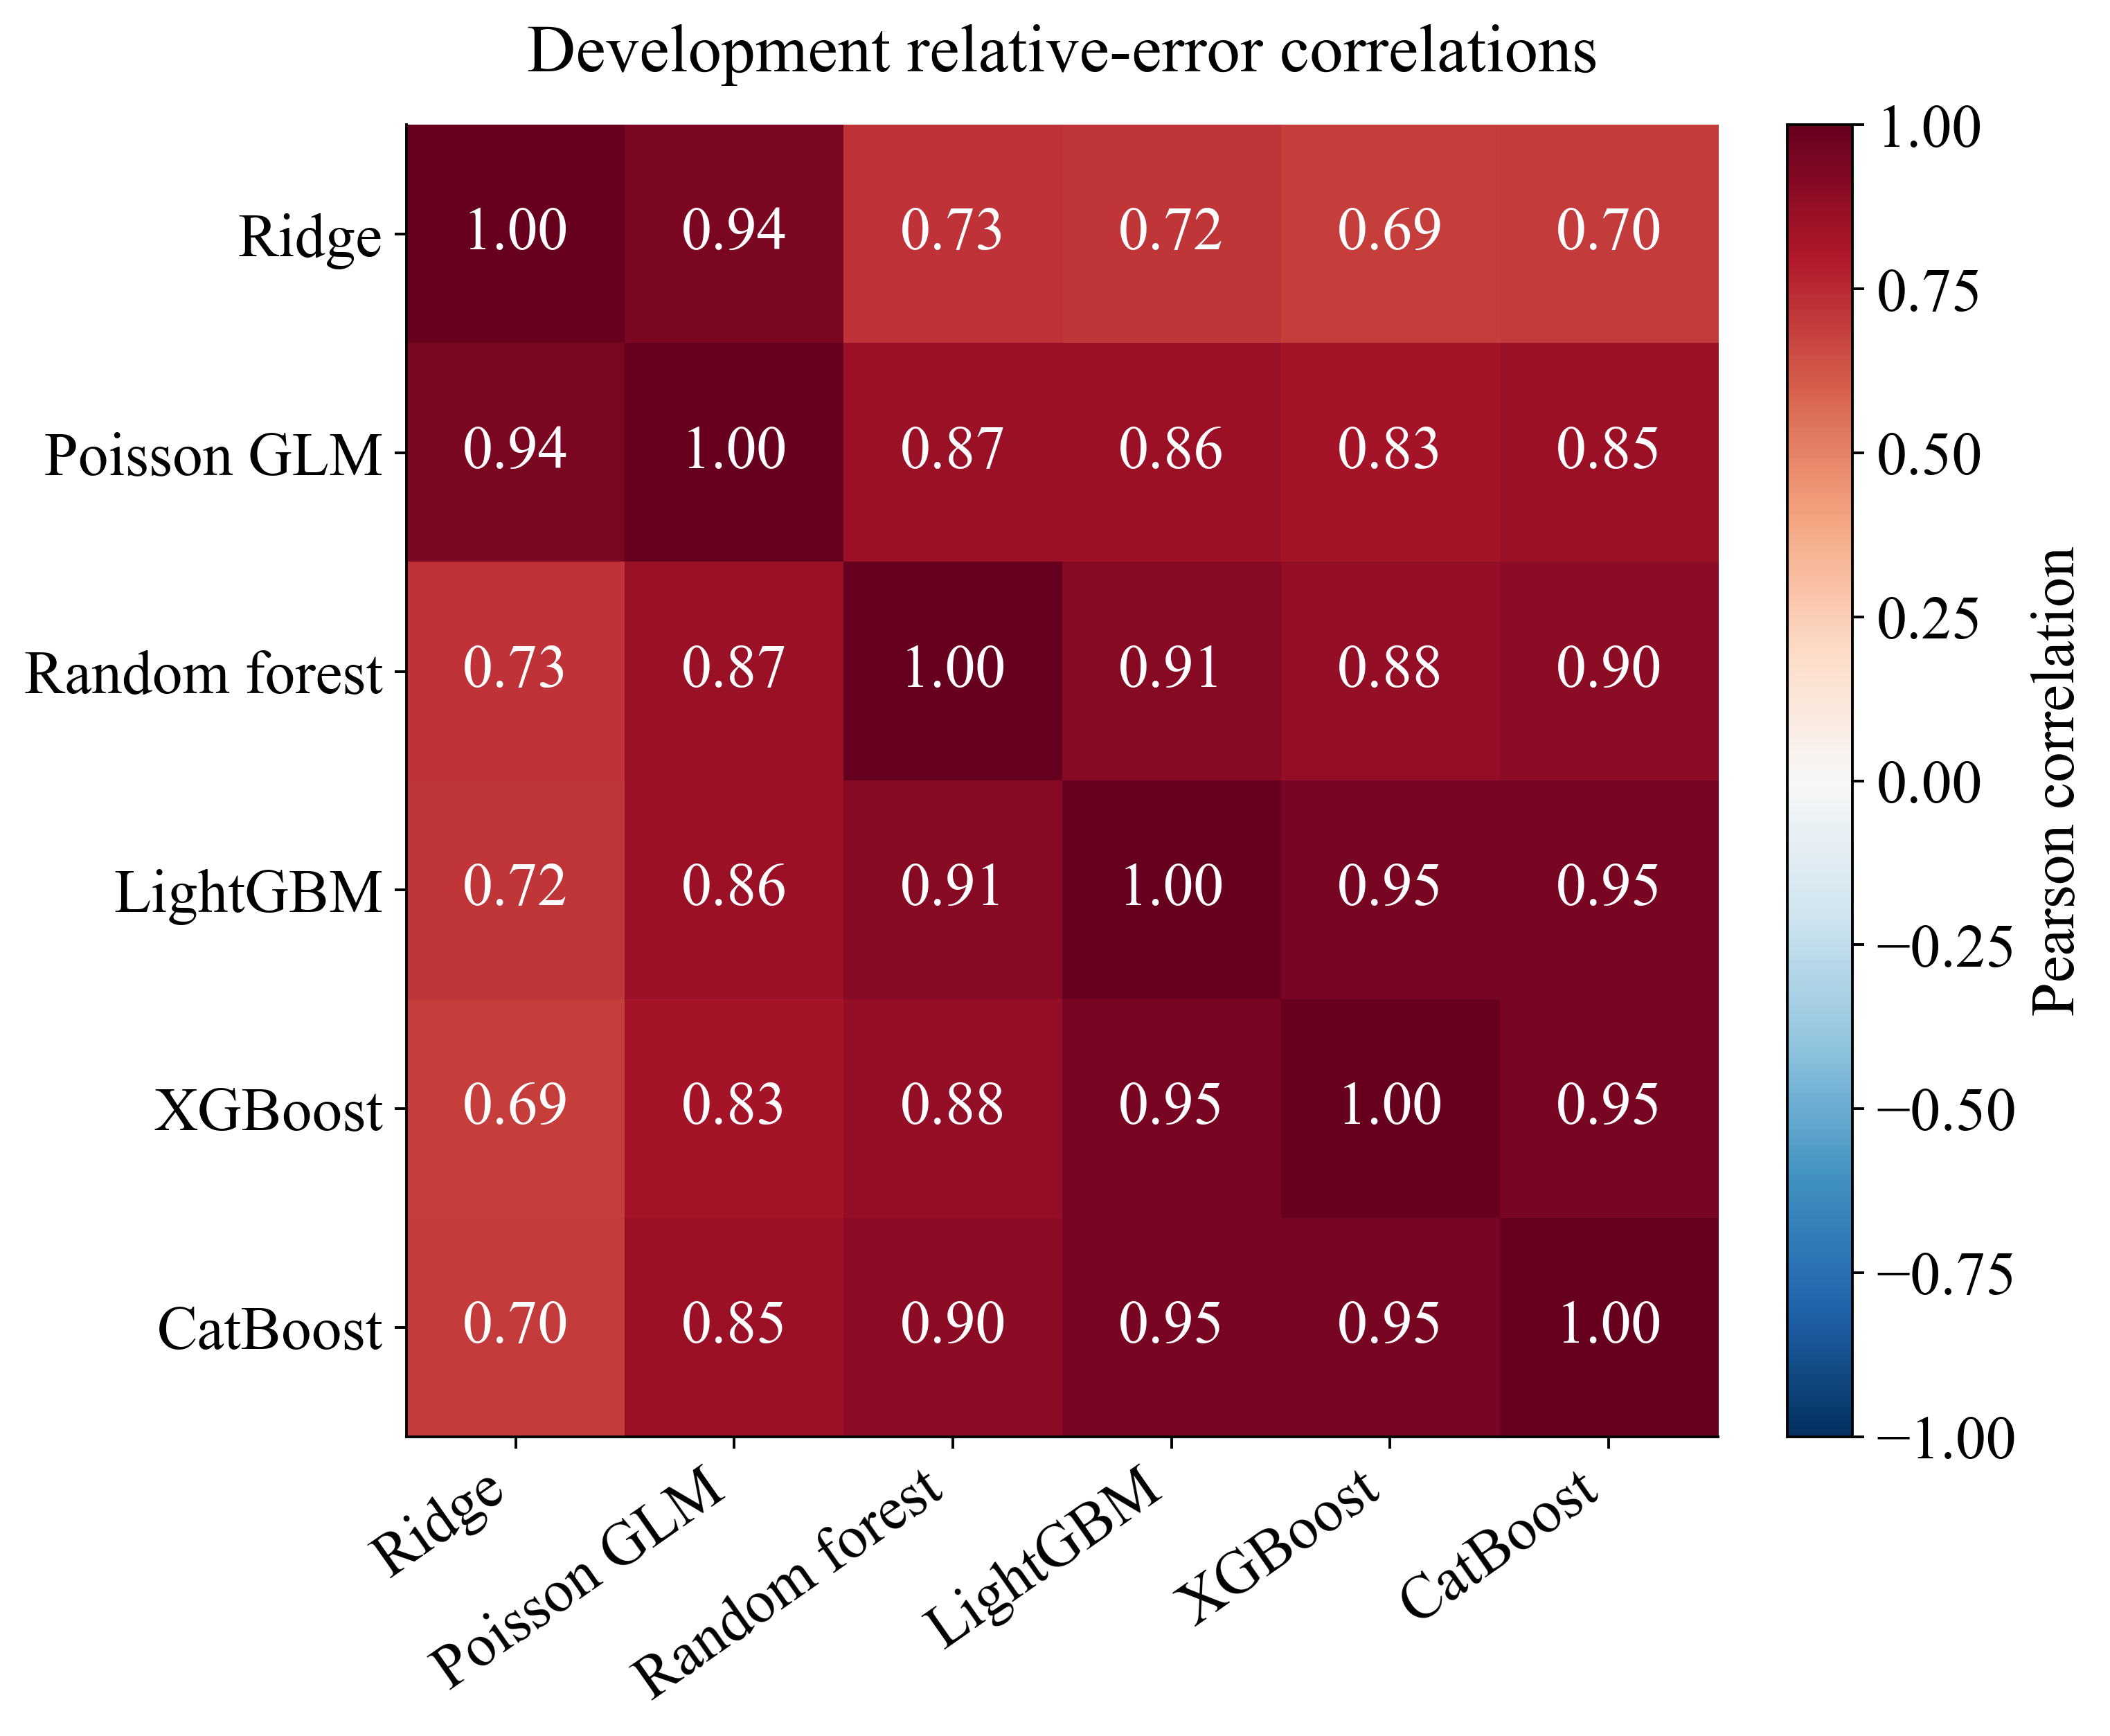

,Week,Model,RMSPE
9,28,CatBoost,0.52113
19,29,CatBoost,0.51024
22,30,Positive-history action,0.46785
32,31,Positive-history action,0.45206
49,32,CatBoost,0.49492
52,33,Positive-history action,0.46859
62,34,Positive-history action,0.48210
72,35,Positive-history action,0.45991
89,36,CatBoost,0.51957
92,37,Positive-history action,0.43192


,Model,Rowwise win fraction,Max error correlation with another
0,Lag 2,0.14898,0.86672
1,Historical mean,0.15541,0.95033
2,Positive-history action,0.14559,0.86754
3,Croston-SBA,0.08610,0.86672
4,Ridge,0.02715,0.94449
5,Poisson GLM,0.10432,0.94449
6,Random forest,0.11861,0.91884
7,LightGBM,0.07181,0.95047
8,XGBoost,0.07288,0.94806
9,CatBoost,0.06913,0.95047


Row-wise oracle RMSPE (best model chosen after observing each target; not an implementable forecast): 0.21388.

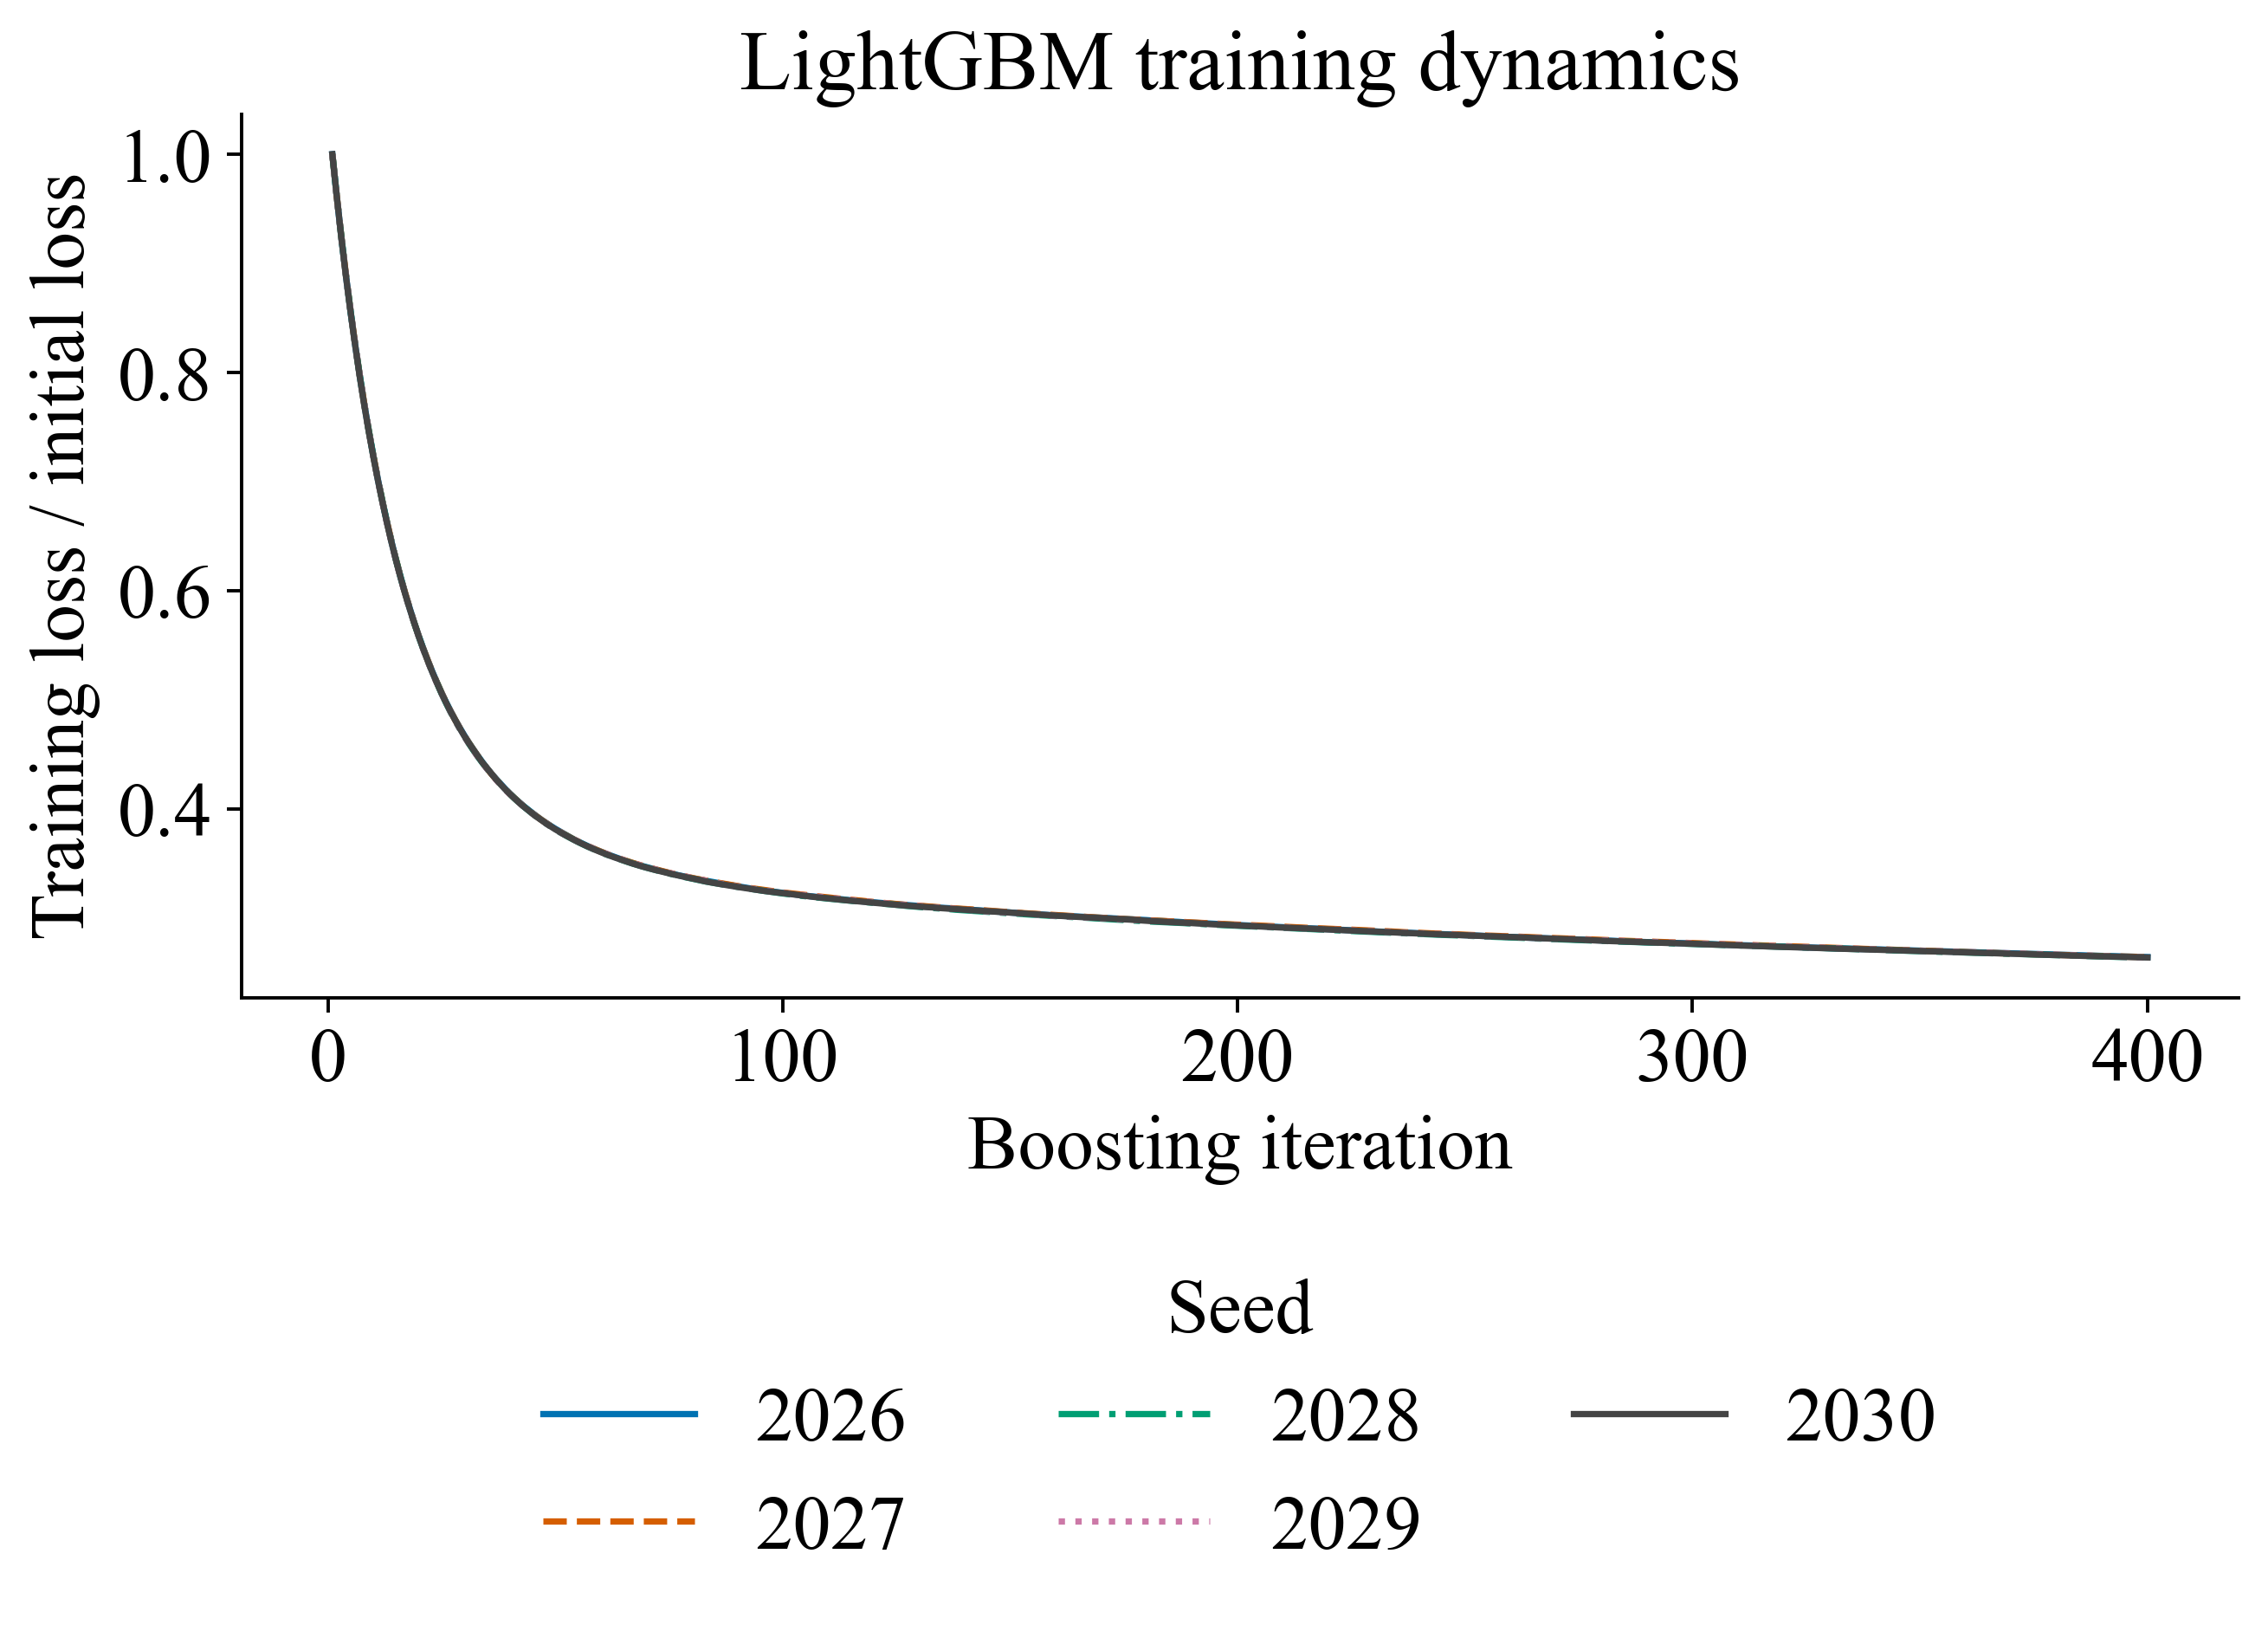

In [14]:
# NB03_DIAGNOSTICS: measured complementarity and actual training-loss trajectories
positive=y>0;err=pd.DataFrame({name:(PREDICTIONS[(name,2026)][positive]-y[positive])/y[positive] for name in MODEL_ORDER})
error_corr=err.corr();error_corr.to_csv(OUT/'error_correlations_full.csv')
learned=['Ridge','Poisson GLM','Random forest','LightGBM','XGBoost','CatBoost'];mat=error_corr.loc[learned,learned]
fig,ax=plt.subplots(figsize=(10.8,8.2));im=ax.imshow(mat,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(6),labels=learned,rotation=35,ha='right');ax.set_yticks(range(6),labels=learned)
for i in range(6):
 for j in range(6):
  v=mat.iloc[i,j];ax.text(j,i,f'{v:.2f}'.replace('-','−'),ha='center',va='center',color='white' if abs(v)>.55 else 'black',fontsize=18)
ax.set_title('Development relative-error correlations',pad=16);fig.colorbar(im,ax=ax,fraction=.046,pad=.04,label='Pearson correlation');fig.subplots_adjust(left=.24,bottom=.26,right=.9,top=.92)
figure(fig,'fig_uci_baseline_error_correlation')
weekly=[]
for week,block in DEV.groupby('week'):
 mask=DEV.week.to_numpy()==week
 for name in MODEL_ORDER:weekly.append({'Week':int(week),'Model':name,**metrics(y[mask],PREDICTIONS[(name,2026)][mask])})
weekly=pd.DataFrame(weekly);weekly.to_csv(OUT/'weekly_metrics.csv',index=False)
winners=weekly.loc[weekly.groupby('Week').RMSPE.idxmin(),['Week','Model','RMSPE']];table(winners,'weekly_winners')
win_counts=pd.Series(np.argmin(err.to_numpy()**2,axis=1)).value_counts()
complement=pd.DataFrame([{'Model':name,'Rowwise win fraction':int(win_counts.get(i,0))/len(err),'Max error correlation with another':float(error_corr.loc[name].drop(name).max())} for i,name in enumerate(MODEL_ORDER)])
table(complement,'error_complementarity')
oracle=float(np.sqrt(np.mean(np.min(err.to_numpy()**2,axis=1))))
display(Markdown(f'Row-wise oracle RMSPE (best model chosen after observing each target; not an implementable forecast): {oracle:.5f}.'))
# Training curves are generated by actual fitted LightGBM models; rescale within each seed.
curve_rows=[]
for seed in PLAN['seeds']:
 curve=CURVES[f'LightGBM|final|{seed}'];series=next(iter(next(iter(curve.values())).values()))
 for iteration,value in enumerate(series,1):curve_rows.append({'Seed':seed,'Iteration':iteration,'Training loss':float(value),'Relative to first iteration':float(value/series[0])})
curve_frame=pd.DataFrame(curve_rows);curve_frame.to_csv(OUT/'lightgbm_training_curves.csv',index=False)
fig,ax=plt.subplots(figsize=(8.5,5.3))
colors=['#0072B2','#D55E00','#009E73','#CC79A7','#444444'];styles=['-','--','-.',':','-']
for seed,color,style in zip(PLAN['seeds'],colors,styles):
 b=curve_frame[curve_frame.Seed==seed];ax.plot(b.Iteration,b['Relative to first iteration'],color=color,ls=style,label=str(seed))
ax.set(xlabel='Boosting iteration',ylabel='Training loss / initial loss',title='LightGBM training dynamics')
ax.legend(title='Seed',loc='upper center',bbox_to_anchor=(.5,-.24),frameon=False,ncol=3);fig.subplots_adjust(bottom=.33)
figure(fig,'fig_uci_baseline_training_dynamics')

In [15]:
# NB03_REGISTRY: model order and selected configurations for notebooks 04-06; run registry
manifest={'run_id':RUN_ID,'model_order':MODEL_ORDER,'selected_configurations':CONFIGS}
dump(BASE/'Manifests/baseline_manifest.json',manifest)
latest_path=BASE/'Manifests/latest_runs.json';latest=json.loads(latest_path.read_text()) if latest_path.exists() else {};latest['NB03']=RUN_ID;dump(latest_path,latest)

# Part C · M5 (Walmart) weekly item-store sales

## Baseline models and error diagnostics

In [1]:
# NB03_SETUP: packages, paths, search plan and helpers (same conventions as Part B)
import os
os.environ['OMP_NUM_THREADS']='4';os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,platform,sys,resource,gzip,importlib.metadata,inspect,warnings,io,csv,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from scipy import special,stats
THREAD_LIMIT=threadpool_limits(limits=4)
SEED=2026
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'m5'
for sub in ['Artifacts','Configs','Manifests']:(BASE/sub).mkdir(parents=True,exist_ok=True)
RUN_ID='NB03_M5_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False,default=str))
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False,'mathtext.fontset':'custom','mathtext.rm':'Times New Roman','mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold','mathtext.default':'regular'})
PALETTE=['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7','#56B4E9','#000000']  # Okabe-Ito, colour-blind safe
pd.set_option('display.max_rows',200,'display.max_columns',20,'display.max_colwidth',None,'display.width',220,'display.float_format',lambda v:f'{v:.5f}')
def tidy(df,note='n/a'):
    """Display copy of a table: missing cells are marked explicitly instead of NaN; underflowed p-values are shown as bounds."""
    out=df.copy()
    for c in out.columns:
        if str(c)=='p' or str(c).startswith('p ') or 'p-value' in str(c) or str(c).startswith('Holm p'):
            out[c]=['< 1e-300' if (isinstance(v,float) and v==0.0) else (f'{v:.4g}' if isinstance(v,(float,np.floating)) else v) for v in out[c]]
    return out.astype(object).where(out.notna(),note)
def table(df,name,best=None,fmt='%.5f'):
    clean=tidy(df.reset_index() if df.index.name is not None else df)
    clean.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(clean.to_latex(index=False,float_format=fmt,escape=True))
    if best:display(clean.style.format({k:(lambda v:(fmt%v) if isinstance(v,(float,np.floating)) else v) for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(clean)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))
def label_panels(axes,labels='abcdefgh'):
    """Letter each panel below its x-axis label, (a), (b), ..., so that panels can be cited."""
    for ax,l in zip(np.ravel(axes),labels):ax.set_xlabel((ax.get_xlabel()+'\n' if ax.get_xlabel() else '')+f'({l})')
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def rmspe(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))

from sklearn.linear_model import Ridge,PoissonRegressor
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import shutil
# Families and configurations of the UCI plan (Part B) with the M5 budget rules
PLAN=json.loads((ROOT/'outputs'/'uci'/'Configs'/'baseline_search.json').read_text());PLAN['forest_trees']=100;PLAN['forest_max_samples']=0.2;PLAN['search_cohort_share']=0.2;PLAN['fit_window_weeks']=104
PLAN['F0']={'fit_latest_week':239,'evaluation_weeks':[241,243]};PLAN['nested_calibration_weeks']=[245,251];PLAN['development_weeks']=[253,263];PLAN['initial_fit_latest_week']=251;PLAN['panel']='M5 weekly'
dump(BASE/'Configs/baseline_search.json',PLAN)
FM=json.loads((BASE/'Manifests/feature_manifest.json').read_text())

### Common rows, fit windows and fitted-fold numerical transformations

In [2]:
# NB03_DATA: exact common rows, search cohort and fitted-fold transformations
rows=pd.read_parquet(BASE/'Data/causal_features_core.parquet');rows=rows.sort_values(['week','id']).reset_index(drop=True)
wide=pd.read_parquet(BASE/'Data/core_permitted_wide.parquet');wide.columns=[int(c) for c in wide.columns];CORE_IDS=wide.index.tolist();assert rows.id.nunique()==len(CORE_IDS) and rows.row_id.is_unique
FEATURES=FM['features'];COUNT=FM['count_features'];MISSING=FM['missing_indicator_features'];ONE_HOT=FM['one_hot'];NAMES=FEATURES+[f'{x}_missing' for x in MISSING]+ONE_HOT
class FoldPreprocessor:
    def fixed(self,frame):
        a=frame[FEATURES].astype(float).copy();assert (a[COUNT].ge(0)|a[COUNT].isna()).all().all();a[COUNT]=np.log1p(a[COUNT]);return a
    def fit(self,frame):
        a=self.fixed(frame);self.median=a.median();assert self.median.notna().all();b=a.fillna(self.median);self.scale=(b.quantile(.75)-b.quantile(.25));self.scale=self.scale.where(self.scale>0,1.);self.fit_rows=len(frame);return self
    def transform(self,frame):
        a=self.fixed(frame);z=(a.fillna(self.median)-self.median)/self.scale
        for k in MISSING:z[k+'_missing']=a[k].isna().astype(float)
        z[ONE_HOT]=frame[ONE_HOT].to_numpy(np.float32);out=z[NAMES].astype(np.float32);assert np.isfinite(out.to_numpy()).all();return out
    def parameters(self):return {'features':FEATURES,'median':self.median.to_dict(),'scale':self.scale.to_dict(),'fit_rows':self.fit_rows}
STAGES={'F0':(239,(241,243)),'F1':(243,(245,248)),'F2':(247,(249,252)),'Initial':(251,(253,263))};FITW=PLAN['fit_window_weeks']
hash_key=lambda x:hashlib.sha256(('assem-m5-search-2026:'+x).encode()).hexdigest()
SEARCH_IDS=set(sorted(CORE_IDS,key=hash_key)[:int(np.ceil(PLAN['search_cohort_share']*len(CORE_IDS)))]);rows['search']=rows.id.isin(SEARCH_IDS)
DATA={};PREP={}
for stage,(last,bounds) in STAGES.items():
    tr=rows[rows.week.between(last-FITW+1,last)];ev=rows[rows.week.between(*bounds)].copy();p=FoldPreprocessor().fit(tr);assert tr.week.max()<=ev.week.min()-2
    PREP[stage]=p;DATA[stage]={'train':tr,'eval':ev,'y':tr.quantity.to_numpy(dtype=float),'ye':ev.quantity.to_numpy(float)}
    dump(OUT/f'preprocessor_{stage}.json',p.parameters())
def X_of(stage,part,cohort='all'):
    d=DATA[stage];frame=d['train'] if part=='train' else d['eval']
    if cohort=='search':frame=frame[frame.search]
    return PREP[stage].transform(frame),frame
DEV=DATA['Initial']['eval'];CAL=rows[rows.week.between(245,251)]
table(pd.DataFrame([{'Model':m,'Configurations':len(g),'Search seed':2026,'Final fits':5 if m in PLAN['stochastic'] else (1 if m in ['Ridge','Poisson GLM'] else 0)} for m,g in PLAN['grid'].items()]),'fixed_model_budget')
table(pd.DataFrame([{'Stage':k,'Fit weeks':f'W{v[0]-FITW+1}–W{v[0]}','Forecast weeks':f'W{v[1][0]}–W{v[1][1]}','Fit rows (all / search cohort)':f"{len(DATA[k]['train']):,} / {int(DATA[k]['train'].search.sum()):,}",'Forecast rows (all / search cohort)':f"{len(DATA[k]['eval']):,} / {int(DATA[k]['eval'].search.sum()):,}"} for k,v in STAGES.items()]),'nested_timeline')
print(f'Core series {len(CORE_IDS):,}; search cohort {len(SEARCH_IDS):,}; processed predictors {len(NAMES)}')

,Model,Configurations,Search seed,Final fits
0,Lag 2,1,2026,0
1,Historical mean,8,2026,0
2,Positive-history action,8,2026,0
3,Croston-SBA,8,2026,0
4,Ridge,8,2026,1
5,Poisson GLM,8,2026,1
6,Random forest,8,2026,5
7,LightGBM,8,2026,5
8,XGBoost,8,2026,5
9,CatBoost,8,2026,5


,Stage,Fit weeks,Forecast weeks,Fit rows (all / search cohort),Forecast rows (all / search cohort)
0,F0,W136–W239,W241–W243,"2,853,864 / 570,856","82,323 / 16,467"
1,F1,W140–W243,W245–W248,"2,853,864 / 570,856","109,764 / 21,956"
2,F2,W144–W247,W249–W252,"2,853,864 / 570,856","109,764 / 21,956"
3,Initial,W148–W251,W253–W263,"2,853,864 / 570,856","301,851 / 60,379"


Core series 27,441; search cohort 5,489; processed predictors 67


### Forecast rules, estimators and metrics

In [3]:
# NB03_METHODS
HISTORY={'Lag 2','Historical mean','Positive-history action','Croston-SBA'};CACHE={};SEARCH={};NESTED={};PREDICTIONS={};CONFIGS={};FROZEN_MODELS={};RESOURCES=[];TRIALS=[];NET_THREADS=4
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
W_ALL=wide.to_numpy(float)
def historical_predict(name,cfg,frame):
    key=(name,json.dumps(cfg,sort_keys=True))
    if key not in CACHE:
        forecasts=[]
        for origin in sorted(rows.week.unique()):
            h=W_ALL[:,:origin-1]
            if name=='Lag 2':point=h[:,-1]
            elif name=='Historical mean':
                rec=h if cfg['window'] is None else h[:,-cfg['window']:];point=rec.mean(axis=1)
                if cfg['market_adjust']:point=point*(h[:,-4:].mean()/max(h.mean(),1e-12))
            elif name=='Positive-history action':
                rec=h if cfg['window'] is None else h[:,-cfg['window']:];inverse=np.divide(1,rec,out=np.zeros_like(rec),where=rec>0);all_inverse=np.divide(1,h,out=np.zeros_like(h),where=h>0);n=(h>0).sum();m1=all_inverse.sum()/max(n,1);m2=(all_inverse**2).sum()/max(n,1)
                den=(inverse**2).sum(axis=1)+cfg['strength']*m2;point=np.divide(inverse.sum(axis=1)+cfg['strength']*m1,den,out=np.zeros(len(h)),where=den>0)
            else:
                alpha=cfg['alpha'];pos=h>0;size=np.zeros(len(h));interval=np.zeros(len(h));last=np.full(len(h),-1.0);started=np.zeros(len(h),bool)
                for t in range(h.shape[1]):  # vectorised Croston-SBA recursion over series
                    e=pos[:,t];first=e&~started;cont=e&started
                    size[first]=h[first,t];interval[first]=t+1;last[first]=t;started|=first
                    size[cont]=alpha*h[cont,t]+(1-alpha)*size[cont];interval[cont]=alpha*(t-last[cont])+(1-alpha)*interval[cont];last[cont]=t
                point=np.where(started,(1-alpha/2)*size/np.maximum(interval,1e-9),0.0)
            forecasts.append(pd.DataFrame({'row_id':wide.index+'::W'+str(origin),'prediction':point}))
        CACHE[key]=pd.concat(forecasts).set_index('row_id').prediction
    return CACHE[key].reindex(frame.row_id).to_numpy()
def estimator(name,cfg,seed):
    if name=='Ridge':return Ridge(alpha=cfg['alpha'],solver='auto')
    if name=='Poisson GLM':return PoissonRegressor(alpha=cfg['alpha'],max_iter=500,tol=1e-6)
    if name=='Random forest':return RandomForestRegressor(n_estimators=PLAN['forest_trees'],max_depth=cfg['depth'],min_samples_leaf=cfg['leaf'],max_features=.8,max_samples=PLAN['forest_max_samples'],n_jobs=NET_THREADS,random_state=seed)
    if name=='LightGBM':return lgb.LGBMRegressor(objective='poisson' if cfg['loss']=='poisson' else 'regression',n_estimators=400,learning_rate=.04,num_leaves=cfg['leaves'],min_child_samples=cfg['min_child'],reg_lambda=5.,subsample=.9,subsample_freq=1,colsample_bytree=.9,n_jobs=NET_THREADS,random_state=seed,verbosity=-1,deterministic=True,force_col_wise=True)
    if name=='XGBoost':return XGBRegressor(objective='count:poisson' if cfg['loss']=='poisson' else 'reg:squarederror',n_estimators=400,learning_rate=.04,max_depth=cfg['depth'],min_child_weight=cfg['min_child'],reg_lambda=5.,subsample=.9,colsample_bytree=.9,tree_method='hist',n_jobs=NET_THREADS,random_state=seed)
    if name=='CatBoost':return CatBoostRegressor(loss_function='Poisson' if cfg['loss']=='poisson' else 'RMSE',iterations=400,learning_rate=.04,depth=cfg['depth'],l2_leaf_reg=cfg['l2'],thread_count=NET_THREADS,random_seed=seed,verbose=False,allow_writing_files=False)
    raise ValueError(name)
def fit_predict(name,cfg,seed,stage,tag,cohort='all'):
    started=time.perf_counter();model=None
    if name in HISTORY:
        _,ev=X_of(stage,'eval',cohort);point=historical_predict(name,cfg,ev);fit_seconds=0.
    else:
        X,tr=X_of(stage,'train',cohort);Xe,ev=X_of(stage,'eval',cohort);y=tr.quantity.to_numpy(float);model=estimator(name,cfg,seed);target=np.log1p(y) if cfg.get('target')=='log1p' else y;kwargs={}
        if cfg.get('loss')=='relative_l2':weights=1/np.maximum(y,1)**2;kwargs['sample_weight']=weights/weights.mean()
        model.fit(X,target,**kwargs);fit_seconds=time.perf_counter()-started;point=model.predict(Xe)
        if cfg.get('target')=='log1p':point=np.expm1(point)
        point=np.maximum(0,point)
    assert np.isfinite(point).all() and (point>=0).all()
    RESOURCES.append({'Model':name,'Tag':tag,'Stage':stage,'Cohort':cohort,'Seed':seed,'Actual learner fit':int(model is not None),'Fit rows':int(DATA[stage]['train'].search.sum()) if cohort=='search' else len(DATA[stage]['train']),'Forecast rows':len(point),'Fit seconds':fit_seconds,'Total seconds':time.perf_counter()-started,'Process peak MiB':resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/2**20})
    return point,model

### Search and nested historical predictions

In [4]:
# NB03_ENGINE
def score_candidate(name,index,stages,latest):
    ys=[];ps=[]
    for st in stages:
        _,ev=X_of(st,'eval','search');mask=ev.week.to_numpy()<=latest;ys.append(ev.quantity.to_numpy()[mask]);ps.append(SEARCH[(name,index,st)][mask])
    return metrics(np.concatenate(ys),np.concatenate(ps))
def select_config(name,stages,latest):
    return min((score_candidate(name,j,stages,latest)['RMSPE'],score_candidate(name,j,stages,latest)['MAE'],j) for j in range(len(PLAN['grid'][name])))[2]
def run_family(name):
    grid=PLAN['grid'][name];progress=display(pd.DataFrame([{'Model':name,'Completed candidate paths':0,'Total candidate paths':3*len(grid)}]),display_id=True);t0=time.time()
    for j,cfg in enumerate(grid):
        for stage in ['F0','F1','F2']:SEARCH[(name,j,stage)]=fit_predict(name,cfg,SEED,stage,f'{name}|search{j}|{stage}','search')[0]
        progress.update(pd.DataFrame([{'Model':name,'Completed candidate paths':3*(j+1),'Total candidate paths':3*len(grid),'Elapsed s':int(time.time()-t0)}]))
    nested_choice={'F1':select_config(name,['F0'],243),'F2':select_config(name,['F0','F1'],247)};blocks=[]
    for st in ['F1','F2']:
        p,_=fit_predict(name,grid[nested_choice[st]],SEED,st,f'{name}|nested|{st}','all');ev=DATA[st]['eval'];keep=(ev.week<=251).to_numpy();b=ev.loc[keep,['row_id','id','week','quantity']].copy();b['prediction']=p[keep];b['configuration']=nested_choice[st];b['model']=name;blocks.append(b)
    NESTED[name]=pd.concat(blocks,ignore_index=True);assert NESTED[name].row_id.tolist()==CAL.row_id.tolist()
    nested_scores=[]
    for j in range(len(grid)):
        m=score_candidate(name,j,['F1','F2'],251);nested_scores.append((m['RMSPE'],m['MAE'],j));TRIALS.append({'Model':name,'Configuration':j,'Selected':False,**m})
    selected=min(nested_scores)[2];cfg=grid[selected]
    for t in TRIALS:
        if t['Model']==name and t['Configuration']==selected:t['Selected']=True
    CONFIGS[name]={'selected_index':selected,'parameters':cfg,'nested_indices':nested_choice}
    seeds=PLAN['seeds'] if name in PLAN['stochastic'] else [SEED]
    for seed in seeds:
        p,model=fit_predict(name,cfg,seed,'Initial',f'{name}|final|{seed}','all');PREDICTIONS[(name,seed)]=p
        if seed==SEED:FROZEN_MODELS[name]=model
        progress.update(pd.DataFrame([{'Model':name,'Completed candidate paths':3*len(grid),'Latest final seed':seed,'Elapsed s':int(time.time()-t0)}]))
    table(pd.DataFrame([{'Model':name,'Selected configuration':selected,'Nested F1 configuration':nested_choice['F1'],'Nested F2 configuration':nested_choice['F2'],'Actual final fits':len(seeds) if name not in HISTORY else 0,**cfg}]),name.lower().replace(' ','_')+'_selection')
    table(pd.DataFrame([{'Model':name,**metrics(DEV.quantity,PREDICTIONS[(name,SEED)])}]).drop(columns=['Positive_n','Zero_n','R2','sMAPE_pct']),name.lower().replace(' ','_')+'_development')
    dump(OUT/'selected_configurations.json',CONFIGS);pd.DataFrame(RESOURCES).to_csv(OUT/'fit_resources.csv',index=False)
    np.savez_compressed(OUT/'development_predictions.npz',**{f'{list(PLAN["grid"]).index(k[0])}_{k[1]}':v.astype(np.float32) for k,v in PREDICTIONS.items()})
    pd.concat(NESTED.values(),ignore_index=True).to_parquet(OUT/'nested_oof.parquet',index=False)
    with gzip.open(OUT/'fitted_models.pkl.gz','wb') as f:cloudpickle.dump({'models':FROZEN_MODELS,'configurations':CONFIGS,'feature_names':NAMES},f)

### Historical and intermittent-demand baselines

In [5]:
# NB03_HISTORY
for name in ['Lag 2','Historical mean','Positive-history action','Croston-SBA']:run_family(name)

,Model,Completed candidate paths,Latest final seed,Elapsed s
0,Lag 2,3,2026,2


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits
0,Lag 2,0,0,0,0


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Lag 2,1.84326,11.10843,4.29452,1.46984


,Model,Completed candidate paths,Latest final seed,Elapsed s
0,Historical mean,24,2026,15


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,window,market_adjust
0,Historical mean,0,6,0,0,4,False


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Historical mean,1.61095,10.35556,3.76177,1.80759


... (2 outputs left out)

,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Positive-history action,0.65215,20.83487,7.42326,1.82827


,Model,Completed candidate paths,Latest final seed,Elapsed s
0,Croston-SBA,24,2026,150


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,alpha
0,Croston-SBA,7,7,7,0,0.70000


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Croston-SBA,1.13515,12.23502,4.89478,2.70793


### Regularized linear and count regression

In [6]:
# NB03_LINEAR
for name in ['Ridge','Poisson GLM']:run_family(name)

,Model,Completed candidate paths,Latest final seed,Elapsed s
0,Ridge,24,2026,111


.../site-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.016e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


.../site-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.22881e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


.../site-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=3.23272e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


.../site-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.016e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


.../site-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.22881e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


... (11 outputs left out)

.../site-packages/sklearn/linear_model/_glm/glm.py:290: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result(


.../site-packages/sklearn/linear_model/_glm/glm.py:290: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result(


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,alpha
0,Poisson GLM,0,0,0,1,0.00100


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Poisson GLM,1.55270,9.67846,3.75936,2.52536


### Random forest

In [7]:
# NB03_FOREST
run_family('Random forest')

,Model,Completed candidate paths,Latest final seed,Elapsed s
0,Random forest,24,2030,3356


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,depth,leaf,target
0,Random forest,5,5,5,5,n/a,5,log1p


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Random forest,0.96930,10.26930,3.84016,1.45765


### LightGBM

In [8]:
# NB03_LIGHTGBM
run_family('LightGBM')

,Model,Completed candidate paths,Latest final seed,Elapsed s
0,LightGBM,24,2030,703


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,leaves,min_child,loss
0,LightGBM,5,7,7,5,31,30,relative_l2


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,LightGBM,0.72329,20.79464,7.54594,0.45456


### XGBoost

In [9]:
# NB03_XGBOOST
run_family('XGBoost')

,Model,Completed candidate paths,Latest final seed,Elapsed s
0,XGBoost,24,2030,423


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,depth,min_child,loss
0,XGBoost,5,5,5,5,6,5,relative_l2


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,XGBoost,0.72339,20.85676,7.56612,0.45350


### CatBoost

In [10]:
# NB03_CATBOOST
run_family('CatBoost')

,Model,Completed candidate paths,Latest final seed,Elapsed s
0,CatBoost,24,2030,748


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,depth,l2,loss
0,CatBoost,5,5,5,5,6,3.00000,relative_l2


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,CatBoost,0.73424,21.24598,7.79965,0.45496


### Development comparison, supports and seed stability

In [11]:
# NB03_COMPARISON
MODEL_ORDER=list(PLAN['grid']);comparison=pd.DataFrame([{'Model':name,**metrics(DEV.quantity,PREDICTIONS[(name,SEED)])} for name in MODEL_ORDER]).sort_values('RMSPE').reset_index(drop=True)
table(comparison[['Model','RMSPE','RMSE','MAE','Zero_MAE']],'development_accuracy',['RMSPE','RMSE','MAE','Zero_MAE']);table(comparison[['Model','sMAPE_pct','R2','Positive_n','Zero_n']],'development_support')
seed_rows=[]
for name in MODEL_ORDER:
    seeds=PLAN['seeds'] if name in PLAN['stochastic'] else [SEED];values=[metrics(DEV.quantity,PREDICTIONS[(name,s)])['RMSPE'] for s in seeds]
    seed_rows.append({'Model':name,'Actual seeds':len(seeds),'Mean RMSPE':np.mean(values),'SD RMSPE':np.std(values,ddof=1) if len(values)>1 else np.nan,'Minimum RMSPE':np.min(values),'Maximum RMSPE':np.max(values)})
table(pd.DataFrame(seed_rows),'seed_stability');pd.DataFrame(TRIALS).to_csv(OUT/'all_search_trials.csv',index=False)
table(pd.DataFrame(RESOURCES).groupby('Model',sort=False).agg(actual_fits=('Actual learner fit','sum'),fit_seconds=('Fit seconds','sum'),total_seconds=('Total seconds','sum'),process_peak_MiB=('Process peak MiB','max')).reset_index(),'resource_totals')
DEV[['row_id','id','week','quantity']].to_parquet(OUT/'development_rows.parquet',index=False)
for stage in ['F0','F1','F2']:DATA[stage]['eval'].loc[DATA[stage]['eval'].search,['row_id','id','week','quantity']].to_parquet(OUT/f'search_rows_{stage}.parquet',index=False)
y=DEV.quantity.to_numpy(float);wk=DEV.week.to_numpy();weeks=sorted(DEV.week.unique())
weekly=pd.DataFrame({m:[metrics(y[wk==w],PREDICTIONS[(m,SEED)][wk==w])['RMSPE'] for w in weeks] for m in MODEL_ORDER},index=weeks);weekly.rename_axis('Week').reset_index().to_csv(OUT/'weekly_metrics.csv',index=False)

,Model,RMSPE,RMSE,MAE,Zero_MAE
0,Positive-history action,0.65215,20.83487,7.42326,1.82827
1,LightGBM,0.72329,20.79464,7.54594,0.45456
2,XGBoost,0.72339,20.85676,7.56612,0.45350
3,CatBoost,0.73424,21.24598,7.79965,0.45496
4,Random forest,0.96930,10.26930,3.84016,1.45765
5,Croston-SBA,1.13515,12.23502,4.89478,2.70793
6,Ridge,1.19578,10.43800,3.84286,1.50191
7,Poisson GLM,1.55270,9.67846,3.75936,2.52536
8,Historical mean,1.61095,10.35556,3.76177,1.80759
9,Lag 2,1.84326,11.10843,4.29452,1.46984


,Model,sMAPE_pct,R2,Positive_n,Zero_n
0,Positive-history action,110.63718,-0.05911,232227,69624
1,LightGBM,131.26867,-0.05502,232227,69624
2,XGBoost,130.52959,-0.06133,232227,69624
3,CatBoost,133.91302,-0.10132,232227,69624
4,Random forest,86.40499,0.74270,232227,69624
5,Croston-SBA,95.95065,0.63477,232227,69624
6,Ridge,86.95096,0.73418,232227,69624
7,Poisson GLM,80.56566,0.77146,232227,69624
8,Historical mean,69.21054,0.73836,232227,69624
9,Lag 2,70.14900,0.69893,232227,69624


,Model,Actual seeds,Mean RMSPE,SD RMSPE,Minimum RMSPE,Maximum RMSPE
0,Lag 2,1,1.84326,n/a,1.84326,1.84326
1,Historical mean,1,1.61095,n/a,1.61095,1.61095
2,Positive-history action,1,0.65215,n/a,0.65215,0.65215
3,Croston-SBA,1,1.13515,n/a,1.13515,1.13515
4,Ridge,1,1.19578,n/a,1.19578,1.19578
5,Poisson GLM,1,1.55270,n/a,1.55270,1.55270
6,Random forest,5,0.97176,0.00703,0.96261,0.98203
7,LightGBM,5,0.72311,0.00032,0.72253,0.72329
8,XGBoost,5,0.72323,0.00042,0.72272,0.72383
9,CatBoost,5,0.73409,0.00030,0.73375,0.73443


,Model,actual_fits,fit_seconds,total_seconds,process_peak_MiB
0,Lag 2,0,0.00000,1.96405,5170.14062
1,Historical mean,0,0.00000,13.85189,5170.14062
2,Positive-history action,0,0.00000,58.58251,5170.14062
3,Croston-SBA,0,0.00000,148.78894,5170.14062
4,Ridge,27,109.06592,109.21093,6144.03125
5,Poisson GLM,27,1476.98111,1477.17848,6144.03125
6,Random forest,31,3342.08280,3354.05028,6144.03125
7,LightGBM,31,691.72868,700.99222,6144.03125
8,XGBoost,31,419.24314,421.13369,6144.03125
9,CatBoost,31,745.93490,746.24028,6144.03125


### Common nested residual distributions, error complementarity and weekly winners

,Model,PICP90,Coverage error,MPIW90
0,Lag 2,0.914759,0.01476,14.660269
1,Historical mean,0.951151,0.05115,16.818652
2,Positive-history action,0.914030,0.01403,22.119085
3,Croston-SBA,0.910413,0.01041,13.902445
4,Ridge,0.916827,0.01683,11.659660
5,Poisson GLM,0.916449,0.01645,11.548814
6,Random forest,0.914763,0.01476,11.207652
7,LightGBM,0.935872,0.03587,23.226499
8,XGBoost,0.938668,0.03867,23.912059
9,CatBoost,0.938788,0.03879,27.143657


,Model,CRPS,Zero Brier
0,Lag 2,3.30155,0.12662
1,Historical mean,2.88306,0.11758
2,Positive-history action,5.68828,0.17003
3,Croston-SBA,3.53742,0.15644
4,Ridge,2.89257,0.12315
5,Poisson GLM,2.83732,0.12846
6,Random forest,2.86640,0.12212
7,LightGBM,5.35269,0.14263
8,XGBoost,5.35264,0.14219
9,CatBoost,5.63182,0.14365


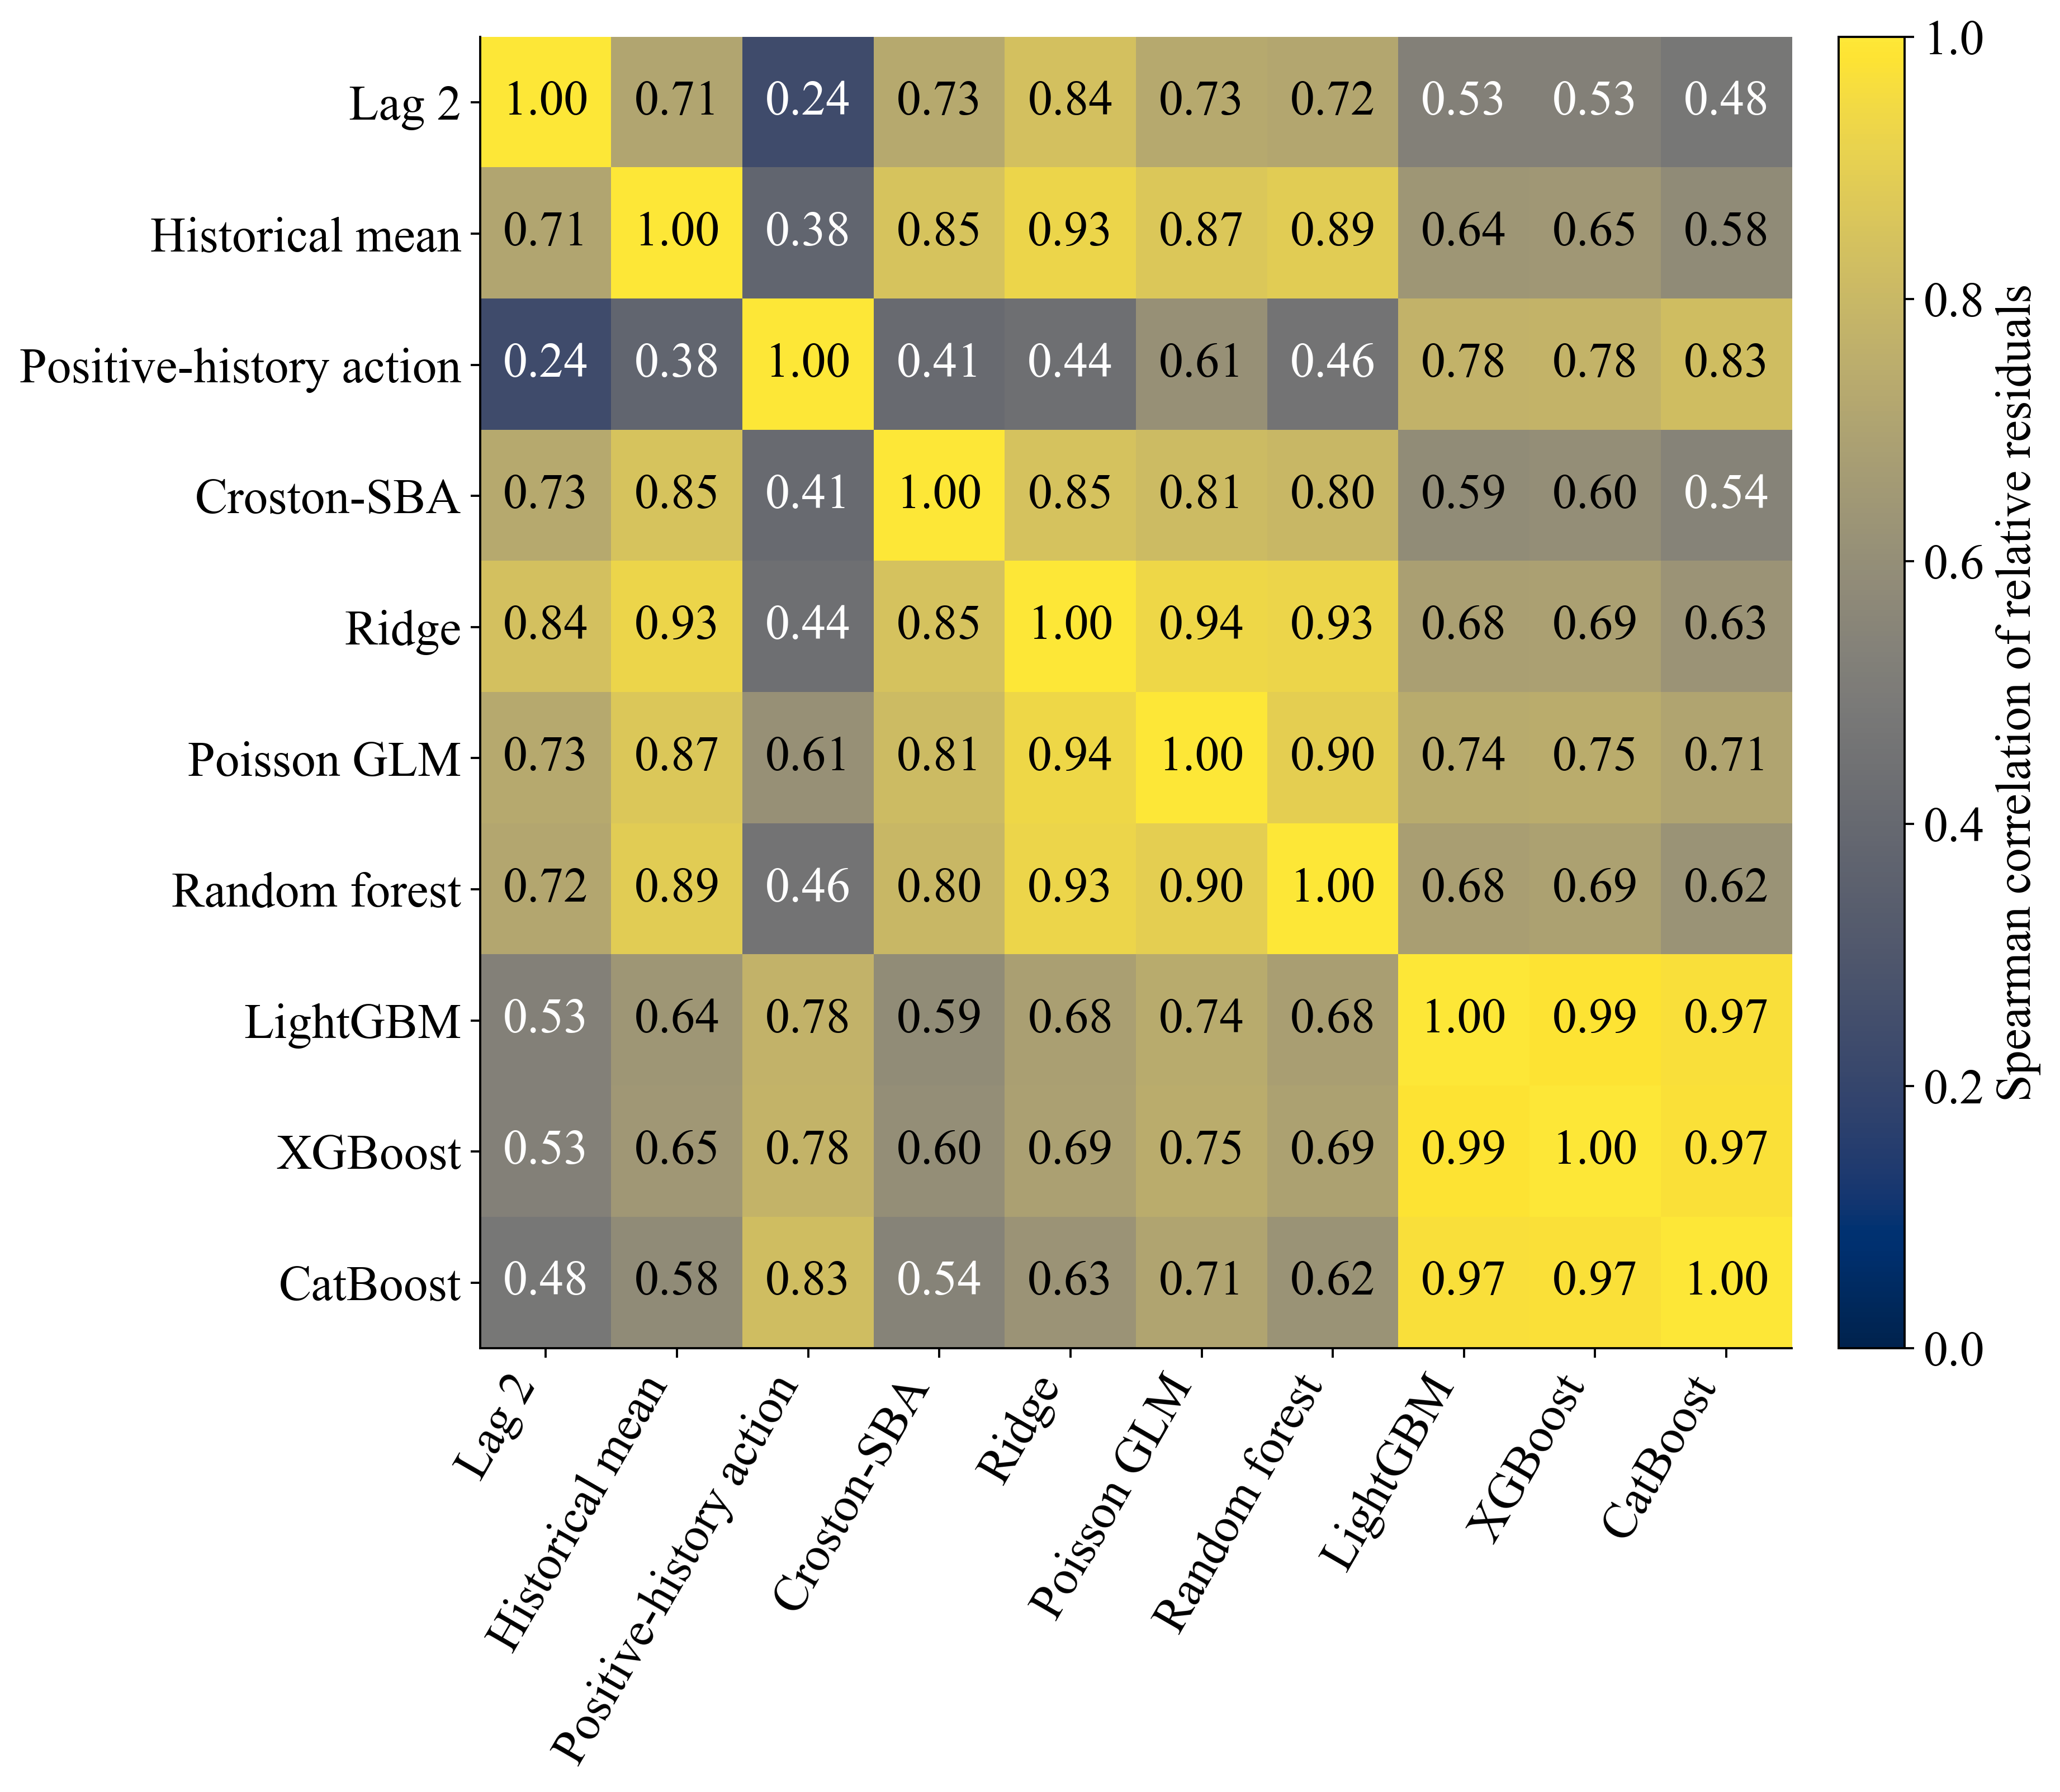

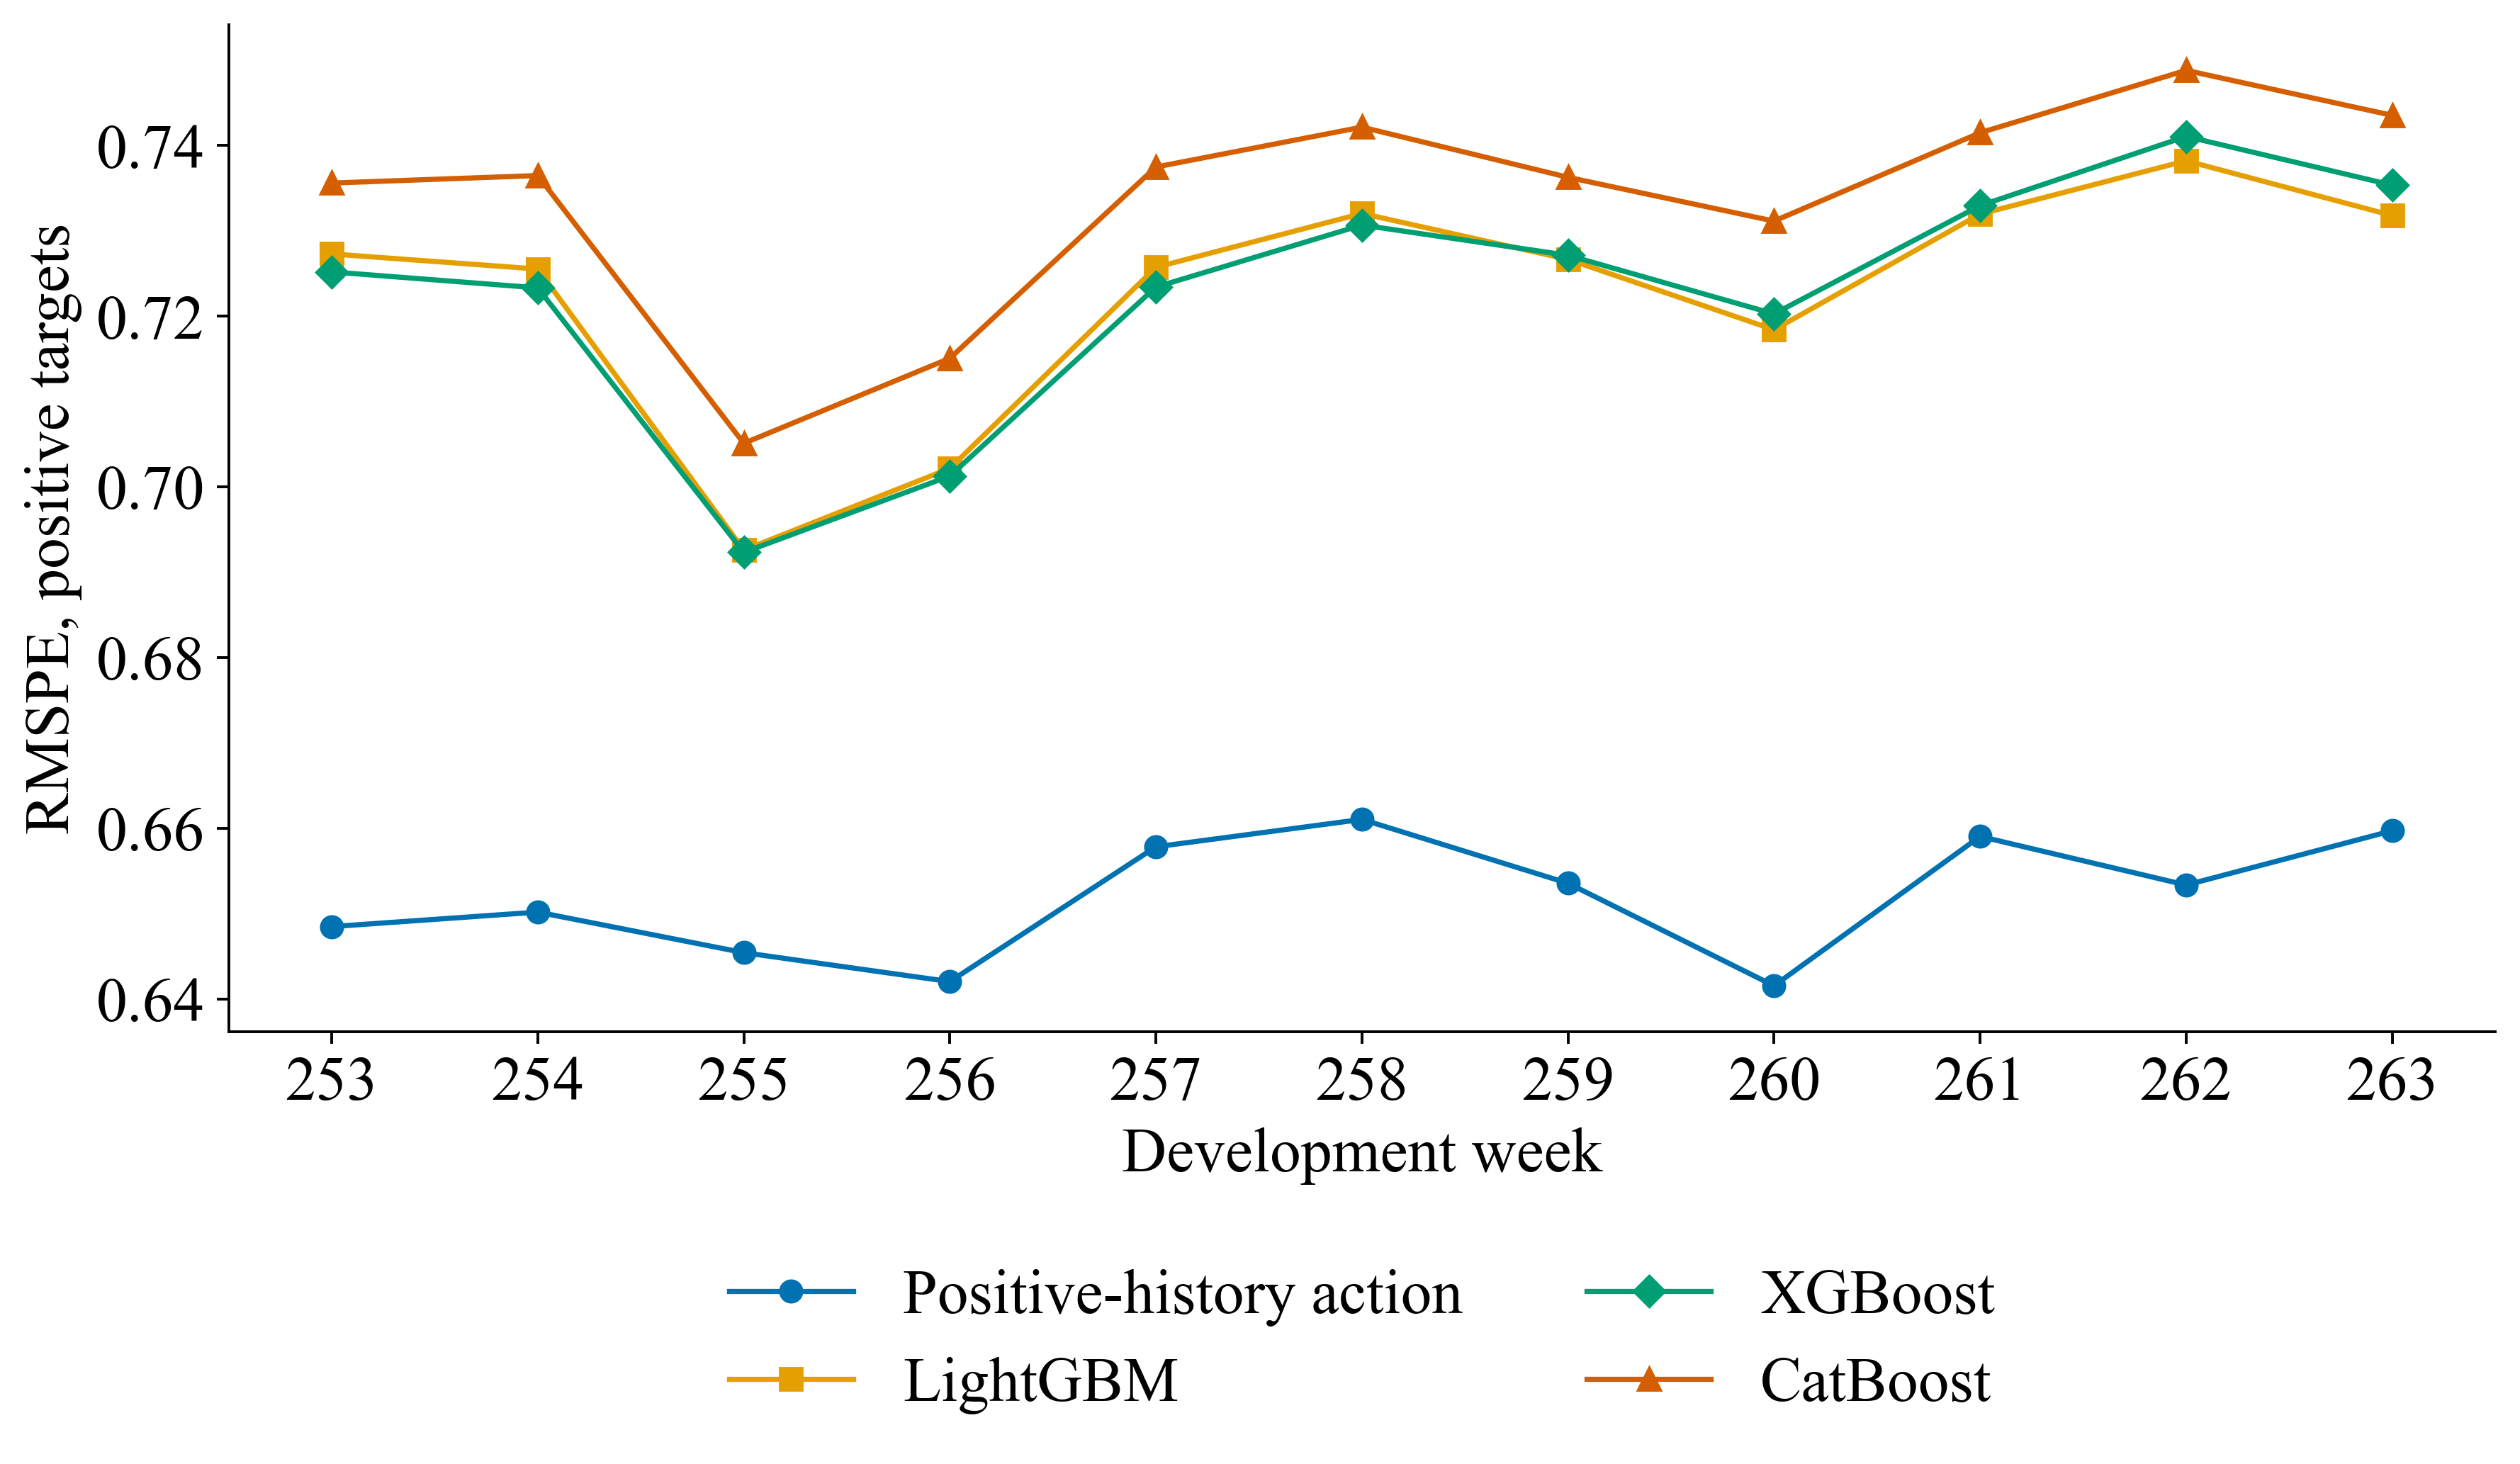

,Week,Winner,Winner RMSPE
0,253,Positive-history action,0.64849
1,254,Positive-history action,0.65019
2,255,Positive-history action,0.64544
3,256,Positive-history action,0.64205
4,257,Positive-history action,0.65784
5,258,Positive-history action,0.66105
6,259,Positive-history action,0.65357
7,260,Positive-history action,0.64156
8,261,Positive-history action,0.65906
9,262,Positive-history action,0.65336


In [12]:
# NB03_UNCERTAINTY_DIAGNOSTICS
CALIBRATORS={};uncertainty=[];q=(np.arange(257)+.5)/257
for name in MODEL_ORDER:
    nested=NESTED[name];res=(nested.quantity.to_numpy()-nested.prediction.to_numpy())/np.sqrt(nested.prediction.to_numpy()+1);grid_r=np.quantile(res,q);CALIBRATORS[name]=grid_r
    p=PREDICTIONS[(name,SEED)];cov=np.zeros(len(p));width=np.zeros(len(p));crps=np.zeros(len(p));p0=np.zeros(len(p))
    for a in range(0,len(p),100000):
        ix=slice(a,a+100000);draws=np.maximum(0,np.rint(p[ix][:,None]+np.sqrt(p[ix][:,None]+1)*grid_r[None,:]));low,high=np.quantile(draws,[.05,.95],axis=1,method='inverted_cdf')
        cov[ix]=(y[ix]>=low)&(y[ix]<=high);width[ix]=high-low;crps[ix]=np.mean(np.abs(draws-y[ix][:,None]),axis=1)-np.sum((2*np.arange(1,258)-258)*draws,axis=1)/257**2;p0[ix]=(draws==0).mean(axis=1)
    uncertainty.append({'Model':name,'PICP90':float(cov.mean()),'Coverage error':abs(float(cov.mean())-.9),'MPIW90':float(width.mean()),'CRPS':float(crps.mean()),'Zero Brier':float(np.mean((p0-(y==0))**2))})
uncertainty=pd.DataFrame(uncertainty);table(uncertainty[['Model','PICP90','Coverage error','MPIW90']],'uncertainty_coverage',['Coverage error']);table(uncertainty[['Model','CRPS','Zero Brier']],'uncertainty_scores',['CRPS','Zero Brier'])
np.savez_compressed(OUT/'nested_residual_calibrators.npz',**{str(MODEL_ORDER.index(k)):v for k,v in CALIBRATORS.items()})
positive=y>0;err=pd.DataFrame({m:(PREDICTIONS[(m,SEED)][positive]-y[positive])/y[positive] for m in MODEL_ORDER});corr=err.corr(method='spearman');corr.rename_axis('Model').reset_index().to_csv(OUT/'error_correlations_full.csv',index=False)
fig,ax=plt.subplots(figsize=(11,9.5));im=ax.imshow(corr.to_numpy(),cmap='cividis',vmin=0,vmax=1);ax.set_xticks(range(len(corr)),corr.columns,rotation=60,ha='right');ax.set_yticks(range(len(corr)),corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=18,color='white' if corr.iloc[i,j]<0.55 else 'black')
cb=fig.colorbar(im,ax=ax,fraction=0.046,pad=0.03);cb.set_label('Spearman correlation of relative residuals');fig.tight_layout();figure(fig,'fig_m5_baseline_error_correlation')
show=comparison.Model.head(4).tolist();fig,ax=plt.subplots(figsize=(10.5,6.4))
for m,col,mk in zip(show,PALETTE,'osD^'):ax.plot(weeks,weekly[m],color=col,marker=mk,label=m)
ax.set(xlabel='Development week',ylabel='RMSPE, positive targets');ax.set_xticks(weeks);ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=2,frameon=False);fig.tight_layout();figure(fig,'fig_m5_baseline_weekly')
table(pd.DataFrame({'Week':weeks,'Winner':[weekly.loc[w].idxmin() for w in weeks],'Winner RMSPE':[weekly.loc[w].min() for w in weeks]}),'weekly_winners')

In [13]:
# NB03_REGISTRY: model order and selected configurations for notebooks 04-06; run registry
manifest={'run_id':RUN_ID,'model_order':MODEL_ORDER,'selected_configurations':CONFIGS}
dump(BASE/'Manifests/baseline_manifest.json',manifest)
latest_path=BASE/'Manifests/latest_runs.json';latest=json.loads(latest_path.read_text()) if latest_path.exists() else {};latest['NB03']=RUN_ID;dump(latest_path,latest)